# IMPLEMENTASI MACHINE LEARNING UNTUK PREDIKSI KETERLAMBATAN KEBERANGKATAN PENERBANGAN

## Prediksi Keterlambatan Keberangkatan Penerbangan Berbasis Fitur Historis dan Validasi Temporal dengan Explainable Machine Learning

**Penelitian Skripsi — Program Studi Sistem Informasi**  
**Universitas Multimedia Nusantara**

**Dataset:** Flight Delay Dataset – 2024 (ATL)  
**Algoritma:** Light Gradient Boosting Machine (LightGBM)  
**Skenario:** Baseline dan Enhanced (Historical Features)  
**Horizon Prediksi:** T−2h  
**Validasi:** Temporal Split dan Walk-Forward Historical Features  
**Interpretasi:** SHapley Additive exPlanations (SHAP)  
**Deployment:** Streamlit

---

### Tujuan Implementasi

Notebook ini mendokumentasikan implementasi penelitian secara bertahap, meliputi pemahaman dan eksplorasi data, pembersihan dan prapemrosesan, rekayasa fitur historis dengan pembatasan informasi T−2h, pemodelan LightGBM, evaluasi komparatif skenario baseline dan enhanced, serta interpretasi hasil menggunakan SHAP.

### Pembagian Data Temporal

- **Training:** Januari–Agustus 2024
- **Validation:** September–Oktober 2024
- **Testing:** November–Desember 2024

### Ketentuan Metodologis

Seluruh fitur prediktor harus memenuhi asumsi ketersediaan informasi pada horizon T−2h. Pembentukan fitur historis dilakukan menggunakan catatan penerbangan terdahulu yang telah memenuhi batas waktu informasi, tanpa menggunakan hasil penerbangan target atau informasi masa depan. Dataset pengujian tidak digunakan untuk pelatihan ulang, optimasi hiperparameter, maupun pemilihan ambang klasifikasi.

---

# BAB IV — HASIL DAN PEMBAHASAN

## 4.1 Pemahaman dan Eksplorasi Data (Data Understanding & EDA)

### 4.1.1 Analisis Profil dan Hasil Seleksi Dataset Penerbangan 2024

In [41]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Memuat data utuh; df_raw tidak dimodifikasi setelah pembacaan.
df_raw = pd.read_csv('flight_data_2024_origin_ATL.csv')
display(df_raw.head())

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,dest,dest_city_name,dest_state_nm,crs_dep_time,dep_time,dep_delay,taxi_out,wheels_off,wheels_on,taxi_in,crs_arr_time,arr_time,arr_delay,cancelled,cancellation_code,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4858.0,ATL,"Atlanta, GA",Georgia,TLH,"Tallahassee, FL",Florida,920,915.0,-5.0,22.0,937.0,1020.0,3.0,1029,1023.0,-6.0,0,NaN,0,69.0,68.0,43.0,223.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4910.0,ATL,"Atlanta, GA",Georgia,DHN,"Dothan, AL",Alabama,1355,1352.0,-3.0,17.0,1409.0,1343.0,5.0,1401,1348.0,-13.0,0,NaN,0,66.0,56.0,34.0,170.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4923.0,ATL,"Atlanta, GA",Georgia,TYS,"Knoxville, TN",Tennessee,1345,1342.0,-3.0,13.0,1355.0,1426.0,6.0,1443,1432.0,-11.0,0,NaN,0,58.0,50.0,31.0,152.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4930.0,ATL,"Atlanta, GA",Georgia,XNA,"Fayetteville, AR",Arkansas,2100,2046.0,-14.0,38.0,2124.0,2152.0,6.0,2204,2158.0,-6.0,0,NaN,0,124.0,132.0,88.0,589.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4933.0,ATL,"Atlanta, GA",Georgia,TYS,"Knoxville, TN",Tennessee,900,856.0,-4.0,11.0,907.0,937.0,4.0,1002,941.0,-21.0,0,NaN,0,62.0,45.0,30.0,152.0,0,0,0,0,0


### Profil awal: jumlah observasi, atribut dan tipe data
Pemeriksaan dilakukan terhadap dimensi dataset serta tipe data setiap atribut. Hasilnya menjadi dasar untuk mengevaluasi kesesuaian struktur berkas dengan Bab III.

In [42]:
# Menentukan dimensi dan daftar atribut dataset sumber.
n_raw, n_columns = df_raw.shape
print(f"Jumlah observasi : {n_raw:,}")
print(f"Jumlah atribut   : {n_columns}")
print("Daftar atribut:")
display(pd.DataFrame({"Atribut": df_raw.columns, "Tipe Data": df_raw.dtypes.astype(str).values}))

# Pemeriksaan jumlah data terhadap keterangan pada Bab III.
assert n_raw == 341_910, f"Observasi diterima {n_raw:,}, bukan 341.910"

# Informasi ringkas termasuk non-null dan penggunaan memori.
df_raw.info()

Jumlah observasi : 341,910
Jumlah atribut   : 35
Daftar atribut:


,Atribut,Tipe Data
0,year,int64
1,month,int64
2,day_of_month,int64
3,day_of_week,int64
4,fl_date,str
5,op_unique_carrier,str
6,op_carrier_fl_num,float64
7,origin,str
8,origin_city_name,str
9,origin_state_nm,str


<class 'pandas.DataFrame'>
RangeIndex: 341910 entries, 0 to 341909
Data columns (total 35 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 341910 non-null  int64  
 1   month                341910 non-null  int64  
 2   day_of_month         341910 non-null  int64  
 3   day_of_week          341910 non-null  int64  
 4   fl_date              341910 non-null  str    
 5   op_unique_carrier    341910 non-null  str    
 6   op_carrier_fl_num    341910 non-null  float64
 7   origin               341910 non-null  str    
 8   origin_city_name     341910 non-null  str    
 9   origin_state_nm      341910 non-null  str    
 10  dest                 341910 non-null  str    
 11  dest_city_name       341910 non-null  str    
 12  dest_state_nm        341910 non-null  str    
 13  crs_dep_time         341910 non-null  int64  
 14  dep_time             338591 non-null  float64
 15  dep_delay            338589 

### Audit missing values dan duplikasi
Menghitung nilai kosong seluruh atribut dan menyoroti variabel penelitian. Duplikasi yang diperiksa meliputi duplikasi baris identik dan pengulangan kombinasi kunci operasional. Tahap ini hanya mengaudit, belum menghapus nilai atau observasi.

In [43]:
# Melaporkan jumlah dan persentase nilai kosong seluruh atribut.
missing_table = pd.DataFrame({
    "Atribut": df_raw.columns,
    "Jumlah Missing": df_raw.isna().sum().values,
    "Persentase (%)": (df_raw.isna().mean().values * 100).round(2)
}).sort_values(["Jumlah Missing", "Atribut"], ascending=[False, True]).reset_index(drop=True)
display(missing_table)

# Menampilkan nilai kosong khusus atribut inti penelitian.
core_columns = ["fl_date", "op_unique_carrier", "dest", "crs_dep_time",
                "distance", "crs_elapsed_time", "cancelled", "dep_delay"]
assert set(core_columns).issubset(df_raw.columns), "Kolom inti penelitian tidak lengkap"
display(missing_table.loc[missing_table["Atribut"].isin(core_columns)].reset_index(drop=True))

# Menghitung duplikasi identik dan duplikasi kombinasi identitas penerbangan.
n_exact_duplicates = int(df_raw.duplicated().sum())
identity_columns = ["fl_date", "op_unique_carrier", "op_carrier_fl_num",
                    "origin", "dest", "crs_dep_time"]
n_key_duplicates = int(df_raw.duplicated(subset=identity_columns).sum())
print(f"Duplikasi baris identik     : {n_exact_duplicates:,}")
print(f"Duplikasi kunci operasional : {n_key_duplicates:,}")
assert n_exact_duplicates == 0, "Duplikasi identik ditemukan; periksa sebelum seleksi"
assert n_key_duplicates == 0, "Duplikasi kunci operasional ditemukan; perlu pemeriksaan"

,Atribut,Jumlah Missing,Persentase (%)
0,cancellation_code,338500,99.00
1,actual_elapsed_time,4248,1.24
2,air_time,4248,1.24
3,arr_delay,4248,1.24
4,arr_time,3482,1.02
5,taxi_in,3482,1.02
6,wheels_on,3482,1.02
7,taxi_out,3388,0.99
8,wheels_off,3388,0.99
9,dep_delay,3321,0.97


,Atribut,Jumlah Missing,Persentase (%)
0,dep_delay,3321,0.97
1,cancelled,0,0.00
2,crs_dep_time,0,0.00
3,crs_elapsed_time,0,0.00
4,dest,0,0.00
5,distance,0,0.00
6,fl_date,0,0.00
7,op_unique_carrier,0,0.00


Duplikasi baris identik     : 0
Duplikasi kunci operasional : 0


### Periode, konsistensi tanggal, maskapai, dan destinasi
Tanggal diparsing secara eksplisit. Kolom year, month, day_of_month dan day_of_week dibandingkan dengan fl_date; pada data BTS, hari Senin bernilai 1. Diperiksa juga validitas jam keberangkatan terjadwal dalam format HHMM serta konsistensi origin.

In [44]:
# Mem-parsing tanggal secara ketat; kesalahan diubah menjadi NaT untuk dihitung.
raw_date = pd.to_datetime(df_raw["fl_date"], format="%Y-%m-%d", errors="coerce")
n_invalid_date = int(raw_date.isna().sum())
print(f"Tanggal invalid : {n_invalid_date:,}")
assert n_invalid_date == 0, "Ditemukan fl_date tidak valid"

# Memverifikasi rentang periode sumber dan cakupan bandara asal.
min_date, max_date = raw_date.min(), raw_date.max()
n_origin_invalid = int(df_raw["origin"].ne("ATL").sum())
print(f"Rentang tanggal : {min_date:%Y-%m-%d} hingga {max_date:%Y-%m-%d}")
print(f"Origin bukan ATL: {n_origin_invalid:,}")
assert min_date == pd.Timestamp("2024-01-01")
assert max_date == pd.Timestamp("2024-12-31")
assert raw_date.dt.year.eq(2024).all()
assert n_origin_invalid == 0

# Membandingkan atribut kalender dengan tanggal terparsing.
calendar_checks = {
    "year": raw_date.dt.year,
    "month": raw_date.dt.month,
    "day_of_month": raw_date.dt.day,
    "day_of_week": raw_date.dt.dayofweek + 1,  # BTS: Senin=1 s.d. Minggu=7
}
calendar_mismatch = {
    col: int(pd.to_numeric(df_raw[col], errors="coerce").ne(expected).sum())
    for col, expected in calendar_checks.items()
}
print("Ketidaksesuaian atribut kalender:", calendar_mismatch)
assert all(count == 0 for count in calendar_mismatch.values())

# Memvalidasi format HHMM untuk waktu keberangkatan terjadwal.
scheduled_hhmm = pd.to_numeric(df_raw["crs_dep_time"], errors="coerce")
hours = scheduled_hhmm // 100
minutes = scheduled_hhmm % 100
valid_hhmm = (scheduled_hhmm.notna() & (hours >= 0) & (hours <= 23)
              & (minutes >= 0) & (minutes <= 59))
print(f"Jadwal keberangkatan HHMM tidak valid: {int((~valid_hhmm).sum()):,}")
assert valid_hhmm.all()

# Menghitung jumlah kode maskapai dan bandara tujuan unik.
n_carriers = int(df_raw["op_unique_carrier"].nunique(dropna=True))
n_destinations = int(df_raw["dest"].nunique(dropna=True))
print(f"Kode maskapai unik : {n_carriers:,}")
print(f"Kode destinasi unik: {n_destinations:,}")
assert n_carriers == 13, "Jumlah maskapai tidak sesuai Bab III"
assert n_destinations == 157, "Jumlah destinasi tidak sesuai Bab III"

Tanggal invalid : 0
Rentang tanggal : 2024-01-01 hingga 2024-12-31
Origin bukan ATL: 0
Ketidaksesuaian atribut kalender: {'year': 0, 'month': 0, 'day_of_month': 0, 'day_of_week': 0}
Jadwal keberangkatan HHMM tidak valid: 0
Kode maskapai unik : 13
Kode destinasi unik: 157


### Identifikasi pembatalan dan validitas label keterlambatan
Definisi dibatalkan mengikuti cancelled == 1. Nilai dep_delay kosong/tidak numerik diperiksa secara terpisah, karena tidak seluruh observasi yang dibatalkan memiliki label kosong. Menggunakan gabungan pembatalan dan label tidak valid tanpa pemeriksaan berisiko menghitung kelompok yang sama dua kali.

In [45]:
# Memastikan cancelled memiliki status biner (0=tidak dibatalkan, 1=dibatalkan).
cancelled_numeric = pd.to_numeric(df_raw["cancelled"], errors="coerce")
assert cancelled_numeric.notna().all() and cancelled_numeric.isin([0, 1]).all()
is_cancelled = cancelled_numeric.eq(1)

# Nilai negatif dep_delay tetap sah (keberangkatan lebih awal).
# Hanya nilai nonnumerik, kosong, atau tak hingga yang dinyatakan tidak valid.
delay_numeric = pd.to_numeric(df_raw["dep_delay"], errors="coerce")
valid_dep_delay = delay_numeric.notna() & np.isfinite(delay_numeric)

# Menghitung kategori yang mungkin saling beririsan.
n_cancelled = int(is_cancelled.sum())
n_missing_dep_delay = int(df_raw["dep_delay"].isna().sum())
n_invalid_delay = int((~valid_dep_delay).sum())
n_cancelled_valid_delay = int((is_cancelled & valid_dep_delay).sum())
n_noncancelled_invalid_delay = int((~is_cancelled & ~valid_dep_delay).sum())
print(f"Dibatalkan (cancelled=1)                   : {n_cancelled:,}")
print(f"dep_delay kosong                          : {n_missing_dep_delay:,}")
print(f"dep_delay tidak valid (termasuk kosong)   : {n_invalid_delay:,}")
print(f"Dibatalkan tetapi dep_delay valid         : {n_cancelled_valid_delay:,}")
print(f"Tidak dibatalkan tetapi dep_delay invalid : {n_noncancelled_invalid_delay:,}")

# Tabel silang membantu memeriksa kemungkinan perhitungan ganda.
status_table = pd.crosstab(
    is_cancelled.map({False: "Tidak dibatalkan", True: "Dibatalkan"}),
    valid_dep_delay.map({False: "Delay tidak valid", True: "Delay valid"}),
    margins=True
)
display(status_table)

# Konfirmasi angka yang tercantum dalam Bab III.
assert n_cancelled == 3_410, "Jumlah pembatalan tidak sesuai Bab III"
assert n_noncancelled_invalid_delay == 0, (
    "Ada penerbangan tidak dibatalkan tanpa label valid; hasil seleksi perlu ditinjau"
)

Dibatalkan (cancelled=1)                   : 3,410
dep_delay kosong                          : 3,321
dep_delay tidak valid (termasuk kosong)   : 3,321
Dibatalkan tetapi dep_delay valid         : 89
Tidak dibatalkan tetapi dep_delay invalid : 0


dep_delay,Delay tidak valid,Delay valid,All
cancelled,,,
Dibatalkan,3321,89,3410
Tidak dibatalkan,0,338500,338500
All,3321,338589,341910


### Seleksi akhir data bersih (df_clean)
Mempertahankan penerbangan tidak dibatalkan dengan dep_delay numerik yang valid. Tahap ini belum melakukan pemodelan, imputasi fitur, pembentukan label biner, ataupun penanganan outlier. Nilai negatif dep_delay tidak dihapus.

In [46]:
# Menyeleksi baris berdasarkan status dan validitas dep_delay.
eligible = (~is_cancelled) & valid_dep_delay
df_clean = df_raw.loc[eligible].copy()

# Menetapkan tipe tanggal dan dep_delay pada salinan, tanpa mengubah df_raw.
df_clean["fl_date"] = raw_date.loc[eligible]
df_clean["dep_delay"] = delay_numeric.loc[eligible]

# Mengurutkan tanggal secara stabil dan memberi indeks baru.
df_clean = df_clean.sort_values("fl_date", kind="stable").reset_index(drop=True)
n_clean = len(df_clean)
n_removed = n_raw - n_clean
print(f"Jumlah awal             : {n_raw:,}")
print(f"Jumlah yang dikeluarkan : {n_removed:,}")
print(f"Jumlah bersih           : {n_clean:,}")

# Menjamin konsistensi hasil seleksi terhadap Bab III.
assert n_removed == 3_410
assert n_clean == 338_500
assert df_clean["fl_date"].notna().all()
assert df_clean["dep_delay"].notna().all()
assert np.isfinite(df_clean["dep_delay"]).all()
assert (pd.to_numeric(df_clean["cancelled"]) == 0).all()
print("Seleksi data terverifikasi.")

Jumlah awal             : 341,910
Jumlah yang dikeluarkan : 3,410
Jumlah bersih           : 338,500
Seleksi data terverifikasi.


### Tabel 4.1 — Ringkasan Profil dan Hasil Seleksi Dataset ATL Tahun 2024
Tabel 4.1 memisahkan populasi berkas awal, jumlah pembatalan, dan jumlah observasi yang layak digunakan. Nilai diturunkan dari data aktual, bukan ditulis manual.

In [47]:
# Menyiapkan Tabel 4.1 yang dapat langsung diekspor.
tabel_4_1 = pd.DataFrame({
    "Tahap Seleksi": [
        "Dataset ATL yang diterima",
        "Observasi dibatalkan",
        "Observasi akhir untuk pemodelan",
    ],
    "Jumlah Observasi": [n_raw, n_cancelled, n_clean]
})
print("Tabel 4.1 Ringkasan Profil dan Hasil Seleksi Dataset ATL Tahun 2024")
display(tabel_4_1)

Tabel 4.1 Ringkasan Profil dan Hasil Seleksi Dataset ATL Tahun 2024


,Tahap Seleksi,Jumlah Observasi
0,Dataset ATL yang diterima,341910
1,Observasi dibatalkan,3410
2,Observasi akhir untuk pemodelan,338500


### Pembagian data temporal (df_train, df_val, df_test)
Partisi dibuat berdasarkan fl_date, bukan acak. Pembagian ini sama untuk kedua skenario LightGBM. Pada tahap 4.1.1, pembagian tanggal tidak sama dengan pembentukan fitur historis T−2h; hal tersebut diterapkan pada tahap rekayasa fitur berikutnya.

In [48]:
# Menentukan batas tanggal masing-masing partisi.
date = df_clean["fl_date"]
train_mask = date.between("2024-01-01", "2024-08-31")
val_mask = date.between("2024-09-01", "2024-10-31")
test_mask = date.between("2024-11-01", "2024-12-31")

# Setiap baris harus masuk tepat satu partisi.
partition_membership = (train_mask.astype("int8") + val_mask.astype("int8")
                        + test_mask.astype("int8"))
assert partition_membership.eq(1).all(), "Ada tumpang tindih atau baris di luar partisi"

# Menyimpan partisi sebagai salinan terpisah.
df_train = df_clean.loc[train_mask].copy()
df_val = df_clean.loc[val_mask].copy()
df_test = df_clean.loc[test_mask].copy()
n_train, n_val, n_test = len(df_train), len(df_val), len(df_test)

# Menguji kelengkapan, eksklusivitas indeks, dan kronologi tanggal.
assert n_train + n_val + n_test == n_clean
assert df_train.index.intersection(df_val.index).empty
assert df_train.index.intersection(df_test.index).empty
assert df_val.index.intersection(df_test.index).empty
assert df_train["fl_date"].max() < df_val["fl_date"].min()
assert df_val["fl_date"].max() < df_test["fl_date"].min()

for name, part in [("Training", df_train), ("Validation", df_val), ("Testing", df_test)]:
    print(f"{name:10s}: {len(part):>7,} | "
          f"{part['fl_date'].min():%Y-%m-%d} s.d. {part['fl_date'].max():%Y-%m-%d}")
print("Validasi temporal berhasil.")

Training  : 223,971 | 2024-01-01 s.d. 2024-08-31
Validation:  57,593 | 2024-09-01 s.d. 2024-10-31
Testing   :  56,936 | 2024-11-01 s.d. 2024-12-31
Validasi temporal berhasil.


### Tabel 4.2 — Distribusi Observasi Berdasarkan Pembagian Data Temporal
Jumlah observasi dan persentase diturunkan dari df_clean. Persentase dibulatkan menjadi dua desimal hanya untuk pelaporan, sedangkan pemeriksaan total menggunakan nilai sebelum pembulatan.

In [49]:
# Menghitung proporsi terhadap jumlah observasi bersih.
period_counts = [n_train, n_val, n_test]
period_percentages = [count / n_clean * 100 for count in period_counts]
assert np.isclose(sum(period_percentages), 100.0)

# Membentuk tabel termasuk baris total.
tabel_4_2 = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing", "Total"],
    "Periode 2024": ["Januari–Agustus", "September–Oktober",
                     "November–Desember", "Januari–Desember"],
    "Jumlah Observasi": [*period_counts, n_clean],
    "Proporsi (%)": [*period_percentages, 100.0],
})
print("Tabel 4.2 Distribusi Observasi Berdasarkan Pembagian Data Temporal")

tabel_4_2["Proporsi (%)"] = tabel_4_2["Proporsi (%)"].round(2)
display(tabel_4_2)

# Memastikan jumlah tetap sesuai data bersih.
assert tabel_4_2.loc[:2, "Jumlah Observasi"].sum() == n_clean

Tabel 4.2 Distribusi Observasi Berdasarkan Pembagian Data Temporal


,Dataset,Periode 2024,Jumlah Observasi,Proporsi (%)
0,Training,Januari–Agustus,223971,66.17
1,Validation,September–Oktober,57593,17.01
2,Testing,November–Desember,56936,16.82
3,Total,Januari–Desember,338500,100.00


### Ekspor tabel dan ringkasan akhir 4.1.1
Ekspor kedua tabel ke CSV dengan encoding UTF-8 BOM supaya nyaman dibuka pada Excel. Dataset bersih tidak perlu ditulis ulang kecuali diperlukan; ketiga partisi tetap tersedia dalam memori untuk tahapan berikutnya.

In [50]:
# Menentukan direktori keluaran untuk hasil yang dapat dirujuk pada Bab IV.
OUTPUT_DIR = Path("output_4_1_1")
OUTPUT_DIR.mkdir(exist_ok=True)

tabel_4_1.to_csv(OUTPUT_DIR / "Tabel_4_1_Ringkasan_Seleksi.csv",
                   index=False, encoding="utf-8-sig")
tabel_4_2.to_csv(OUTPUT_DIR / "Tabel_4_2_Pembagian_Temporal.csv",
                   index=False, encoding="utf-8-sig")

print("4.1.1 selesai dan terverifikasi.")
print(f"Data awal: {n_raw:,} | Dibatalkan: {n_cancelled:,} | Bersih: {n_clean:,}")
print(f"Training: {n_train:,} | Validation: {n_val:,} | Testing: {n_test:,}")
print(f"Tabel diekspor ke: {OUTPUT_DIR.resolve()}")
print("Objek tersedia: df_raw, df_clean, df_train, df_val, df_test, tabel_4_1, tabel_4_2")

4.1.1 selesai dan terverifikasi.
Data awal: 341,910 | Dibatalkan: 3,410 | Bersih: 338,500
Training: 223,971 | Validation: 57,593 | Testing: 56,936
Tabel diekspor ke: C:\Users\Lenovo\Documents\Skripsi\output_4_1_1
Objek tersedia: df_raw, df_clean, df_train, df_val, df_test, tabel_4_1, tabel_4_2


## 4.1.2 Analisis Distribusi Variabel dan Ketidakseimbangan Kelas (Class Imbalance Analysis)

In [51]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display
from pathlib import Path

# Menampilkan seluruh baris, kolom, dan isi teks pada sel Pandas.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)
pd.set_option("display.expand_frame_repr", False)

# Fungsi pembantu agar sel yang panjang ditampilkan lengkap dan dibungkus.
def tampilan_tabel(dataframe):
    return dataframe.style.set_properties(**{
        "white-space": "normal",
        "overflow-wrap": "break-word",
        "text-align": "left"
    })

# Gunakan df_clean dari 4.1.1 bila sudah tersedia.
# Jika tidak, ulangi seleksi sederhana dari sumber yang sama.
if "df_clean" not in globals():
    if "df_raw" not in globals():
        DATA_PATH = Path("flight_data_2024_origin_ATL(1).xls")
        assert DATA_PATH.exists(), f"File dataset tidak ditemukan: {DATA_PATH}"
        # File .xls yang diunggah berisi teks CSV, bukan workbook Excel.
        df_raw = pd.read_csv(DATA_PATH, low_memory=False)

    raw_status = pd.to_numeric(df_raw["cancelled"], errors="coerce")
    raw_delay = pd.to_numeric(df_raw["dep_delay"], errors="coerce")
    assert raw_status.notna().all() and raw_status.isin([0, 1]).all()
    valid_raw_delay = raw_delay.notna() & np.isfinite(raw_delay)
    df_clean = df_raw.loc[raw_status.eq(0) & valid_raw_delay].copy()

# Buat salinan khusus EDA agar variabel dan pipeline bagian lain tidak berubah.
df_eda = df_clean.copy()
df_eda["fl_date"] = pd.to_datetime(df_eda["fl_date"], errors="raise")
df_eda["dep_delay"] = pd.to_numeric(df_eda["dep_delay"], errors="raise")

# Validasi jumlah dan periode dasar sebelum eksplorasi.
assert len(df_eda) == 338_500, f"Jumlah data bersih: {len(df_eda):,}"
assert df_eda["fl_date"].dt.year.eq(2024).all()
assert df_eda["dep_delay"].notna().all() and np.isfinite(df_eda["dep_delay"]).all()

# Folder keluaran tabel dan gambar beresolusi tinggi.
OUTPUT_DIR = Path("output_4_1_2_revisi")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Folder ekspor tabel pada Windows sesuai kebutuhan penulisan skripsi.
WINDOWS_TABLE_DIR = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN"
    r"\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data"
)

# Menghindari pembuatan folder C:\ palsu bila notebook dieksekusi di Linux/macOS.
TABLE_DIR = (
    WINDOWS_TABLE_DIR if sys.platform.startswith("win")
    else OUTPUT_DIR / "Tabel Data"
)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Ekspor ganda: CSV untuk data mentah dan HTML agar mudah dicopy ke Word.
def ekspor_tabel(df, nama_file, judul):
    file_csv = TABLE_DIR / f"{nama_file}.csv"
    file_html = TABLE_DIR / f"{nama_file}.html"
    df.to_csv(file_csv, index=False, encoding="utf-8-sig")
    isi_html = df.to_html(index=False, border=0, escape=True)
    css = """<style>
    body {font-family:Arial,sans-serif; font-size:11pt;}
    table {border-collapse:collapse; width:100%;}
    th,td {border:1px solid #999; padding:7px 10px; white-space:normal;
           overflow-wrap:break-word; text-align:left; vertical-align:top;}
    th {background:#e8eef5; font-weight:bold;}
    </style>"""
    file_html.write_text(
        f"<!doctype html><html><head><meta charset='utf-8'>{css}</head>"
        f"<body><p><strong>{judul}</strong></p>{isi_html}</body></html>",
        encoding="utf-8"
    )
    print(f"Tabel disimpan: {file_csv}")
    print(f"Versi Word-friendly: {file_html}")

print(f"Direktori ekspor tabel: {TABLE_DIR}")

# Menambahkan label untuk teks output yang rapi.
def format_angka(nilai):
    return f"{int(nilai):,}".replace(",", ".")

print(f"Data tersedia untuk analisis: {format_angka(len(df_eda))} observasi")
print(f"Periode: {df_eda['fl_date'].min():%d-%m-%Y} s.d. {df_eda['fl_date'].max():%d-%m-%Y}")

Direktori ekspor tabel: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data
Data tersedia untuk analisis: 338.500 observasi
Periode: 01-01-2024 s.d. 31-12-2024


### Pembentukan Target dan Pemeriksaan Ketidakseimbangan Kelas
Bentuk label berdasarkan ambang 15 menit, periksa hitungan kelas, dan hitung rasio On-Time terhadap Delayed. Distribusi ini akan ditampilkan hanya sebagai Gambar 4.1, bukan sebagai tabel terpisah.

In [52]:
# Membentuk label biner: 0 = On-Time, 1 = Delayed.
df_eda["is_delayed"] = (df_eda["dep_delay"] >= 15).astype("int8")
df_eda["kelas_keterlambatan"] = pd.Categorical(
    np.where(df_eda["is_delayed"].eq(1), "Delayed", "On-Time"),
    categories=["On-Time", "Delayed"],
    ordered=True
)

# Menghitung jumlah dan proporsi kelas tanpa mengubah df_clean.
jumlah_kelas = df_eda["kelas_keterlambatan"].value_counts(sort=False)
ringkasan_kelas = pd.DataFrame({
    "Kelas": ["On-Time", "Delayed"],
    "Kode Target": [0, 1],
    "Jumlah Observasi": [int(jumlah_kelas["On-Time"]), int(jumlah_kelas["Delayed"])],
})
ringkasan_kelas["Proporsi (%)"] = (
    ringkasan_kelas["Jumlah Observasi"] / len(df_eda) * 100
).round(2)

# Memverifikasi nilai distribusi awal yang dinyatakan dalam Bab III.
assert int(jumlah_kelas["On-Time"]) == 271_680
assert int(jumlah_kelas["Delayed"]) == 66_820
assert ringkasan_kelas["Jumlah Observasi"].sum() == len(df_eda)

# Data ringkasan disimpan dalam DataFrame untuk grafik, tanpa ditampilkan sebagai tabel.
print("Distribusi kelas terverifikasi:"
      f" On-Time={format_angka(int(jumlah_kelas['On-Time']))};"
      f" Delayed={format_angka(int(jumlah_kelas['Delayed']))}")

# Rasio ketidakseimbangan dan AP acuan berdasarkan prevalensi kelas positif.
rasio_kelas = jumlah_kelas["On-Time"] / jumlah_kelas["Delayed"]
prevalensi_delayed = jumlah_kelas["Delayed"] / len(df_eda)
print(f"Rasio On-Time : Delayed = {rasio_kelas:.2f} : 1")
print(f"Prevalensi Delayed / nilai acuan AP tanpa daya diskriminasi = {prevalensi_delayed:.4f}")
print("Nilai acuan ini BUKAN hasil evaluasi model.")

Distribusi kelas terverifikasi: On-Time=271.680; Delayed=66.820
Rasio On-Time : Delayed = 4.07 : 1
Prevalensi Delayed / nilai acuan AP tanpa daya diskriminasi = 0.1974
Nilai acuan ini BUKAN hasil evaluasi model.


### Gambar 4.1 — Distribusi Kelas On-Time dan Delayed
Diagram batang menunjukkan besaran kelas mayoritas dan minoritas dengan anotasi jumlah dan persentase.

Gambar 4.1 Distribusi Kelas On-Time dan Delayed


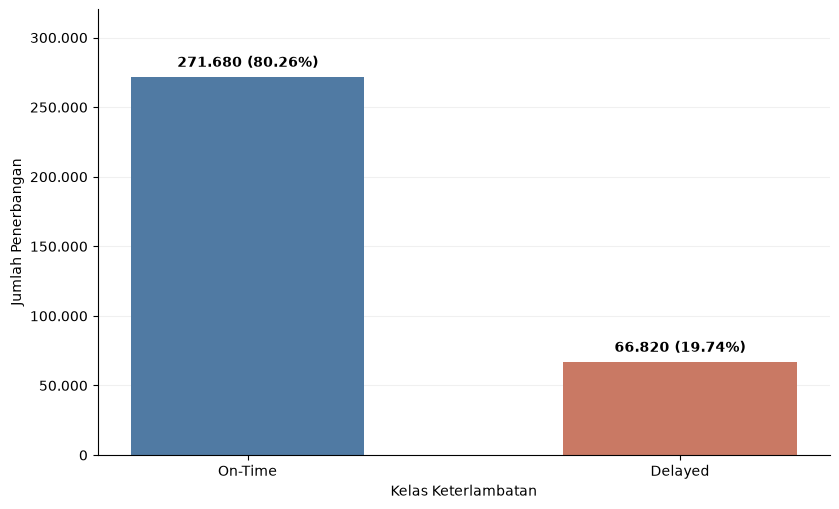

In [53]:
# Membuat diagram batang distribusi kelas dan menyimpan PNG 300 dpi.
fig, ax = plt.subplots(figsize=(8.5, 5.2))
bars = ax.bar(
    ringkasan_kelas["Kelas"], ringkasan_kelas["Jumlah Observasi"],
    color=["#507AA3", "#C97964"], width=0.54
)
for bar, n, persen in zip(
    bars, ringkasan_kelas["Jumlah Observasi"], ringkasan_kelas["Proporsi (%)"]
):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
            f"{format_angka(n)} ({persen:.2f}%)",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("Jumlah Penerbangan")
ax.set_xlabel("Kelas Keterlambatan")
ax.set_ylim(0, ringkasan_kelas["Jumlah Observasi"].max() * 1.18)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: format_angka(x)))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Gambar_4_1_Distribusi_Kelas.png", dpi=300, bbox_inches="tight")
print("Gambar 4.1 Distribusi Kelas On-Time dan Delayed")
plt.show()
plt.close(fig)

### Distribusi Jumlah Penerbangan Berdasarkan Bulan
Bulan diperoleh dari fl_date. Selain jumlah penerbangan, ditampilkan jumlah dan tingkat Delayed sebagai informasi deskriptif pendukung.

In [54]:
# Mengekstraksi bulan dari tanggal penerbangan.
df_eda["bulan"] = df_eda["fl_date"].dt.month
nama_bulan = {
    1: "Januari", 2: "Februari", 3: "Maret", 4: "April",
    5: "Mei", 6: "Juni", 7: "Juli", 8: "Agustus",
    9: "September", 10: "Oktober", 11: "November", 12: "Desember"
}

# Menghitung jumlah penerbangan dan kelas Delayed untuk setiap bulan.
ringkasan_bulanan = (
    df_eda.groupby("bulan", sort=True)["is_delayed"]
    .agg(Jumlah_Penerbangan="size", Jumlah_Delayed="sum")
    .reset_index()
)
ringkasan_bulanan["Bulan"] = ringkasan_bulanan["bulan"].map(nama_bulan)
ringkasan_bulanan["Tingkat Delayed (%)"] = (
    ringkasan_bulanan["Jumlah_Delayed"] / ringkasan_bulanan["Jumlah_Penerbangan"] * 100
).round(2)
ringkasan_bulanan = ringkasan_bulanan.rename(columns={
    "Jumlah_Penerbangan": "Jumlah Penerbangan",
    "Jumlah_Delayed": "Jumlah Delayed"
})[["bulan", "Bulan", "Jumlah Penerbangan", "Jumlah Delayed", "Tingkat Delayed (%)"]]

# Memastikan setiap bulan tersedia dan seluruh observasi tercakup.
assert ringkasan_bulanan["bulan"].tolist() == list(range(1, 13))
assert ringkasan_bulanan["Jumlah Penerbangan"].sum() == len(df_eda)
assert ringkasan_bulanan["Jumlah Delayed"].sum() == 66_820

# Hanya menampilkan temuan ringkas; rincian jumlah divisualisasikan di Gambar 4.2.
bulan_maks = ringkasan_bulanan.loc[ringkasan_bulanan["Jumlah Penerbangan"].idxmax()]
bulan_min = ringkasan_bulanan.loc[ringkasan_bulanan["Jumlah Penerbangan"].idxmin()]
print(f"Jumlah penerbangan terbanyak: {bulan_maks['Bulan']} "
      f"({format_angka(bulan_maks['Jumlah Penerbangan'])})")
print(f"Jumlah penerbangan paling sedikit: {bulan_min['Bulan']} "
      f"({format_angka(bulan_min['Jumlah Penerbangan'])})")

Jumlah penerbangan terbanyak: Mei (29.697)
Jumlah penerbangan paling sedikit: Februari (24.800)


### Gambar 4.2 — Distribusi Jumlah Penerbangan Berdasarkan Bulan Tahun 2024

Gambar 4.2 Distribusi Jumlah Penerbangan Berdasarkan Bulan Tahun 2024


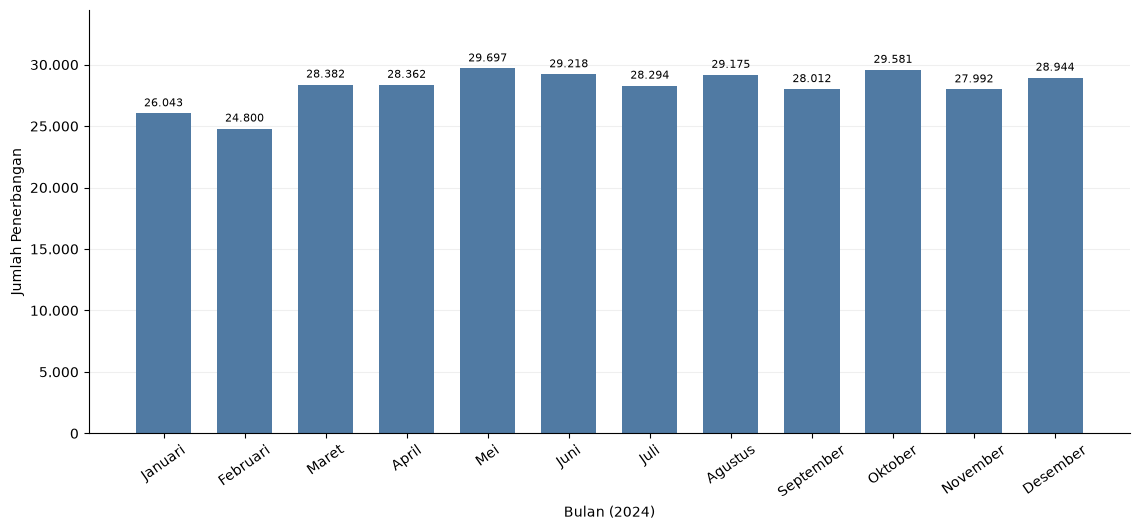

In [55]:
# Visualisasi jumlah penerbangan per bulan secara kronologis.
fig, ax = plt.subplots(figsize=(11.5, 5.4))
bars = ax.bar(ringkasan_bulanan["Bulan"], ringkasan_bulanan["Jumlah Penerbangan"],
              color="#507AA3", width=0.68)
for bar, nilai in zip(bars, ringkasan_bulanan["Jumlah Penerbangan"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+350,
            format_angka(nilai), ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Jumlah Penerbangan")
ax.set_xlabel("Bulan (2024)")
ax.set_ylim(0, ringkasan_bulanan["Jumlah Penerbangan"].max()*1.16)
ax.tick_params(axis="x", rotation=35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: format_angka(x)))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Gambar_4_2_Distribusi_Bulanan.png", dpi=300, bbox_inches="tight")
print("Gambar 4.2 Distribusi Jumlah Penerbangan Berdasarkan Bulan Tahun 2024")
plt.show()
plt.close(fig)

### Menghitung Keterlambatan menurut Jam (Data Pendukung Gambar 4.3)
Validasi crs_dep_time sebagai HHMM, bentuk scheduled_dep_hour, dan hitung persentase Delayed per jam. DataFrame agregasi tidak ditampilkan sebagai tabel karena seluruh nilai diwakili oleh Gambar 4.3.

In [56]:
# Mengonversi waktu terjadwal ke angka dan memvalidasi format HHMM.
crs_hhmm = pd.to_numeric(df_eda["crs_dep_time"], errors="coerce")
valid_crs_time = (
    crs_hhmm.notna()
    & np.isfinite(crs_hhmm)
    & crs_hhmm.ge(0)
    & crs_hhmm.lt(2400)
    & crs_hhmm.mod(1).eq(0)
    & crs_hhmm.mod(100).lt(60)
)
assert valid_crs_time.all(), (
    f"Ada {(~valid_crs_time).sum():,} nilai crs_dep_time yang tidak valid."
)

# scheduled_dep_hour dihitung dari jadwal, bukan waktu keberangkatan aktual.
df_eda["scheduled_dep_hour"] = (crs_hhmm // 100).astype("int8")

# Agregasi jumlah dan tingkat Delayed menurut jam keberangkatan.
ringkasan_jam = (
    df_eda.groupby("scheduled_dep_hour", sort=True)["is_delayed"]
    .agg(Jumlah_Penerbangan="size", Jumlah_Delayed="sum")
    .reset_index()
)
ringkasan_jam["Tingkat Delayed (%)"] = (
    ringkasan_jam["Jumlah_Delayed"] / ringkasan_jam["Jumlah_Penerbangan"] * 100
).round(2)
ringkasan_jam = ringkasan_jam.rename(columns={
    "scheduled_dep_hour": "Jam Keberangkatan",
    "Jumlah_Penerbangan": "Jumlah Penerbangan",
    "Jumlah_Delayed": "Jumlah Delayed"
})
assert ringkasan_jam["Jumlah Penerbangan"].sum() == len(df_eda)

# Mencatat jam dengan tingkat Delayed tertinggi dan terendah.
jam_maks = ringkasan_jam.loc[ringkasan_jam["Tingkat Delayed (%)"].idxmax()]
jam_min = ringkasan_jam.loc[ringkasan_jam["Tingkat Delayed (%)"].idxmin()]
print(f"Tingkat Delayed tertinggi: {int(jam_maks['Jam Keberangkatan']):02d}:00 "
      f"({jam_maks['Tingkat Delayed (%)']:.2f}%)")
print(f"Tingkat Delayed terendah: {int(jam_min['Jam Keberangkatan']):02d}:00 "
      f"({jam_min['Tingkat Delayed (%)']:.2f}%)")

Tingkat Delayed tertinggi: 20:00 (29.32%)
Tingkat Delayed terendah: 06:00 (9.37%)


### Gambar 4.3 — Tingkat Keterlambatan Berdasarkan Jam Keberangkatan Terjadwal
Garis horizontal putus-putus menandai prevalensi Delayed seluruh dataset (19,74%). Garis ini merupakan pembanding deskriptif, bukan ambang keputusan model.

Gambar 4.3 Tingkat Keterlambatan Berdasarkan Jam Keberangkatan Terjadwal


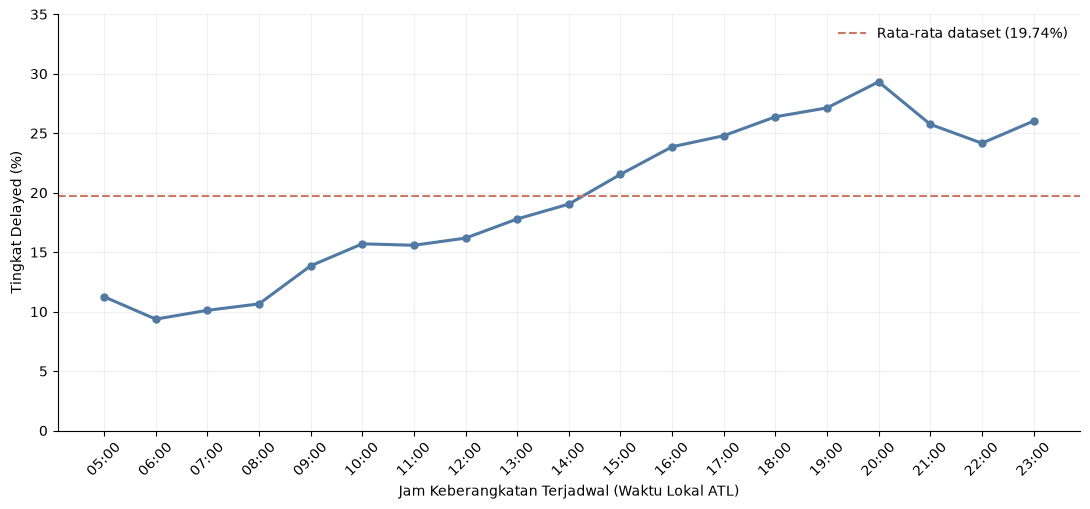

In [57]:
# Memvisualisasikan persentase kelas Delayed menurut jam keberangkatan terjadwal.
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(ringkasan_jam["Jam Keberangkatan"], ringkasan_jam["Tingkat Delayed (%)"],
        marker="o", linewidth=2.2, markersize=5, color="#507AA3")
ax.axhline(prevalensi_delayed*100, color="#C97964", linestyle="--",
           linewidth=1.5, label=f"Rata-rata dataset ({prevalensi_delayed*100:.2f}%)")
ax.set_xticks(ringkasan_jam["Jam Keberangkatan"])
ax.set_xticklabels([f"{int(h):02d}:00" for h in ringkasan_jam["Jam Keberangkatan"]], rotation=45)
ax.set_ylabel("Tingkat Delayed (%)")
ax.set_xlabel("Jam Keberangkatan Terjadwal (Waktu Lokal ATL)")
ax.set_ylim(0, max(35, ringkasan_jam["Tingkat Delayed (%)"].max()+4))
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.18)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Gambar_4_3_Tingkat_Delay_Per_Jam.png", dpi=300, bbox_inches="tight")
print("Gambar 4.3 Tingkat Keterlambatan Berdasarkan Jam Keberangkatan Terjadwal")
plt.show()
plt.close(fig)

### Menghitung Tingkat Keterlambatan menurut Maskapai (Data Pendukung Gambar 4.4)
Hitung jumlah penerbangan dan tingkat Delayed untuk setiap kode maskapai. Tidak ada tabel ditampilkan karena Gambar 4.4 sudah menyajikan seluruh kode maskapai dan ukuran sampelnya.

In [58]:
# Memeriksa kelengkapan kode maskapai.
assert df_eda["op_unique_carrier"].notna().all()

# Menghitung jumlah, kelas Delayed, dan tingkat keterlambatan per maskapai.
ringkasan_maskapai = (
    df_eda.groupby("op_unique_carrier")["is_delayed"]
    .agg(Jumlah_Penerbangan="size", Jumlah_Delayed="sum")
    .reset_index()
)
ringkasan_maskapai["Tingkat Delayed (%)"] = (
    ringkasan_maskapai["Jumlah_Delayed"] / ringkasan_maskapai["Jumlah_Penerbangan"] * 100
).round(2)
ringkasan_maskapai = (
    ringkasan_maskapai.rename(columns={
        "op_unique_carrier": "Kode Maskapai",
        "Jumlah_Penerbangan": "Jumlah Penerbangan",
        "Jumlah_Delayed": "Jumlah Delayed"
    })
    .sort_values(["Tingkat Delayed (%)", "Kode Maskapai"], ascending=[False, True])
    .reset_index(drop=True)
)
assert len(ringkasan_maskapai) == 13
assert ringkasan_maskapai["Jumlah Penerbangan"].sum() == len(df_eda)

# Ringkasan dipakai untuk visualisasi, tanpa mengulang seluruh data dalam tabel.
print(f"Jumlah maskapai yang dianalisis: {len(ringkasan_maskapai)}")

Jumlah maskapai yang dianalisis: 13


### Gambar 4.4 — Tingkat Keterlambatan Berdasarkan Maskapai (Opsional)
Grafik memuat kode maskapai dan besaran sampel (n) agar persentase tidak diinterpretasikan tanpa konteks frekuensi.

Gambar 4.4 Tingkat Keterlambatan Berdasarkan Maskapai


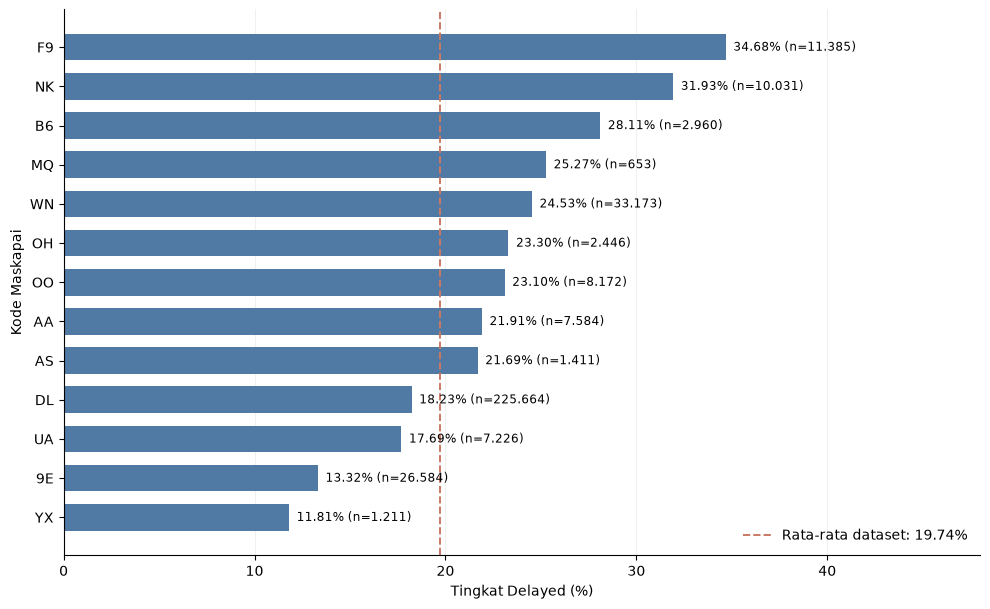

In [59]:
# Membuat perbandingan tingkat Delayed antar-maskapai.
plot_maskapai = ringkasan_maskapai.sort_values("Tingkat Delayed (%)", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6.2))
bars = ax.barh(plot_maskapai["Kode Maskapai"],
               plot_maskapai["Tingkat Delayed (%)"], color="#507AA3", height=0.68)
for bar, persen, n in zip(bars, plot_maskapai["Tingkat Delayed (%)"],
                          plot_maskapai["Jumlah Penerbangan"]):
    ax.text(bar.get_width()+0.4, bar.get_y()+bar.get_height()/2,
            f"{persen:.2f}% (n={format_angka(n)})", va="center", fontsize=8.3)
ax.axvline(prevalensi_delayed*100, color="#C97964", linestyle="--",
           linewidth=1.4, label=f"Rata-rata dataset: {prevalensi_delayed*100:.2f}%")
ax.set_xlabel("Tingkat Delayed (%)")
ax.set_ylabel("Kode Maskapai")
ax.set_xlim(0, max(48, plot_maskapai["Tingkat Delayed (%)"].max()+13))
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Gambar_4_4_Tingkat_Delay_Maskapai.png", dpi=300, bbox_inches="tight")
print("Gambar 4.4 Tingkat Keterlambatan Berdasarkan Maskapai")
plt.show()
plt.close(fig)

### Tabel 4.3 — Variasi Keterlambatan pada 15 Destinasi dengan Volume Terbesar
Tingkat Delayed berdasarkan destinasi belum divisualisasikan, sehingga disajikan sebagai tabel tambahan. Tabel 4.3 memuat 15 destinasi dengan volume penerbangan terbesar agar ringkas untuk Bab IV. Perhitungan seluruh 157 destinasi tetap tersedia dan diekspor sebagai lampiran tanpa memotong isinya.

In [60]:
# Memeriksa kelengkapan kode destinasi.
assert df_eda["dest"].notna().all()

# Menghitung jumlah dan tingkat keterlambatan seluruh destinasi.
ringkasan_destinasi = (
    df_eda.groupby("dest")["is_delayed"]
    .agg(Jumlah_Penerbangan="size", Jumlah_Delayed="sum")
    .reset_index()
)
ringkasan_destinasi["Tingkat Delayed (%)"] = (
    ringkasan_destinasi["Jumlah_Delayed"] / ringkasan_destinasi["Jumlah_Penerbangan"] * 100
).round(2)
ringkasan_destinasi = (
    ringkasan_destinasi.rename(columns={
        "dest": "Kode Destinasi",
        "Jumlah_Penerbangan": "Jumlah Penerbangan",
        "Jumlah_Delayed": "Jumlah Delayed"
    })
    .sort_values(["Jumlah Penerbangan", "Kode Destinasi"], ascending=[False, True])
    .reset_index(drop=True)
)
assert len(ringkasan_destinasi) == 157
assert ringkasan_destinasi["Jumlah Penerbangan"].sum() == len(df_eda)

# Tabel utama hanya untuk 15 destinasi dengan volume terbesar.
tabel_4_3 = ringkasan_destinasi.head(15).copy()

print("Tabel 4.3 Variasi Tingkat Keterlambatan pada 15 Destinasi dengan Volume Terbesar")
display(tampilan_tabel(tabel_4_3))

# Dataset lengkap 157 destinasi disimpan tanpa pemotongan saat ekspor.
print(f"Jumlah destinasi lengkap untuk lampiran: {len(ringkasan_destinasi)}")

Tabel 4.3 Variasi Tingkat Keterlambatan pada 15 Destinasi dengan Volume Terbesar


,Kode Destinasi,Jumlah Penerbangan,Jumlah Delayed,Tingkat Delayed (%)
0,MCO,8790,2299,26.150000
1,LGA,8013,1838,22.940000
2,FLL,7610,2057,27.030000
3,DCA,6792,1381,20.330000
4,TPA,6631,1628,24.550000
5,MIA,6623,1764,26.630000
6,DFW,6415,1649,25.710000
7,DEN,6020,1292,21.460000
8,BWI,5999,1479,24.650000
9,EWR,5935,1409,23.740000


Jumlah destinasi lengkap untuk lampiran: 157


### Tabel 4.4 — Distribusi Kelas pada Training, Validation, dan Testing
Persentase On-Time dan Delayed dihitung terhadap total masing-masing partisi. Karena distribusi kelas temporal tidak ditampilkan dalam grafik lain, hasil ini dipertahankan sebagai Tabel 4.4.

In [63]:
# Membangun penanda partisi temporal tanpa mengacak data.
kondisi_train = df_eda["fl_date"].between("2024-01-01", "2024-08-31")
kondisi_val = df_eda["fl_date"].between("2024-09-01", "2024-10-31")
kondisi_test = df_eda["fl_date"].between("2024-11-01", "2024-12-31")

# Memastikan setiap baris tergabung tepat satu periode.
jumlah_partisi = (kondisi_train.astype(int) + kondisi_val.astype(int)
                  + kondisi_test.astype(int))
assert jumlah_partisi.eq(1).all()

df_eda["partisi_temporal"] = pd.Categorical(
    np.select([kondisi_train, kondisi_val, kondisi_test],
              ["Training", "Validation", "Testing"], default="Tidak Dikenal"),
    categories=["Training", "Validation", "Testing"], ordered=True
)

# Tabel distribusi kelas untuk setiap periode temporal.
ringkasan_partisi = (
    df_eda.groupby("partisi_temporal", observed=True)["is_delayed"]
    .agg(Total="size", Delayed="sum")
    .reset_index()
)
ringkasan_partisi["On-Time"] = ringkasan_partisi["Total"] - ringkasan_partisi["Delayed"]
ringkasan_partisi["On-Time (%)"] = (
    ringkasan_partisi["On-Time"] / ringkasan_partisi["Total"] * 100
).round(2)
ringkasan_partisi["Delayed (%)"] = (
    ringkasan_partisi["Delayed"] / ringkasan_partisi["Total"] * 100
).round(2)
tabel_4_4 = ringkasan_partisi.rename(columns={
    "partisi_temporal": "Partisi", "Total": "Jumlah Observasi"
})[["Partisi", "Jumlah Observasi", "On-Time", "On-Time (%)",
    "Delayed", "Delayed (%)"]]

# Verifikasi konsistensi hitungan lintas partisi dan 4.1.1.
assert tabel_4_4["Jumlah Observasi"].sum() == len(df_eda)
assert tabel_4_4["On-Time"].sum() == 271_680
assert tabel_4_4["Delayed"].sum() == 66_820
assert tabel_4_4["Jumlah Observasi"].tolist() == [223_971, 57_593, 56_936]

print("Tabel 4.4 Distribusi Kelas On-Time dan Delayed pada Partisi Temporal")
display(tampilan_tabel(tabel_4_4))

Tabel 4.4 Distribusi Kelas On-Time dan Delayed pada Partisi Temporal


,Partisi,Jumlah Observasi,On-Time,On-Time (%),Delayed,Delayed (%)
0,Training,223971,175300,78.270000,48671,21.730000
1,Validation,57593,49740,86.360000,7853,13.640000
2,Testing,56936,46640,81.920000,10296,18.080000


### Validasi dan Ekspor Tabel untuk Microsoft Word
Lakukan validasi jumlah data pada semua agregasi. Ekspor hanya tabel yang diperlukan untuk skripsi, yaitu Tabel 4.3 dan Tabel 4.4, serta lampiran penuh 157 destinasi. Pada Windows semua file tabel akan tersimpan ke folder Tabel Data yang telah ditetapkan pada langkah pertama. Empat gambar 300 dpi tetap disimpan pada folder output grafik. Tidak dilakukan pelatihan model.

In [65]:
# Memastikan agregasi mencakup data dan label positif yang sama.
for nama, data_agregat, kolom_total, kolom_delay in [
    ("Distribusi Bulanan", ringkasan_bulanan, "Jumlah Penerbangan", "Jumlah Delayed"),
    ("Tingkat Delayed per Jam", ringkasan_jam, "Jumlah Penerbangan", "Jumlah Delayed"),
    ("Tingkat Delayed per Maskapai", ringkasan_maskapai, "Jumlah Penerbangan", "Jumlah Delayed"),
    ("Tingkat Delayed per Destinasi", ringkasan_destinasi, "Jumlah Penerbangan", "Jumlah Delayed")
]:
    assert int(data_agregat[kolom_total].sum()) == 338_500, nama
    assert int(data_agregat[kolom_delay].sum()) == 66_820, nama

# Mengekspor hanya tabel yang tidak diduplikasi grafik.
ekspor_tabel(
    tabel_4_3, "Tabel_4_3_15_Destinasi",
    "Tabel 4.3 Variasi Tingkat Keterlambatan pada 15 Destinasi dengan Volume Terbesar"
)
ekspor_tabel(
    tabel_4_4, "Tabel_4_4_Distribusi_Kelas_Temporal",
    "Tabel 4.4 Distribusi Kelas On-Time dan Delayed pada Partisi Temporal"
)
ekspor_tabel(
    ringkasan_destinasi, "Lampiran_Rincian_157_Destinasi",
    "Lampiran Rincian Tingkat Keterlambatan pada 157 Destinasi"
)

# Memeriksa keberadaan gambar dan file hasil ekspor
from pathlib import Path

# Daftar gambar yang wajib dihasilkan pada Subbab 4.1.2
expected_images = [
    "Gambar_4_1_Distribusi_Kelas.png",
    "Gambar_4_2_Distribusi_Bulanan.png",
    "Gambar_4_3_Tingkat_Delay_Per_Jam.png",
    "Gambar_4_4_Tingkat_Delay_Maskapai.png"
]

# Daftar tabel yang wajib dihasilkan pada Subbab 4.1.2
expected_tables = [
    "Tabel_4_3_15_Destinasi",
    "Tabel_4_4_Distribusi_Kelas_Temporal",
    "Lampiran_Rincian_157_Destinasi"
]

# Membentuk daftar file yang diharapkan
expected_files = (
    [OUTPUT_DIR / name for name in expected_images]
    + [TABLE_DIR / f"{name}.csv" for name in expected_tables]
    + [TABLE_DIR / f"{name}.html" for name in expected_tables]
)

# Memeriksa keberadaan dan ukuran file
missing_files = [
    str(path)
    for path in expected_files
    if not path.is_file() or path.stat().st_size == 0
]

# Menghentikan eksekusi jika file wajib tidak tersedia
assert not missing_files, (
    "File hasil analisis belum tersedia atau kosong:\n"
    + "\n".join(missing_files)
)

# Menghitung file yang berhasil diverifikasi
n_images = len(expected_images)
n_csv = len(expected_tables)
n_html = len(expected_tables)

print("Validasi analisis 4.1.2 selesai.")
print("Tabel redundan yang sama dengan grafik tidak ditampilkan.")

print(f"\nJumlah gambar terverifikasi : {n_images}")
print(f"Jumlah tabel CSV            : {n_csv}")
print(f"Jumlah tabel HTML           : {n_html}")

print(f"\nFolder gambar: {OUTPUT_DIR}")
print(f"Folder tabel : {TABLE_DIR}")

print("\nSeluruh file wajib Subbab 4.1.2 berhasil diverifikasi.")
print("Tidak ada pelatihan ML atau rekayasa fitur historis T−2h.")

Tabel disimpan: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_3_15_Destinasi.csv
Versi Word-friendly: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_3_15_Destinasi.html
Tabel disimpan: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_4_Distribusi_Kelas_Temporal.csv
Versi Word-friendly: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_4_Distribusi_Kelas_Temporal.html
Tabel disimpan: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Lampiran_Rincian_157_Destinasi.csv
Versi Word-friendly: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Lampiran_Rincian_157_Destinasi.html
Validasi analisis 4.1.2 selesai.
Tabel redundan yang sama dengan grafik tidak ditampilkan.

Jumlah gambar terverifikasi : 4
Jumlah tabel CSV            : 3
Juml

## 4.2 Hasil Prapemrosesan dan Rekayasa Fitur Historis
### 4.2.1 Hasil Pembersihan Data dan Pembentukan Fitur Dasar

In [66]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Menghilangkan pembatas jumlah baris/kolom dan panjang teks saat menampilkan tabel.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1200)
pd.set_option("display.expand_frame_repr", False)

# Mencari data mentah hanya jika belum tersedia dari sel 4.1 sebelumnya.
if "df_raw" not in globals():
    file_candidates = [
        Path("flight_data_2024_origin_ATL(1).xls"),
        Path("flight_data_2024_origin_ATL.xls"),
        Path("flights_atl_2024.csv"),
        Path("/mnt/data/flight_data_2024_origin_ATL(1).xls"),
    ]
    data_path = next((p for p in file_candidates if p.is_file()), None)
    if data_path is None:
        raise FileNotFoundError("Dataset ATL tidak ditemukan; perbarui file_candidates.")
    df_raw = pd.read_csv(data_path, low_memory=False)

# Gunakan hasil 4.1.1; seleksi ulang hanya untuk notebook yang dijalankan mandiri.
if "df_clean" not in globals():
    status = pd.to_numeric(df_raw["cancelled"], errors="coerce")
    delay = pd.to_numeric(df_raw["dep_delay"], errors="coerce")
    assert status.notna().all() and status.isin([0, 1]).all()
    valid_label = delay.notna() & np.isfinite(delay)
    df_clean = df_raw.loc[status.eq(0) & valid_label].copy()
    df_clean["fl_date"] = pd.to_datetime(df_clean["fl_date"], format="%Y-%m-%d", errors="raise")
    df_clean["dep_delay"] = pd.to_numeric(df_clean["dep_delay"], errors="raise")
    df_clean = df_clean.sort_values("fl_date", kind="stable").reset_index(drop=True)

# Membuat salinan kerja khusus 4.2.1 agar df_raw dan df_clean tetap dapat diaudit.
df_prepared = df_clean.copy()
df_prepared["fl_date"] = pd.to_datetime(df_prepared["fl_date"], errors="raise")
df_prepared["dep_delay"] = pd.to_numeric(df_prepared["dep_delay"], errors="raise")

assert len(df_raw) == 341_910
assert len(df_prepared) == 338_500
assert df_prepared["fl_date"].dt.year.eq(2024).all()
print(f"Data awal: {len(df_raw):,}; data bersih: {len(df_prepared):,}")

Data awal: 341,910; data bersih: 338,500


### Ringkasan hasil pembersihan dan pemeriksaan kualitas data
Bedakan temuan audit data sumber (nilai kosong, duplikasi, tipe data) dari tindakan seleksi. Seluruh penerbangan yang dibatalkan dikeluarkan pada 4.1.1; nilai dep_delay pada penerbangan tidak dibatalkan wajib valid. Pemeriksaan atribut prediktor dilakukan kembali sebelum rekayasa fitur.

In [67]:
# Memeriksa pembatalan, missing label, duplikat identik, dan tipe tanggal awal.
status_raw = pd.to_numeric(df_raw["cancelled"], errors="coerce")
delay_raw = pd.to_numeric(df_raw["dep_delay"], errors="coerce")
invalid_raw_delay = delay_raw.isna() | ~np.isfinite(delay_raw)

n_cancelled = int(status_raw.eq(1).sum())
n_missing_dep_delay_raw = int(df_raw["dep_delay"].isna().sum())
n_cancelled_valid_delay = int((status_raw.eq(1) & ~invalid_raw_delay).sum())
n_duplicate_raw = int(df_raw.duplicated().sum())
n_duplicate_clean = int(df_prepared.duplicated().sum())
n_bad_label_clean = int((df_prepared["dep_delay"].isna() |
                         ~np.isfinite(df_prepared["dep_delay"])).sum())

assert n_cancelled == 3_410
assert n_missing_dep_delay_raw == 3_321
assert n_cancelled_valid_delay == 89
assert n_duplicate_raw == 0 and n_duplicate_clean == 0
assert n_bad_label_clean == 0
assert df_prepared["cancelled"].eq(0).all()

print("Ringkasan audit kualitas data:")
print(f"- Duplikasi identik pada sumber / data bersih: {n_duplicate_raw} / {n_duplicate_clean}")
print(f"- Pembatalan yang dikeluarkan: {n_cancelled:,}")
print(f"- Missing dep_delay pada sumber: {n_missing_dep_delay_raw:,}")
print(f"- Dibatalkan tetapi dep_delay valid: {n_cancelled_valid_delay:,}")
print(f"- Label tidak valid pada data bersih: {n_bad_label_clean}")
print(f"- fl_date: sumber={df_raw['fl_date'].dtype}, hasil={df_prepared['fl_date'].dtype}")

Ringkasan audit kualitas data:
- Duplikasi identik pada sumber / data bersih: 0 / 0
- Pembatalan yang dikeluarkan: 3,410
- Missing dep_delay pada sumber: 3,321
- Dibatalkan tetapi dep_delay valid: 89
- Label tidak valid pada data bersih: 0
- fl_date: sumber=str, hasil=datetime64[us]


### Pembentukan target klasifikasi biner
Target bernilai 1 (Delayed) jika dep_delay >= 15 menit dan 0 (On-Time) jika kurang dari 15 menit, termasuk keberangkatan lebih awal dengan nilai negatif. dep_delay tetap tersimpan untuk audit/rekayasa riwayat kelak, tetapi tidak boleh masuk ke X baseline.

In [68]:
# Membentuk target tanpa mengubah nilai dep_delay aslinya.
df_prepared["target_delay"] = (df_prepared["dep_delay"] >= 15).astype("int8")

target_counts = df_prepared["target_delay"].value_counts().sort_index()
assert set(target_counts.index) == {0, 1}
assert int(target_counts[0]) == 271_680
assert int(target_counts[1]) == 66_820

print("Target biner terbentuk berdasarkan dep_delay >= 15 menit.")
print(f"On-Time (0): {int(target_counts[0]):,} ({target_counts[0] / len(df_prepared):.2%})")
print(f"Delayed (1): {int(target_counts[1]):,} ({target_counts[1] / len(df_prepared):.2%})")

Target biner terbentuk berdasarkan dep_delay >= 15 menit.
On-Time (0): 271,680 (80.26%)
Delayed (1): 66,820 (19.74%)


### Pembentukan scheduled_dep_hour dari waktu jadwal HHMM
Atribut crs_dep_time diperiksa sebagai bilangan bulat HHMM; jam diambil dengan pembagian bulat 100, sehingga 05:00 menjadi 5 dan 20:30 menjadi 20. Nilai invalid akan menghentikan proses agar tidak menghasilkan waktu salah.

In [69]:
# Memeriksa format HHMM, termasuk rentang jam dan menit.
hhmm = pd.to_numeric(df_prepared["crs_dep_time"], errors="coerce")
hh = hhmm // 100
mm = hhmm % 100
valid_hhmm = (
    hhmm.notna()
    & np.isfinite(hhmm)
    & hhmm.mod(1).eq(0)
    & hh.between(0, 23)
    & mm.between(0, 59)
)
assert valid_hhmm.all(), f"Ada {int((~valid_hhmm).sum()):,} jadwal HHMM tidak valid."

# Menyimpan fitur jam sebagai bilangan bulat 0–23.
df_prepared["scheduled_dep_hour"] = hh.astype("int8")
assert df_prepared["scheduled_dep_hour"].between(0, 23).all()

# Memastikan month dan day_of_week selaras dengan tanggal (BTS: Senin=1).
assert df_prepared["month"].eq(df_prepared["fl_date"].dt.month).all()
assert df_prepared["day_of_week"].eq(df_prepared["fl_date"].dt.dayofweek + 1).all()

print(f"HHMM valid: {int(valid_hhmm.sum()):,} / {len(df_prepared):,}")
print("scheduled_dep_hour berhasil dibentuk dengan rentang 0–23.")

HHMM valid: 338,500 / 338,500
scheduled_dep_hour berhasil dibentuk dengan rentang 0–23.


### Menentukan tujuh fitur dasar dan mengaudit nilai kosong sumber
Skenario baseline ditetapkan persis sesuai Bab III. Kode kategorikal harus tidak kosong; jarak dan durasi terjadwal harus numerik, finite, serta positif. Pemeriksaan ini belum mengubah df_clean atau menggunakan hasil operasional aktual sebagai prediktor.

In [70]:
# Daftar fitur baseline resmi berdasarkan Bab III, Subbab 3.4.2.
BASELINE_FEATURES = [
    "month",
    "day_of_week",
    "scheduled_dep_hour",
    "op_unique_carrier",
    "dest",
    "distance",
    "crs_elapsed_time",
]
CAT_FEATURES = ["op_unique_carrier", "dest"]
NUMERIC_FEATURES = [f for f in BASELINE_FEATURES if f not in CAT_FEATURES]

# Memastikan atribut dasar benar-benar tersedia dan tidak mempunyai nilai kosong.
assert all(col in df_prepared.columns for col in BASELINE_FEATURES)
missing_before_categorical = df_prepared[BASELINE_FEATURES].isna().sum()
assert missing_before_categorical.eq(0).all(), (
    f"Missing pada data dasar: {missing_before_categorical[missing_before_categorical.gt(0)].to_dict()}"
)

# Memeriksa kode kategori tidak kosong/whitespace.
for col in CAT_FEATURES:
    assert df_prepared[col].astype("string").str.strip().ne("").all(), f"Kode kosong: {col}"

# Memastikan nilai numerik finite dan karakteristik jadwal logis.
for col in NUMERIC_FEATURES:
    values = pd.to_numeric(df_prepared[col], errors="coerce")
    assert values.notna().all() and np.isfinite(values).all(), f"Tidak valid: {col}"
assert df_prepared["month"].between(1, 12).all()
assert df_prepared["day_of_week"].between(1, 7).all()
assert df_prepared["distance"].gt(0).all()
assert df_prepared["crs_elapsed_time"].gt(0).all()

print("Ketujuh fitur baseline lengkap dan memenuhi pemeriksaan validitas dasar.")
print(f"Missing pada sumber fitur dasar: {int(missing_before_categorical.sum())}")
print("Fitur baseline:", ", ".join(BASELINE_FEATURES))

Ketujuh fitur baseline lengkap dan memenuhi pemeriksaan validitas dasar.
Missing pada sumber fitur dasar: 0
Fitur baseline: month, day_of_week, scheduled_dep_hour, op_unique_carrier, dest, distance, crs_elapsed_time


### Temporal split dan representasi kategorikal tanpa informasi masa depan
Data dipisahkan ulang menggunakan fl_date dengan batas periode yang sama seperti 4.1.1. Untuk op_unique_carrier dan dest, daftar kategori diperoleh hanya dari training dengan CategoricalDtype. Kategori baru di validation/testing akan menjadi NaN pada matriks fitur, sehingga LightGBM dapat menanganinya sebagai kategori tidak dikenal tanpa membuat kode numerik seolah-olah berurutan. Observasi tidak dihapus.

In [71]:
# Membatasi partisi secara kronologis, tanpa random split.
date_421 = df_prepared["fl_date"]
m_train_421 = date_421.between("2024-01-01", "2024-08-31")
m_val_421 = date_421.between("2024-09-01", "2024-10-31")
m_test_421 = date_421.between("2024-11-01", "2024-12-31")
assert (m_train_421.astype(int) + m_val_421.astype(int) + m_test_421.astype(int)).eq(1).all()

# Memisahkan fitur dan label menggunakan indeks observasi yang sama.
X_train_baseline = df_prepared.loc[m_train_421, BASELINE_FEATURES].copy()
X_val_baseline = df_prepared.loc[m_val_421, BASELINE_FEATURES].copy()
X_test_baseline = df_prepared.loc[m_test_421, BASELINE_FEATURES].copy()
y_train = df_prepared.loc[m_train_421, "target_delay"].copy()
y_val = df_prepared.loc[m_val_421, "target_delay"].copy()
y_test = df_prepared.loc[m_test_421, "target_delay"].copy()

# Menggunakan kategori dari periode training saja untuk semua partisi.
unseen_category_counts = {}
unseen_category_values = {}
for col in CAT_FEATURES:
    categories_train = sorted(X_train_baseline[col].dropna().astype(str).unique().tolist())
    dtype_train = pd.CategoricalDtype(categories=categories_train, ordered=False)
    for partition_name, part in [("Validation", X_val_baseline), ("Testing", X_test_baseline)]:
        unseen_mask = ~part[col].isin(categories_train) & part[col].notna()
        unseen_category_counts[(partition_name, col)] = int(unseen_mask.sum())
        unseen_category_values[(partition_name, col)] = sorted(part.loc[unseen_mask, col].unique().tolist())
    for part in [X_train_baseline, X_val_baseline, X_test_baseline]:
        part[col] = part[col].astype(dtype_train)

# Menjamin bentuk feature matrix dan keselarasan label.
assert X_train_baseline.shape == (223_971, 7)
assert X_val_baseline.shape == (57_593, 7)
assert X_test_baseline.shape == (56_936, 7)
assert X_train_baseline.index.equals(y_train.index)
assert X_val_baseline.index.equals(y_val.index)
assert X_test_baseline.index.equals(y_test.index)
assert all(str(X_train_baseline[c].dtype) == "category" for c in CAT_FEATURES)

print("Ukuran matriks baseline:")
print(f"- Training   : {X_train_baseline.shape}")
print(f"- Validation : {X_val_baseline.shape}")
print(f"- Testing    : {X_test_baseline.shape}")
for (period, col), count in unseen_category_counts.items():
    print(f"- Kategori baru {col} pada {period}: {count} observasi; kode={unseen_category_values[(period, col)]}")

Ukuran matriks baseline:
- Training   : (223971, 7)
- Validation : (57593, 7)
- Testing    : (56936, 7)
- Kategori baru op_unique_carrier pada Validation: 0 observasi; kode=[]
- Kategori baru op_unique_carrier pada Testing: 0 observasi; kode=[]
- Kategori baru dest pada Validation: 0 observasi; kode=[]
- Kategori baru dest pada Testing: 41 observasi; kode=['OGG']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16024\2708185700.py:27: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  part[col] = part[col].astype(dtype_train)


### Pemeriksaan akhir matriks, nilai kosong dan pencegahan kebocoran fitur
Matriks dibangun dengan daftar kolom positif (allowlist) sehingga nilai dep_delay, data aktual keberangkatan/kedatangan, dan atribut penanda waktu lain tidak mungkin terbawa sebagai prediktor. Perlu dibedakan: missing pada data sumber dan missing yang sengaja muncul karena kategori baru di masa depan.

In [72]:
# Melarang atribut aktual dan target masuk ke X.
FORBIDDEN_PREDICTORS = {
    "target_delay", "dep_delay", "dep_time", "taxi_out", "wheels_off",
    "wheels_on", "taxi_in", "arr_time", "arr_delay", "diverted",
    "actual_elapsed_time", "air_time", "carrier_delay", "weather_delay",
    "nas_delay", "security_delay", "late_aircraft_delay", "cancellation_code",
    "cancelled", "fl_date", "crs_dep_time"
}
for part in (X_train_baseline, X_val_baseline, X_test_baseline):
    assert part.columns.tolist() == BASELINE_FEATURES
    assert FORBIDDEN_PREDICTORS.isdisjoint(part.columns)
    assert not any(pd.api.types.is_object_dtype(part[c]) for c in part.columns)

# Mengecek seluruh missing per kolom (termasuk kategori baru setelah pengodean).
missing_train = X_train_baseline.isna().sum()
missing_val = X_val_baseline.isna().sum()
missing_test = X_test_baseline.isna().sum()
assert int(missing_train.sum()) == 0
assert int(missing_val.sum()) == 0
assert int(missing_test.sum()) == unseen_category_counts[("Testing", "dest")]

print("Pemeriksaan kebocoran fitur: lulus (hanya tujuh fitur jadwal/rute).")
print("Missing pada X_train, X_val, X_test:",
      int(missing_train.sum()), int(missing_val.sum()), int(missing_test.sum()))
print("Perhatikan bahwa missing pada X_test berasal dari kode destinasi yang belum ada pada training.")

Pemeriksaan kebocoran fitur: lulus (hanya tujuh fitur jadwal/rute).
Missing pada X_train, X_val, X_test: 0 0 41
Perhatikan bahwa missing pada X_test berasal dari kode destinasi yang belum ada pada training.


### Tabel 4.3 — Struktur dan Karakteristik Fitur Dasar Skenario Baseline
Tabel ini satu-satunya tabel utama pada 4.2.1. Selain nama dan fungsi fitur, tabel menyajikan tipe data pada matriks LightGBM serta jumlah missing pada masing-masing partisi setelah penyelarasan kategori menggunakan vocab training. Seluruh teks ditampilkan lengkap tanpa elipsis.

In [73]:
# Metadata penjelas untuk ketujuh fitur dasar sesuai Bab III.
fitur_deskripsi = {
    "month": ("fl_date / month", "Bulan keberangkatan (1–12), fitur jadwal."),
    "day_of_week": ("fl_date / day_of_week", "Hari dalam minggu (Senin=1 sampai Minggu=7)."),
    "scheduled_dep_hour": ("crs_dep_time", "Jam keberangkatan terjadwal, diekstraksi dari HHMM (0–23)."),
    "op_unique_carrier": ("op_unique_carrier", "Kode maskapai, diperlakukan sebagai kategori nominal dengan vocab training."),
    "dest": ("dest", "Kode bandara tujuan, kategori nominal; kategori tak dikenal menjadi NaN pada matriks."),
    "distance": ("distance", "Jarak rute terjadwal dalam mil."),
    "crs_elapsed_time": ("crs_elapsed_time", "Durasi penerbangan terjadwal dalam menit."),
}

# Menyusun Tabel 4.3 secara otomatis dari struktur X_train/val/test.
tabel_4_3 = pd.DataFrame([
    {
        "No.": i,
        "Fitur Dasar": feature,
        "Sumber": fitur_deskripsi[feature][0],
        "Tipe di X": str(X_train_baseline[feature].dtype),
        "Karakteristik": fitur_deskripsi[feature][1],
        "Missing Train": int(missing_train[feature]),
        "Missing Validation": int(missing_val[feature]),
        "Missing Testing": int(missing_test[feature]),
    }
    for i, feature in enumerate(BASELINE_FEATURES, 1)
])

# Menampilkan nomor dan judul tabel sebelum display sesuai ketentuan skripsi.
print("Tabel 4.3 Struktur dan Karakteristik Fitur Dasar Skenario Baseline")
display(tabel_4_3.style.set_properties(**{
    "white-space": "normal",
    "overflow-wrap": "break-word",
    "text-align": "left",
    "vertical-align": "top"
}))

Tabel 4.3 Struktur dan Karakteristik Fitur Dasar Skenario Baseline


,No.,Fitur Dasar,Sumber,Tipe di X,Karakteristik,Missing Train,Missing Validation,Missing Testing
0,1,month,fl_date / month,int64,"Bulan keberangkatan (1–12), fitur jadwal.",0,0,0
1,2,day_of_week,fl_date / day_of_week,int64,Hari dalam minggu (Senin=1 sampai Minggu=7).,0,0,0
2,3,scheduled_dep_hour,crs_dep_time,int8,"Jam keberangkatan terjadwal, diekstraksi dari HHMM (0–23).",0,0,0
3,4,op_unique_carrier,op_unique_carrier,category,"Kode maskapai, diperlakukan sebagai kategori nominal dengan vocab training.",0,0,0
4,5,dest,dest,category,"Kode bandara tujuan, kategori nominal; kategori tak dikenal menjadi NaN pada matriks.",0,0,41
5,6,distance,distance,float64,Jarak rute terjadwal dalam mil.,0,0,0
6,7,crs_elapsed_time,crs_elapsed_time,float64,Durasi penerbangan terjadwal dalam menit.,0,0,0


### Mengekspor Tabel 4.3 ke folder penulisan skripsi

In [74]:
# Lokasi tujuan ekspor yang diminta pada komputer Windows.
WINDOWS_TABLE_DIR = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures"
    r"\Semester 7 - SI\Skripsi\Tabel Data"
)
OUTPUT_DIR_421 = Path("output_4_2_1")
TABLE_DIR_421 = (
    WINDOWS_TABLE_DIR if sys.platform.startswith("win")
    else OUTPUT_DIR_421 / "Tabel Data"
)
TABLE_DIR_421.mkdir(parents=True, exist_ok=True)

# Mengekspor format CSV dan HTML agar mudah disalin ke Microsoft Word.
judul_tabel = "Tabel 4.3 Struktur dan Karakteristik Fitur Dasar Skenario Baseline"
file_csv = TABLE_DIR_421 / "Tabel_4_3_Struktur_Fitur_Dasar_Baseline.csv"
file_html = TABLE_DIR_421 / "Tabel_4_3_Struktur_Fitur_Dasar_Baseline.html"

tabel_4_3.to_csv(file_csv, index=False, encoding="utf-8-sig")
css = """<style>
body {font:11pt Arial, sans-serif; margin:25px}
table {border-collapse:collapse; width:100%; table-layout:fixed}
th, td {border:1px solid #999; padding:8px 9px; text-align:left;
        white-space:normal; overflow-wrap:anywhere; vertical-align:top}
th {background:#f0f3f8}
</style>"""
file_html.write_text(
    "<!doctype html><html><head><meta charset='utf-8'>"
    + css + "</head><body><h3>" + judul_tabel + "</h3>"
    + tabel_4_3.to_html(index=False, escape=True, border=0)
    + "</body></html>",
    encoding="utf-8"
)
assert file_csv.is_file() and file_html.is_file()
print(f"CSV  : {file_csv.resolve()}")
print(f"HTML : {file_html.resolve()}")

CSV  : C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_3_Struktur_Fitur_Dasar_Baseline.csv
HTML : C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_3_Struktur_Fitur_Dasar_Baseline.html


### Validasi akhir dan objek keluaran untuk tahap berikutnya
Hasil utama berupa df_prepared, X_train_baseline, X_val_baseline, X_test_baseline, y_train, y_val, dan y_test. Tidak ada pemodelan LightGBM atau pembentukan statistik historis pada 4.2.1. Jangan menyimpulkan bahwa metadata jadwal telah terbukti tersedia tepat pada T−2h; hal itu tetap asumsi simulasi retrospektif yang disepakati di Bab III.

In [75]:
# Validasi akhir: target biner, jumlah observasi, tipe kategori, dan batas tanggal.
assert len(y_train) + len(y_val) + len(y_test) == 338_500
assert int(y_train.sum() + y_val.sum() + y_test.sum()) == 66_820
assert X_train_baseline.columns.tolist() == X_test_baseline.columns.tolist()
assert set(y_train.unique()).issubset({0, 1})
assert set(y_val.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})
assert (df_prepared.loc[m_train_421, "fl_date"].max()
        < df_prepared.loc[m_val_421, "fl_date"].min())
assert (df_prepared.loc[m_val_421, "fl_date"].max()
        < df_prepared.loc[m_test_421, "fl_date"].min())

print("Subbab 4.2.1: semua validasi lulus.")
print("Skenario baseline telah disiapkan (belum dilatih):")
print(f"X_train={X_train_baseline.shape}; X_val={X_val_baseline.shape}; X_test={X_test_baseline.shape}")
print("Tabel 4.3 berhasil diekspor; data mentah, data bersih, dan partisi tidak diubah.")

Subbab 4.2.1: semua validasi lulus.
Skenario baseline telah disiapkan (belum dilatih):
X_train=(223971, 7); X_val=(57593, 7); X_test=(56936, 7)
Tabel 4.3 berhasil diekspor; data mentah, data bersih, dan partisi tidak diubah.


## 4.2.2 Pembentukan Fitur Historis dan Pemeriksaan Batas Temporal T−2h (Data Leakage Prevention)

### Prasyarat dan konfigurasi tampilan
Memastikan objek lanjutan dari 4.2.1 tersedia dan pengaturan Pandas menampilkan isi tabel lengkap.

In [76]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1400)
pd.set_option("display.expand_frame_repr", False)

required_vars_422 = [
    "df_prepared", "X_train_baseline", "X_val_baseline",
    "X_test_baseline", "y_train", "y_val", "y_test",
    "BASELINE_FEATURES", "CAT_FEATURES"
]
missing_vars_422 = [v for v in required_vars_422 if v not in globals()]
assert not missing_vars_422, (
    f"Jalankan 4.2.1 terlebih dahulu. Objek belum tersedia: {missing_vars_422}"
)

assert len(df_prepared) == 338_500
assert sum(map(len, [X_train_baseline, X_val_baseline, X_test_baseline])) == len(df_prepared)
assert df_prepared["target_delay"].isin([0, 1]).all()

# Salinan independen untuk audit temporal; indeks baris ditetapkan sebagai ID unik internal.
df_temporal_422 = df_prepared.copy().reset_index(drop=True)
df_temporal_422["flight_uid"] = np.arange(len(df_temporal_422), dtype=np.int64)
assert df_prepared.index.equals(df_temporal_422.index)

# Jika objek model sudah ada di kernel, simpan parameter sebelum feature engineering.
# Pada alur normal, 4.2.2 dijalankan sebelum pelatihan sehingga snapshot masih kosong.
from copy import deepcopy
model_names_422 = ["model_baseline", "model_enhanced", "best_baseline_model", "best_enhanced_model"]
model_parameter_before_422 = {
    name: deepcopy(globals()[name].get_params())
    for name in model_names_422
    if name in globals() and hasattr(globals()[name], "get_params")
}
print("Prasyarat 4.2.1 berhasil diperiksa; data sumber dan matriks baseline tidak diubah.")

Prasyarat 4.2.1 berhasil diperiksa; data sumber dan matriks baseline tidak diubah.


### Rekonstruksi scheduled_dep_datetime, t_cutoff, dan t_gate_proxy
crs_dep_time pada dataset berupa HHMM. Waktu yang melewati tengah malam ditangani menggunakan operasi Timestamp + Timedelta, bukan pengurangan jam sebagai bilangan bulat.

In [77]:
# Mengurai HHMM secara eksplisit dan memvalidasi jam (0–23) serta menit (0–59).
hhmm_422 = pd.to_numeric(df_temporal_422["crs_dep_time"], errors="raise")
assert hhmm_422.notna().all() and np.isfinite(hhmm_422).all()
assert hhmm_422.mod(1).eq(0).all()
scheduled_hh_422 = (hhmm_422 // 100).astype("int64")
scheduled_mm_422 = (hhmm_422 % 100).astype("int64")
assert scheduled_hh_422.between(0, 23).all()
assert scheduled_mm_422.between(0, 59).all()

# Rekonstruksi waktu jadwal lengkap berdasarkan tanggal penerbangan dan HHMM.
flight_date_422 = pd.to_datetime(df_temporal_422["fl_date"], errors="raise").dt.normalize()
df_temporal_422["scheduled_dep_datetime"] = (
    flight_date_422
    + pd.to_timedelta(scheduled_hh_422, unit="h")
    + pd.to_timedelta(scheduled_mm_422, unit="m")
)

# Horizon prediksi: dua jam sebelum waktu keberangkatan terjadwal.
df_temporal_422["t_cutoff"] = (
    df_temporal_422["scheduled_dep_datetime"] - pd.Timedelta(hours=2)
)

# Proksi ketersediaan label historis: waktu keberangkatan aktual dari gerbang.
# dep_delay hanya menjadi sumber pembentukan label historis, BUKAN kolom fitur target.
delay_422 = pd.to_numeric(df_temporal_422["dep_delay"], errors="raise")
assert delay_422.notna().all() and np.isfinite(delay_422).all()
df_temporal_422["t_gate_proxy"] = (
    df_temporal_422["scheduled_dep_datetime"]
    + pd.to_timedelta(delay_422, unit="m")
)

# Memeriksa identitas rekonstruksi waktu.
assert (df_temporal_422["t_cutoff"] ==
        df_temporal_422["scheduled_dep_datetime"] - pd.Timedelta(hours=2)).all()
assert (df_temporal_422["t_gate_proxy"] ==
        df_temporal_422["scheduled_dep_datetime"] + pd.to_timedelta(delay_422, unit="m")).all()
assert df_temporal_422[["scheduled_dep_datetime", "t_cutoff", "t_gate_proxy"]].notna().all().all()

# Mencatat kasus perlintasan tanggal untuk diperiksa pada tahap audit.
cutoff_previous_day_422 = int((
    df_temporal_422["t_cutoff"].dt.normalize() < flight_date_422
).sum())
gate_other_day_422 = int((
    df_temporal_422["t_gate_proxy"].dt.normalize() != flight_date_422
).sum())
print(f"Observasi dengan t_cutoff pada hari sebelumnya: {cutoff_previous_day_422:,}")
print(f"Observasi dengan t_gate_proxy berbeda tanggal: {gate_other_day_422:,}")

Observasi dengan t_cutoff pada hari sebelumnya: 0
Observasi dengan t_gate_proxy berbeda tanggal: 2,695


### Penanda partisi temporal dan urutan walk-forward
Sumber kejadian historis diurutkan berdasarkan t_gate_proxy (waktu hasil telah diperkirakan tersedia), sedangkan observasi target diproses berdasarkan t_cutoff. Penggabungan as-of memakai direction="backward" dan allow_exact_matches=False untuk menerapkan perbandingan waktu ketat. Riwayat dari periode validasi/pengujian boleh bertambah jika telah tersedia sebelum prediksi berikutnya; tidak ada refit model.

In [78]:
# Mengurai HHMM secara eksplisit dan memvalidasi jam (0–23) serta menit (0–59).
hhmm_422 = pd.to_numeric(df_temporal_422["crs_dep_time"], errors="raise")
assert hhmm_422.notna().all() and np.isfinite(hhmm_422).all()
assert hhmm_422.mod(1).eq(0).all()
scheduled_hh_422 = (hhmm_422 // 100).astype("int64")
scheduled_mm_422 = (hhmm_422 % 100).astype("int64")
assert scheduled_hh_422.between(0, 23).all()
assert scheduled_mm_422.between(0, 59).all()

# Rekonstruksi waktu jadwal lengkap berdasarkan tanggal penerbangan dan HHMM.
flight_date_422 = pd.to_datetime(df_temporal_422["fl_date"], errors="raise").dt.normalize()
df_temporal_422["scheduled_dep_datetime"] = (
    flight_date_422
    + pd.to_timedelta(scheduled_hh_422, unit="h")
    + pd.to_timedelta(scheduled_mm_422, unit="m")
)

# Horizon prediksi: dua jam sebelum waktu keberangkatan terjadwal.
df_temporal_422["t_cutoff"] = (
    df_temporal_422["scheduled_dep_datetime"] - pd.Timedelta(hours=2)
)

# Proksi ketersediaan label historis: waktu keberangkatan aktual dari gerbang.
# dep_delay hanya menjadi sumber pembentukan label historis, BUKAN kolom fitur target.
delay_422 = pd.to_numeric(df_temporal_422["dep_delay"], errors="raise")
assert delay_422.notna().all() and np.isfinite(delay_422).all()
df_temporal_422["t_gate_proxy"] = (
    df_temporal_422["scheduled_dep_datetime"]
    + pd.to_timedelta(delay_422, unit="m")
)

# Memeriksa identitas rekonstruksi waktu.
assert (df_temporal_422["t_cutoff"] ==
        df_temporal_422["scheduled_dep_datetime"] - pd.Timedelta(hours=2)).all()
assert (df_temporal_422["t_gate_proxy"] ==
        df_temporal_422["scheduled_dep_datetime"] + pd.to_timedelta(delay_422, unit="m")).all()
assert df_temporal_422[["scheduled_dep_datetime", "t_cutoff", "t_gate_proxy"]].notna().all().all()

# Mencatat kasus perlintasan tanggal untuk diperiksa pada tahap audit.
cutoff_previous_day_422 = int((
    df_temporal_422["t_cutoff"].dt.normalize() < flight_date_422
).sum())
gate_other_day_422 = int((
    df_temporal_422["t_gate_proxy"].dt.normalize() != flight_date_422
).sum())
print(f"Observasi dengan t_cutoff pada hari sebelumnya: {cutoff_previous_day_422:,}")
print(f"Observasi dengan t_gate_proxy berbeda tanggal: {gate_other_day_422:,}")

Observasi dengan t_cutoff pada hari sebelumnya: 0
Observasi dengan t_gate_proxy berbeda tanggal: 2,695


### Fungsi agregasi historis kausal menggunakan merge_asof
Untuk kelompok maskapai, destinasi, dan kombinasi keduanya, dihitung jumlah sumber yang telah tersedia serta jumlah sumber Delayed. Fungsi menangani self-leakage secara eksplisit: jika hasil target sangat dini dan secara matematis sudah memenuhi cutoff sendiri, kontribusinya dikurangkan dari agregat. Kelompok tanpa sumber layak menghasilkan NaN.

In [79]:
# Mempertahankan pembagian tanggal yang disetujui di Bab III.
period_422 = np.select(
    [
        df_temporal_422["fl_date"].between("2024-01-01", "2024-08-31"),
        df_temporal_422["fl_date"].between("2024-09-01", "2024-10-31"),
        df_temporal_422["fl_date"].between("2024-11-01", "2024-12-31")
    ],
    ["Training", "Validation", "Testing"],
    default="Di luar periode"
)
df_temporal_422["partisi"] = period_422
assert (df_temporal_422["partisi"] != "Di luar periode").all()
assert (df_temporal_422["partisi"].value_counts().reindex(
    ["Training", "Validation", "Testing"]
).to_numpy() == [223_971, 57_593, 56_936]).all()

# Memastikan target memiliki identitas unik.
assert df_temporal_422["flight_uid"].is_unique
assert df_temporal_422[["op_unique_carrier", "dest"]].notna().all().all()

# Mencatat potensi self-leakage untuk kasus ekstrem penerbangan berangkat >2 jam lebih awal.
# Kasus ini tetap ditangani oleh algoritma; tidak boleh diasumsikan mustahil pada dataset lain.
self_eligible_422 = (
    df_temporal_422["t_gate_proxy"] < df_temporal_422["t_cutoff"]
)
print(f"Kasus target dengan t_gate_proxy < t_cutoff: {int(self_eligible_422.sum()):,}")
print("Pemrosesan memakai sumber yang telah tersedia sebelum cutoff masing-masing target.")

Kasus target dengan t_gate_proxy < t_cutoff: 0
Pemrosesan memakai sumber yang telah tersedia sebelum cutoff masing-masing target.


### Pembentukan tiga fitur historis dengan walk-forward
Perhitungan dilakukan untuk semua observasi target berdasarkan waktu cutoff masing-masing. Di sini proses berjalan retrospektif pada catatan 2024; akses ke label dari masa depan dilarang oleh syarat waktu dalam merge_asof, walaupun label tersebut ada di dataset sumber.

In [81]:
print("HISTORY_SPECS:", "HISTORY_SPECS" in globals())
print(
    "build_historical_rate_asof:",
    "build_historical_rate_asof" in globals()
)
print("df_temporal_422:", "df_temporal_422" in globals())

HISTORY_SPECS: True
build_historical_rate_asof: False
df_temporal_422: True


In [83]:
# Menyimpan hanya hasil feature engineering dan audit; tidak menyentuh objek model.
history_audit_422 = {}
for grouping, feature in HISTORY_SPECS:
    rates, details = build_historical_rate_asof(df_temporal_422, grouping, feature)
    df_temporal_422[feature] = rates
    history_audit_422[feature] = details
    print(
        f"{feature}: {len(rates) - int(rates.isna().sum()):,} memiliki riwayat; "
        f"{int(rates.isna().sum()):,} tanpa riwayat (NaN)"
    )

assert df_temporal_422[HISTORICAL_FEATURES].notna().any(axis=1).any()
assert all(df_temporal_422[col].dropna().between(0, 1).all() for col in HISTORICAL_FEATURES)
print("Tiga fitur historis selesai dihitung secara kausal dan tanpa imputasi lintas waktu.")

hist_delay_rate_carrier: 338,430 memiliki riwayat; 70 tanpa riwayat (NaN)
hist_delay_rate_dest: 338,286 memiliki riwayat; 214 tanpa riwayat (NaN)
hist_delay_rate_carrier_dest: 338,096 memiliki riwayat; 404 tanpa riwayat (NaN)
Tiga fitur historis selesai dihitung secara kausal dan tanpa imputasi lintas waktu.


In [84]:
# Mempertahankan pembagian tanggal yang disetujui di Bab III.
period_422 = np.select(
    [
        df_temporal_422["fl_date"].between("2024-01-01", "2024-08-31"),
        df_temporal_422["fl_date"].between("2024-09-01", "2024-10-31"),
        df_temporal_422["fl_date"].between("2024-11-01", "2024-12-31")
    ],
    ["Training", "Validation", "Testing"],
    default="Di luar periode"
)
df_temporal_422["partisi"] = period_422
assert (df_temporal_422["partisi"] != "Di luar periode").all()
assert (df_temporal_422["partisi"].value_counts().reindex(
    ["Training", "Validation", "Testing"]
).to_numpy() == [223_971, 57_593, 56_936]).all()

# Memastikan target memiliki identitas unik.
assert df_temporal_422["flight_uid"].is_unique
assert df_temporal_422[["op_unique_carrier", "dest"]].notna().all().all()

# Mencatat potensi self-leakage untuk kasus ekstrem penerbangan berangkat >2 jam lebih awal.
# Kasus ini tetap ditangani oleh algoritma; tidak boleh diasumsikan mustahil pada dataset lain.
self_eligible_422 = (
    df_temporal_422["t_gate_proxy"] < df_temporal_422["t_cutoff"]
)
print(f"Kasus target dengan t_gate_proxy < t_cutoff: {int(self_eligible_422.sum()):,}")
print("Pemrosesan memakai sumber yang telah tersedia sebelum cutoff masing-masing target.")

Kasus target dengan t_gate_proxy < t_cutoff: 0
Pemrosesan memakai sumber yang telah tersedia sebelum cutoff masing-masing target.


### Fungsi agregasi historis kausal menggunakan merge_asof
Untuk kelompok maskapai, destinasi, dan kombinasi keduanya, dihitung jumlah sumber yang telah tersedia serta jumlah sumber Delayed. Fungsi menangani self-leakage secara eksplisit: jika hasil target sangat dini dan secara matematis sudah memenuhi cutoff sendiri, kontribusinya dikurangkan dari agregat. Kelompok tanpa sumber layak menghasilkan NaN.

In [82]:
def build_historical_rate_asof(source_df, group_cols, feature_name):
    """Tingkat Delayed historis berdasarkan t_gate_proxy < t_cutoff, tanpa self-leakage."""
    n = len(source_df)
    keys = list(group_cols)

    # Stream ketersediaan: label baru dihitung tersedia pada t_gate_proxy.
    events = source_df[["flight_uid", "t_gate_proxy", "target_delay", *keys]].copy()
    events = events.sort_values("t_gate_proxy", kind="mergesort")
    grouped = events.groupby(keys, sort=False, observed=True)
    events["hist_count"] = (grouped.cumcount() + 1).astype("int32")
    events["hist_delayed"] = grouped["target_delay"].cumsum().astype("int32")
    events = events.rename(columns={"flight_uid": "last_source_uid"})

    # Stream prediksi: masing-masing flight hanya melihat kejadian SEBELUM cutoff.
    queries = source_df[["flight_uid", "t_cutoff", *keys]].copy()
    queries = queries.sort_values("t_cutoff", kind="mergesort")

    # Strictly earlier: t_gate_proxy < t_cutoff; by memastikan kelompok tepat.
    seen = pd.merge_asof(
        queries,
        events[["t_gate_proxy", "last_source_uid", "hist_count", "hist_delayed", *keys]],
        left_on="t_cutoff", right_on="t_gate_proxy", by=keys,
        direction="backward", allow_exact_matches=False
    ).set_index("flight_uid").reindex(np.arange(n))

    counts = seen["hist_count"].fillna(0).to_numpy(dtype=np.int64)
    delayed = seen["hist_delayed"].fillna(0).to_numpy(dtype=np.int64)

    # Pengaman self-leakage untuk catatan target yang keluar sebelum cutoff-nya sendiri.
    self_in_history = (
        source_df["t_gate_proxy"].to_numpy() < source_df["t_cutoff"].to_numpy()
    )
    counts -= self_in_history.astype(np.int64)
    delayed -= self_in_history.astype(np.int64) * source_df["target_delay"].to_numpy(dtype=np.int64)

    # Agregat nol => NaN, tanpa global mean/imputasi dari masa depan.
    assert np.all(counts >= 0)
    assert np.all((delayed >= 0) & (delayed <= counts))
    rates = np.full(n, np.nan, dtype="float64")
    np.divide(delayed, counts, out=rates, where=counts > 0)
    assert np.all((rates[np.isfinite(rates)] >= 0) & (rates[np.isfinite(rates)] <= 1))

    # Audit tersendiri menyimpan sumber terakhir dan riwayat yang memenuhi syarat.
    detail = pd.DataFrame({
        "flight_uid": source_df["flight_uid"].to_numpy(),
        "count": counts,
        "n_delayed": delayed,
        "last_t_gate_proxy": seen["t_gate_proxy"].to_numpy(),
        "last_source_uid": seen["last_source_uid"].to_numpy(),
        "self_excluded": self_in_history
    })
    detail.loc[detail["count"].eq(0), ["last_t_gate_proxy", "last_source_uid"]] = pd.NA

    # Untuk kasus ekstrem self-eligible, sumber terakhir yang tercatat mungkin
    # adalah target itu sendiri. Ganti dengan sumber sah terakhir jika count > 0.
    self_is_last = (
        self_in_history & (counts > 0)
        & seen["last_source_uid"].eq(source_df["flight_uid"]).fillna(False).to_numpy(dtype=bool)
    )
    for rowpos in np.flatnonzero(self_is_last):
        current = source_df.iloc[rowpos]
        eligible_alternatives = events.loc[
            (events["t_gate_proxy"] < current["t_cutoff"])
            & events["last_source_uid"].ne(int(current["flight_uid"]))
        ]
        for key in keys:
            eligible_alternatives = eligible_alternatives.loc[
                eligible_alternatives[key].eq(current[key])
            ]
        assert len(eligible_alternatives) == counts[rowpos]
        last_valid = eligible_alternatives.iloc[-1]
        detail.at[rowpos, "last_source_uid"] = int(last_valid["last_source_uid"])
        detail.at[rowpos, "last_t_gate_proxy"] = last_valid["t_gate_proxy"]

    # Last source memang wajib memenuhi strict inequality pada semua baris yang punya riwayat.
    active = detail["count"].gt(0)
    assert (
        detail.loc[active, "last_t_gate_proxy"].to_numpy()
        < source_df.loc[active, "t_cutoff"].to_numpy()
    ).all(), f"Batas temporal gagal: {feature_name}"
    assert np.array_equal(np.isnan(rates), counts == 0)
    return pd.Series(rates, index=source_df.index, name=feature_name), detail

HISTORICAL_FEATURES = [
    "hist_delay_rate_carrier", "hist_delay_rate_dest", "hist_delay_rate_carrier_dest"
]
HISTORY_SPECS = [
    (["op_unique_carrier"], HISTORICAL_FEATURES[0]),
    (["dest"], HISTORICAL_FEATURES[1]),
    (["op_unique_carrier", "dest"], HISTORICAL_FEATURES[2])
]
print("Fungsi agregasi as-of siap. Tidak ada pemanggilan fit(), partial_fit(), atau set_params().")

Fungsi agregasi as-of siap. Tidak ada pemanggilan fit(), partial_fit(), atau set_params().


### Pembentukan tiga fitur historis dengan walk-forward
Perhitungan dilakukan untuk semua observasi target berdasarkan waktu cutoff masing-masing. Di sini proses berjalan retrospektif pada catatan 2024; akses ke label dari masa depan dilarang oleh syarat waktu dalam merge_asof, walaupun label tersebut ada di dataset sumber.

In [85]:
# Menyimpan hanya hasil feature engineering dan audit; tidak menyentuh objek model.
history_audit_422 = {}
for grouping, feature in HISTORY_SPECS:
    rates, details = build_historical_rate_asof(df_temporal_422, grouping, feature)
    df_temporal_422[feature] = rates
    history_audit_422[feature] = details
    print(
        f"{feature}: {len(rates) - int(rates.isna().sum()):,} memiliki riwayat; "
        f"{int(rates.isna().sum()):,} tanpa riwayat (NaN)"
    )

assert df_temporal_422[HISTORICAL_FEATURES].notna().any(axis=1).any()
assert all(df_temporal_422[col].dropna().between(0, 1).all() for col in HISTORICAL_FEATURES)
print("Tiga fitur historis selesai dihitung secara kausal dan tanpa imputasi lintas waktu.")

hist_delay_rate_carrier: 338,430 memiliki riwayat; 70 tanpa riwayat (NaN)
hist_delay_rate_dest: 338,286 memiliki riwayat; 214 tanpa riwayat (NaN)
hist_delay_rate_carrier_dest: 338,096 memiliki riwayat; 404 tanpa riwayat (NaN)
Tiga fitur historis selesai dihitung secara kausal dan tanpa imputasi lintas waktu.


### Audit pergantian hari, batas informasi, dan pengecualian diri
Memvalidasi seluruh baris terhadap batas < yang ketat, keterurutan sumber, dan kesesuaian penanggalan ketika t_cutoff atau t_gate_proxy melewati tengah malam. Pemeriksaan dilakukan tanpa menggunakan waktu keberangkatan aktual sebagai fitur prediktor.

In [86]:
# Meringkas kondisi audit dari seluruh kelompok fitur.
strict_by_feature_422 = {}
no_self_source_422 = {}
no_history_nan_422 = {}
self_excluded_by_feature_422 = {}

for feature in HISTORICAL_FEATURES:
    det = history_audit_422[feature]
    has_history = det["count"].gt(0)
    strict_by_feature_422[feature] = bool((
        det.loc[has_history, "last_t_gate_proxy"].to_numpy()
        < df_temporal_422.loc[has_history, "t_cutoff"].to_numpy()
    ).all())
    no_self_source_422[feature] = bool((
        det.loc[has_history, "last_source_uid"].to_numpy()
        != df_temporal_422.loc[has_history, "flight_uid"].to_numpy()
    ).all())
    no_history_nan_422[feature] = bool(np.array_equal(
        df_temporal_422[feature].isna().to_numpy(), det["count"].eq(0).to_numpy()
    ))
    self_excluded_by_feature_422[feature] = int(det["self_excluded"].sum())

# Identitas tanggal lengkap tidak boleh digantikan perbandingan HHMM saja.
midnight_cutoff_valid_422 = bool((
    df_temporal_422.loc[
        df_temporal_422["t_cutoff"].dt.normalize() < flight_date_422,
        "t_cutoff"
    ].dt.date < df_temporal_422.loc[
        df_temporal_422["t_cutoff"].dt.normalize() < flight_date_422,
        "scheduled_dep_datetime"
    ].dt.date
).all())

# Keseluruhan pemeriksaan kebocoran sumber harus berhasil.
assert all(strict_by_feature_422.values())
assert all(no_self_source_422.values())
assert all(no_history_nan_422.values())
assert midnight_cutoff_valid_422

print(f"t_cutoff di tanggal sebelumnya: {cutoff_previous_day_422:,}")
print(f"t_gate_proxy berbeda tanggal jadwal: {gate_other_day_422:,}")
# Verifikasi independen pada contoh lintas batas partisi dengan perhitungan langsung.
# Memastikan hasil as-of sama dengan jumlah & total target delay sumber yang disaring manual.
selected_audit_uids_422 = sorted(set([
    0, 1, 2, 223_969, 223_970, 223_971, 223_972,
    281_562, 281_563, 281_564, 281_565, 338_498, 338_499
]))
for uid in selected_audit_uids_422:
    current = df_temporal_422.iloc[uid]
    time_mask = (
        (df_temporal_422["t_gate_proxy"] < current["t_cutoff"])
        & df_temporal_422["flight_uid"].ne(uid)
    )
    for grouping, feature in HISTORY_SPECS:
        key_mask = pd.Series(True, index=df_temporal_422.index)
        for col in grouping:
            key_mask &= df_temporal_422[col].eq(current[col])
        eligible = df_temporal_422.loc[time_mask & key_mask, "target_delay"]
        actual_count = len(eligible)
        actual_delayed = int(eligible.sum())
        check = history_audit_422[feature].iloc[uid]
        assert int(check["count"]) == actual_count
        assert int(check["n_delayed"]) == actual_delayed

# Menunjukkan riwayat yang benar-benar bertambah dari periode evaluasi yang sama.
# Hasil dalam periode validation/testing tidak dipakai untuk melatih ulang parameter model.
within_period_history_422 = {}
last_carrier_source_422 = history_audit_422[HISTORICAL_FEATURES[0]]["last_source_uid"]
for partisi in ["Validation", "Testing"]:
    valid_idx = df_temporal_422["partisi"].eq(partisi) & last_carrier_source_422.notna()
    source_uid = last_carrier_source_422.loc[valid_idx].astype("int64").to_numpy()
    same_period_count = int((df_temporal_422["partisi"].to_numpy()[source_uid] == partisi).sum())
    assert same_period_count > 0
    within_period_history_422[partisi] = same_period_count

print(f"Pemeriksaan independen: {len(selected_audit_uids_422)} flight × 3 kelompok = "
      f"{len(selected_audit_uids_422)*3} hasil cocok.")
print("Sumber terakhir maskapai dari periode evaluasi yang sama:", within_period_history_422)
print("Semua sumber historis yang dirujuk memenuhi t_gate_proxy < t_cutoff.")
print("Tidak ada label target yang digunakan sebagai sumber bagi dirinya sendiri.")

t_cutoff di tanggal sebelumnya: 0
t_gate_proxy berbeda tanggal jadwal: 2,695
Pemeriksaan independen: 13 flight × 3 kelompok = 39 hasil cocok.
Sumber terakhir maskapai dari periode evaluasi yang sama: {'Validation': 57504, 'Testing': 56844}
Semua sumber historis yang dirujuk memenuhi t_gate_proxy < t_cutoff.
Tidak ada label target yang digunakan sebagai sumber bagi dirinya sendiri.


### Membentuk matriks enhanced dan memeriksa missing per partisi
Matriks enhanced berisi tepat tujuh fitur baseline + tiga fitur historis. Tipe kategori dan indeks mengikuti matriks 4.2.1; atribut dep_delay, waktu aktual, t_gate_proxy, dan t_cutoff tetap berada di tabel audit, bukan di X.

In [87]:
# Menjaga urutan dan tipe baseline yang telah dibentuk pada 4.2.1.
ENHANCED_FEATURES = list(BASELINE_FEATURES) + HISTORICAL_FEATURES
assert len(ENHANCED_FEATURES) == 10 and len(set(ENHANCED_FEATURES)) == 10

# Menggabungkan matriks baseline dengan fitur historis berdasarkan indeks baris.
X_train_enhanced = pd.concat(
    [X_train_baseline, df_temporal_422.loc[m_train_421, HISTORICAL_FEATURES]], axis=1
)
X_val_enhanced = pd.concat(
    [X_val_baseline, df_temporal_422.loc[m_val_421, HISTORICAL_FEATURES]], axis=1
)
X_test_enhanced = pd.concat(
    [X_test_baseline, df_temporal_422.loc[m_test_421, HISTORICAL_FEATURES]], axis=1
)

# Mencegah fitur operasional aktual, proksi, atau target menjadi input model.
FORBIDDEN_HISTORY_PREDICTORS = {
    "target_delay", "dep_delay", "dep_time", "arr_delay", "taxi_out",
    "wheels_off", "t_gate_proxy", "t_cutoff", "scheduled_dep_datetime", "flight_uid"
}
for x, y, xb, n_expected in [
    (X_train_enhanced, y_train, X_train_baseline, 223_971),
    (X_val_enhanced, y_val, X_val_baseline, 57_593),
    (X_test_enhanced, y_test, X_test_baseline, 56_936)
]:
    assert x.shape == (n_expected, 10)
    assert x.columns.tolist() == ENHANCED_FEATURES
    assert x.index.equals(y.index)
    assert x[BASELINE_FEATURES].equals(xb)
    assert FORBIDDEN_HISTORY_PREDICTORS.isdisjoint(x.columns)
    assert all(str(x[c].dtype) == "category" for c in CAT_FEATURES)

# Pemeriksaan missing historis per partisi, tanpa imputasi.
missing_hist_422 = pd.DataFrame({
    "Training": X_train_enhanced[HISTORICAL_FEATURES].isna().sum(),
    "Validation": X_val_enhanced[HISTORICAL_FEATURES].isna().sum(),
    "Testing": X_test_enhanced[HISTORICAL_FEATURES].isna().sum()
})
print("Jumlah NaN pada tiga fitur historis per partisi:")
for feature in HISTORICAL_FEATURES:
    n_train_null, n_val_null, n_test_null = missing_hist_422.loc[feature, ["Training", "Validation", "Testing"]]
    print(f"- {feature}: training={n_train_null:,}; validation={n_val_null:,}; testing={n_test_null:,}")
print("Dimensi matriks enhanced:",
      X_train_enhanced.shape, X_val_enhanced.shape, X_test_enhanced.shape)
print("Matriks enhanced sudah terbentuk; tidak ada model yang dilatih atau diperbarui.")

Jumlah NaN pada tiga fitur historis per partisi:
- hist_delay_rate_carrier: training=70; validation=0; testing=0
- hist_delay_rate_dest: training=213; validation=0; testing=1
- hist_delay_rate_carrier_dest: training=388; validation=5; testing=11
Dimensi matriks enhanced: (223971, 10) (57593, 10) (56936, 10)
Matriks enhanced sudah terbentuk; tidak ada model yang dilatih atau diperbarui.


### Tabel 4.4 — Contoh Pembentukan Statistik Keterlambatan Historis pada Horizon T−2h
Untuk menghemat ruang dalam Word, tabel diringkas menjadi 5 kolom dan 3 baris. Setiap baris merupakan satu observasi nyata (training, validation, testing), sedangkan tiga kolom historis berisi jumlah Delayed / jumlah riwayat yang layak (persentase). Waktu pada kolom kedua adalah cutoff T−2h tahun 2024. Rincian identitas sumber, waktu proksi terakhir, dan audit t_gate_proxy < t_cutoff tidak diulang karena diperiksa serta dilaporkan pada Tabel 4.5. Angka tetap dihitung dari history_audit_422 dan diverifikasi untuk setiap target.

In [88]:
# Memilih satu observasi nyata per partisi yang memiliki riwayat layak di semua kelompok.
valid_examples_422 = df_temporal_422.loc[
    df_temporal_422[HISTORICAL_FEATURES].notna().all(axis=1)
].copy()
selected_422 = (
    valid_examples_422.groupby("partisi", sort=False)
    .head(1)
    .sort_values("t_cutoff")
)
assert set(selected_422["partisi"]) == {"Training", "Validation", "Testing"}

# Angka ribuan dan persentase diformat dengan konvensi Indonesia.
def format_statistik_historis(n_delayed, n_history):
    assert n_history > 0
    pembilang = f"{n_delayed:,}".replace(",", ".")
    penyebut = f"{n_history:,}".replace(",", ".")
    persentase = f"{n_delayed / n_history * 100:.2f}".replace(".", ",")
    return f"{pembilang}/{penyebut} ({persentase}%)"

bulan_singkat_422 = {
    1:"Jan", 2:"Feb", 3:"Mar", 4:"Apr", 5:"Mei", 6:"Jun",
    7:"Jul", 8:"Agt", 9:"Sep", 10:"Okt", 11:"Nov", 12:"Des"
}
kolom_level_422 = {
    HISTORICAL_FEATURES[0]: "Maskapai",
    HISTORICAL_FEATURES[1]: "Destinasi",
    HISTORICAL_FEATURES[2]: "Maskapai–Destinasi"
}

# Satu baris mewakili satu target; tiga fitur historis menjadi tiga kolom.
baris_ringkas_422 = []
for _, target in selected_422.iterrows():
    uid = int(target["flight_uid"])
    cutoff = pd.Timestamp(target["t_cutoff"])
    baris = {
        "Partisi": target["partisi"],
        "Target / cutoff T−2h": (
            f"{target['op_unique_carrier']}–{target['dest']}\n"
            f"{cutoff.day:02d} {bulan_singkat_422[cutoff.month]} "
            f"{cutoff.hour:02d}.{cutoff.minute:02d}"
        )
    }
    for feature, col_name in kolom_level_422.items():
        audit = history_audit_422[feature].iloc[uid]
        jumlah = int(audit["count"])
        terlambat = int(audit["n_delayed"])
        assert jumlah > 0
        assert int(audit["last_source_uid"]) != uid
        assert pd.Timestamp(audit["last_t_gate_proxy"]) < cutoff
        assert np.isclose(terlambat / jumlah, float(target[feature]))
        baris[col_name] = format_statistik_historis(terlambat, jumlah)
    baris_ringkas_422.append(baris)

tabel_4_4 = pd.DataFrame(baris_ringkas_422)
assert tabel_4_4.shape == (3, 5)
print("Tabel 4.4 Contoh Pembentukan Statistik Keterlambatan Historis pada Horizon T−2h")
display(tabel_4_4.style.set_properties(**{
    "white-space": "pre-line", "overflow-wrap": "break-word", "text-align": "left"
}))
print("Keterangan: Delayed / total riwayat layak (persentase); cutoff tahun 2024. Audit temporal ada pada Tabel 4.5.")

Tabel 4.4 Contoh Pembentukan Statistik Keterlambatan Historis pada Horizon T−2h


,Partisi,Target / cutoff T−2h,Maskapai,Destinasi,Maskapai–Destinasi
0,Training,9E–TYS 01 Jan 11.45,"2/22 (9,09%)","0/1 (0,00%)","0/1 (0,00%)"
1,Validation,9E–XNA 01 Sep 15.55,"2.273/15.924 (14,27%)","151/1.087 (13,89%)","74/599 (12,35%)"
2,Testing,9E–CAE 01 Nov 18.59,"2.657/20.652 (12,87%)","267/1.817 (14,69%)","65/508 (12,80%)"


Keterangan: Delayed / total riwayat layak (persentase); cutoff tahun 2024. Audit temporal ada pada Tabel 4.5.


### Tabel 4.5 — Hasil Pemeriksaan Konsistensi Temporal dan Pencegahan Data Leakage
Tabel audit memuat bukti terukur: penerbangan dengan cutoff pada hari sebelumnya, penggunaan waktu gate yang melintasi tanggal, pemeriksaan strict cutoff, self-leakage, sumber tanpa riwayat, dimensi matriks, serta batas penggunaan data evaluasi. Tidak ada klaim verifikasi waktu publikasi BTS karena dataset tidak memuat cap waktu tersebut.

In [89]:
# Menggabungkan hasil pemeriksaan untuk pelaporan metodologis.
all_strict_422 = all(strict_by_feature_422.values())
all_self_free_422 = all(no_self_source_422.values())
all_nan_correct_422 = all(no_history_nan_422.values())
# Jika estimator sudah ada, bandingkan parameter sebelum dan sesudah proses.
# Tanpa estimator, audit parameter ditandai 'Belum berlaku'; bukan dianggap tes lulus.
model_parameter_unchanged_422 = (
    all(globals()[name].get_params() == prior
        for name, prior in model_parameter_before_422.items())
    if model_parameter_before_422 else None
)

audit_rows_422 = [
    ("Waktu jadwal lengkap dari fl_date + HHMM",
     df_temporal_422["scheduled_dep_datetime"].notna().all(),
     f"{len(df_temporal_422):,} tanggal dan jadwal valid"),
    ("t_cutoff tepat 2 jam sebelum jadwal",
     (df_temporal_422["t_cutoff"] == df_temporal_422["scheduled_dep_datetime"] - pd.Timedelta(hours=2)).all(),
     f"{len(df_temporal_422):,} cutoff terverifikasi"),
    ("t_gate_proxy = jadwal + dep_delay",
     (df_temporal_422["t_gate_proxy"] == df_temporal_422["scheduled_dep_datetime"] + pd.to_timedelta(delay_422, unit="m")).all(),
     f"{len(df_temporal_422):,} proksi terverifikasi"),
    ("Sumber historis selalu t_gate_proxy < t_cutoff", all_strict_422,
     "Tiga jenis agregasi diperiksa pada seluruh observasi yang punya riwayat"),
    ("Label target sendiri tidak menjadi sumber historis", all_self_free_422,
     f"{int(self_eligible_422.sum()):,} kemungkinan self-eligible; dikoreksi oleh fungsi"),
    ("Kelompok tanpa riwayat dibiarkan NaN", all_nan_correct_422,
     "NaN terjadi hanya saat count riwayat layak = 0"),
    ("Penghitungan independen lintas batas partisi", len(selected_audit_uids_422) == 13,
     f"{len(selected_audit_uids_422)*3} kombinasi target-kelompok cocok dengan filter langsung"),
    ("Walk-forward memperbarui riwayat periode evaluasi", all(v > 0 for v in within_period_history_422.values()),
     "Sumber terakhir maskapai berasal dari periode sama: "
     + "; ".join(f"{k}={v:,}" for k, v in within_period_history_422.items())),
    ("Cutoff melintasi tanggal diperiksa", midnight_cutoff_valid_422,
     f"{cutoff_previous_day_422:,} cutoff berada pada tanggal sebelumnya"),
    ("Proksi gate melintasi tanggal diperiksa", df_temporal_422["t_gate_proxy"].notna().all(),
     f"{gate_other_day_422:,} waktu proksi berbeda tanggal dari jadwal"),
    ("Jumlah observasi sama pada dua skenario", sum(map(len, [X_train_enhanced, X_val_enhanced, X_test_enhanced])) == len(df_temporal_422),
     "223.971 training; 57.593 validation; 56.936 testing"),
    ("Sepuluh fitur enhanced; tanpa fitur aktual target", all(
        x.shape[1] == 10 and FORBIDDEN_HISTORY_PREDICTORS.isdisjoint(x.columns)
        for x in [X_train_enhanced, X_val_enhanced, X_test_enhanced]),
     "7 fitur dasar + 3 fitur historis"),
    ("Parameter LightGBM tidak dimutakhirkan dalam 4.2.2", model_parameter_unchanged_422,
     "Objek estimator yang terdeteksi: " + str(list(model_parameter_before_422))
     if model_parameter_before_422 else
     "Belum ada estimator untuk dibandingkan; tahap ini tidak memanggil fit()/set_params()")
]

tabel_4_5 = pd.DataFrame(audit_rows_422, columns=["Pemeriksaan", "Lulus", "Bukti pemeriksaan"])
tabel_4_5["Status"] = tabel_4_5["Lulus"].map({True: "Lulus", False: "Gagal"}).fillna("Belum berlaku")
tabel_4_5 = tabel_4_5[["Pemeriksaan", "Status", "Bukti pemeriksaan"]]
assert not tabel_4_5["Status"].eq("Gagal").any(), "Ada pemeriksaan yang gagal."
print("Tabel 4.5 Hasil Pemeriksaan Konsistensi Temporal dan Pencegahan Data Leakage")
display(tabel_4_5.style.set_properties(**{
    "white-space": "normal", "overflow-wrap": "break-word", "text-align": "left"
}))

Tabel 4.5 Hasil Pemeriksaan Konsistensi Temporal dan Pencegahan Data Leakage


,Pemeriksaan,Status,Bukti pemeriksaan
0,Waktu jadwal lengkap dari fl_date + HHMM,Lulus,"338,500 tanggal dan jadwal valid"
1,t_cutoff tepat 2 jam sebelum jadwal,Lulus,"338,500 cutoff terverifikasi"
2,t_gate_proxy = jadwal + dep_delay,Lulus,"338,500 proksi terverifikasi"
3,Sumber historis selalu t_gate_proxy < t_cutoff,Lulus,Tiga jenis agregasi diperiksa pada seluruh observasi yang punya riwayat
4,Label target sendiri tidak menjadi sumber historis,Lulus,0 kemungkinan self-eligible; dikoreksi oleh fungsi
5,Kelompok tanpa riwayat dibiarkan NaN,Lulus,NaN terjadi hanya saat count riwayat layak = 0
6,Penghitungan independen lintas batas partisi,Lulus,39 kombinasi target-kelompok cocok dengan filter langsung
7,Walk-forward memperbarui riwayat periode evaluasi,Lulus,"Sumber terakhir maskapai berasal dari periode sama: Validation=57,504; Testing=56,844"
8,Cutoff melintasi tanggal diperiksa,Lulus,0 cutoff berada pada tanggal sebelumnya
9,Proksi gate melintasi tanggal diperiksa,Lulus,"2,695 waktu proksi berbeda tanggal dari jadwal"


### Ekspor Tabel 4.4 dan Tabel 4.5 ke folder skripsi
Pada Windows, hasil CSV dan HTML disimpan di folder C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data. Di lingkungan non-Windows, digunakan folder kerja lokal. File HTML mempertahankan pembungkusan teks untuk disalin ke Word.

In [90]:
# Folder tujuan di perangkat pengguna ketika notebook dijalankan di Windows.
WINDOWS_TABLE_DIR_422 = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures"
    r"\Semester 7 - SI\Skripsi\Tabel Data"
)
TABLE_DIR_422 = (
    WINDOWS_TABLE_DIR_422 if sys.platform.startswith("win")
    else Path("output_4_2_2") / "Tabel Data"
)
TABLE_DIR_422.mkdir(parents=True, exist_ok=True)

def export_word_friendly_table(table_df, filename_base, caption):
    """Menyimpan CSV dan HTML tanpa memotong isi teks sel."""
    path_csv = TABLE_DIR_422 / f"{filename_base}.csv"
    path_html = TABLE_DIR_422 / f"{filename_base}.html"
    table_df.to_csv(path_csv, index=False, encoding="utf-8-sig")
    style = """<style>
    body{font:11pt Arial,sans-serif;margin:24px}
    table{border-collapse:collapse;width:100%;table-layout:auto}
    th,td{border:1px solid #888;padding:7px 9px;text-align:left;
    vertical-align:top;white-space:normal;overflow-wrap:anywhere}
    th{background:#eef2f7}
    </style>"""
    from html import escape
    path_html.write_text(
        "<!doctype html><html><head><meta charset='utf-8'>" + style
        + "</head><body><h3>" + escape(caption) + "</h3>"
        + table_df.to_html(index=False, escape=True, border=0)
        + "</body></html>",
        encoding="utf-8"
    )
    assert path_csv.is_file() and path_html.is_file()
    print(f"CSV  : {path_csv.resolve()}")
    print(f"HTML : {path_html.resolve()}")

export_word_friendly_table(
    tabel_4_4, "Tabel_4_4_Contoh_Statistik_Historis_Tminus2h_Ringkas",
    "Tabel 4.4 Contoh Pembentukan Statistik Keterlambatan Historis pada Horizon T−2h"
)
export_word_friendly_table(
    tabel_4_5, "Tabel_4_5_Audit_Temporal_Data_Leakage",
    "Tabel 4.5 Hasil Pemeriksaan Konsistensi Temporal dan Pencegahan Data Leakage"
)

CSV  : C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_4_Contoh_Statistik_Historis_Tminus2h_Ringkas.csv
HTML : C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_4_Contoh_Statistik_Historis_Tminus2h_Ringkas.html
CSV  : C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_5_Audit_Temporal_Data_Leakage.csv
HTML : C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_5_Audit_Temporal_Data_Leakage.html


### Validasi akhir dan objek keluaran untuk tahap pemodelan
Objek X_train_enhanced, X_val_enhanced, dan X_test_enhanced siap untuk tahap pemodelan berikutnya, namun tidak dilatih pada 4.2.2. Seluruh fitur berisi informasi jadwal atau statistik yang sudah tersedia pada cutoff. Missing di fitur historis dibiarkan NaN, dan kategori dest yang tidak dikenal dari training pada testing tetap sesuai kebijakan 4.2.1.

In [91]:
# Pemeriksaan penutup sebelum menyerahkan matriks ke tahap modeling.
assert [X_train_enhanced.shape, X_val_enhanced.shape, X_test_enhanced.shape] == [
    (223_971, 10), (57_593, 10), (56_936, 10)
]
assert int(y_train.sum() + y_val.sum() + y_test.sum()) == 66_820
assert all(strict_by_feature_422.values())
assert all(no_self_source_422.values())
assert not tabel_4_5["Status"].eq("Gagal").any()
assert X_train_enhanced.columns.tolist() == ENHANCED_FEATURES

# Tampilkan ringkasan operasional dalam print; hindari tabel yang menduplikasi grafik.
print("Penyusunan fitur historis T−2h selesai.")
print(f"Observasi: {len(df_temporal_422):,}")
print("Matriks enhanced:")
print(f"  Training   {X_train_enhanced.shape}")
print(f"  Validation {X_val_enhanced.shape}")
print(f"  Testing    {X_test_enhanced.shape}")
print("Fitur historis:", ", ".join(HISTORICAL_FEATURES))
print("Audit temporal, self-leakage, pergantian tanggal, dan konsistensi fitur: lulus.")
print("Belum ada training, tuning, atau evaluasi LightGBM pada tahap ini.")

Penyusunan fitur historis T−2h selesai.
Observasi: 338,500
Matriks enhanced:
  Training   (223971, 10)
  Validation (57593, 10)
  Testing    (56936, 10)
Fitur historis: hist_delay_rate_carrier, hist_delay_rate_dest, hist_delay_rate_carrier_dest
Audit temporal, self-leakage, pergantian tanggal, dan konsistensi fitur: lulus.
Belum ada training, tuning, atau evaluasi LightGBM pada tahap ini.


## 4.3 Hasil Pemodelan dan Validasi LightGBM
### 4.3.1 Pelatihan Model dan Hasil Optimasi Hiperparameter

In [92]:
import sys
import os
import json
import time
import hashlib
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna
import joblib
from lightgbm import LGBMClassifier
from optuna.trial import TrialState
from sklearn.metrics import average_precision_score
from IPython.display import display

# Pengaturan tampilan seluruh baris, kolom, dan isi teks tanpa elipsis.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1400)
pd.set_option("display.expand_frame_repr", False)

SEED_431 = 42
N_TRIALS_431 = 50  # Berlaku sama bagi baseline dan enhanced.
N_THREADS_431 = min(4, os.cpu_count() or 1)

OUTPUT_DIR_431 = Path("output_4_3_1")
MODEL_DIR_431 = OUTPUT_DIR_431 / "Model"
TRIAL_DIR_431 = OUTPUT_DIR_431 / "Riwayat Optuna"
FIGURE_DIR_431 = OUTPUT_DIR_431 / "Gambar"
for folder in (OUTPUT_DIR_431, MODEL_DIR_431, TRIAL_DIR_431, FIGURE_DIR_431):
    folder.mkdir(parents=True, exist_ok=True)

WINDOWS_TABLE_DIR_431 = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures"
    r"\Semester 7 - SI\Skripsi\Tabel Data"
)
if sys.platform.startswith("win") and WINDOWS_TABLE_DIR_431.is_dir():
    TABLE_DIR_431 = WINDOWS_TABLE_DIR_431
else:
    TABLE_DIR_431 = OUTPUT_DIR_431 / "Tabel Data"
    if sys.platform.startswith("win"):
        print("Folder OneDrive yang ditentukan belum ditemukan; memakai folder lokal.")
TABLE_DIR_431.mkdir(parents=True, exist_ok=True)

VERSIONS_431 = {
    "Python": sys.version.split()[0],
    "Pandas": pd.__version__,
    "NumPy": np.__version__,
    "LightGBM": lgb.__version__,
    "Optuna": optuna.__version__,
    "Scikit-learn": version("scikit-learn"),
}
print("Lingkungan eksperimen:")
for package, ver in VERSIONS_431.items():
    print(f"- {package}: {ver}")
print(f"- Random seed: {SEED_431}; CPU threads/model: {N_THREADS_431}")
print(f"- Trial Optuna: {N_TRIALS_431} setiap skenario; eksekusi trial berurutan")
print(f"- Folder tabel: {TABLE_DIR_431.resolve()}")

Lingkungan eksperimen:
- Python: 3.14.6
- Pandas: 3.0.3
- NumPy: 2.4.6
- LightGBM: 4.7.0
- Optuna: 5.0.0
- Scikit-learn: 1.9.0
- Random seed: 42; CPU threads/model: 4
- Trial Optuna: 50 setiap skenario; eksekusi trial berurutan
- Folder tabel: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data


### Audit prasyarat, dimensi, indeks, tipe fitur, missing values, dan batas temporal
Gunakan objek asli dari 4.2.1 dan 4.2.2. Sel akan menghentikan eksekusi bila objek belum ada atau audit tidak lulus. X_test_* hanya diperiksa struktur/indeks; tidak dipakai dalam fit, tuning, atau prediksi. Kosakata kategori harus mengikuti training. NaN historis dipertahankan.

In [93]:
# Memastikan seluruh matriks dan metadata dari tahapan sebelumnya tersedia.
REQUIRED_OBJECTS_431 = [
    "X_train_baseline", "X_val_baseline", "X_test_baseline",
    "X_train_enhanced", "X_val_enhanced", "X_test_enhanced",
    "y_train", "y_val", "y_test",
    "BASELINE_FEATURES", "ENHANCED_FEATURES", "CAT_FEATURES", "HISTORICAL_FEATURES",
    "strict_by_feature_422", "no_self_source_422", "no_history_nan_422"
]
missing_objects_431 = [name for name in REQUIRED_OBJECTS_431 if name not in globals()]
if missing_objects_431:
    raise RuntimeError(
        "Jalankan sel 4.2.1 dan 4.2.2 terlebih dahulu di kernel yang sama. "
        f"Objek belum tersedia: {missing_objects_431}"
    )

# Validasi ketetapan tujuh fitur dasar dan tiga fitur historis sesuai Bab III.
EXPECTED_BASELINE_431 = [
    "month", "day_of_week", "scheduled_dep_hour", "op_unique_carrier",
    "dest", "distance", "crs_elapsed_time"
]
EXPECTED_HISTORICAL_431 = [
    "hist_delay_rate_carrier", "hist_delay_rate_dest",
    "hist_delay_rate_carrier_dest"
]
assert list(BASELINE_FEATURES) == EXPECTED_BASELINE_431
assert list(HISTORICAL_FEATURES) == EXPECTED_HISTORICAL_431
assert list(ENHANCED_FEATURES) == EXPECTED_BASELINE_431 + EXPECTED_HISTORICAL_431
assert list(CAT_FEATURES) == ["op_unique_carrier", "dest"]

# Setiap partisi dan skenario wajib memiliki jumlah baris dan kolom identik sesuai rancangan.
PARTITIONS_431 = {
    "Training": (X_train_baseline, X_train_enhanced, y_train, 223_971),
    "Validation": (X_val_baseline, X_val_enhanced, y_val, 57_593),
    "Testing": (X_test_baseline, X_test_enhanced, y_test, 56_936),
}
FORBIDDEN_FEATURES_431 = {
    "dep_delay", "target_delay", "dep_time", "taxi_out", "wheels_off",
    "wheels_on", "taxi_in", "arr_time", "arr_delay", "diverted",
    "actual_elapsed_time", "air_time", "carrier_delay", "weather_delay",
    "nas_delay", "security_delay", "late_aircraft_delay", "cancelled",
    "t_cutoff", "t_gate_proxy", "scheduled_dep_datetime", "flight_uid"
}

for partition, (xb, xe, y, n_expected) in PARTITIONS_431.items():
    assert xb.shape == (n_expected, 7), f"Dimensi baseline {partition} salah"
    assert xe.shape == (n_expected, 10), f"Dimensi enhanced {partition} salah"
    assert y.shape[0] == n_expected, f"Jumlah target {partition} salah"
    assert xb.index.equals(y.index) and xe.index.equals(y.index), (
        f"Indeks baseline/enhanced/target tidak selaras di {partition}"
    )
    assert xb.columns.tolist() == EXPECTED_BASELINE_431
    assert xe.columns.tolist() == EXPECTED_BASELINE_431 + EXPECTED_HISTORICAL_431
    assert xb.equals(xe[EXPECTED_BASELINE_431]), (
        f"Fitur baseline berubah pada skenario enhanced: {partition}"
    )
    assert FORBIDDEN_FEATURES_431.isdisjoint(xb.columns)
    assert FORBIDDEN_FEATURES_431.isdisjoint(xe.columns)
    assert y.notna().all() and y.isin([0, 1]).all()
    assert not any(pd.api.types.is_object_dtype(xe[c]) for c in xe.columns)
    for c in CAT_FEATURES:
        assert isinstance(xb[c].dtype, pd.CategoricalDtype)
        assert isinstance(xe[c].dtype, pd.CategoricalDtype)
        assert not xb[c].cat.ordered and not xe[c].cat.ordered

# Kosakata kategori sama untuk training, validation, testing dan kedua skenario.
for category in CAT_FEATURES:
    vocab = X_train_baseline[category].cat.categories
    for partition, (xb, xe, y, n_expected) in PARTITIONS_431.items():
        assert xb[category].cat.categories.equals(vocab)
        assert xe[category].cat.categories.equals(vocab)
    assert X_train_baseline[category].notna().all()

# Numeric features valid; NaN pada histori/kategori baru tidak diimputasi.
for partition, (xb, xe, y, _) in PARTITIONS_431.items():
    for feature in xe.columns.difference(CAT_FEATURES):
        assert pd.api.types.is_numeric_dtype(xe[feature]), feature
        observed = xe[feature].dropna().to_numpy()
        assert np.isfinite(observed).all(), f"Nilai non-finite: {partition}/{feature}"
    for feature in HISTORICAL_FEATURES:
        assert xe[feature].dropna().between(0, 1).all()
    print(f"{partition:10s} baseline={xb.shape}, enhanced={xe.shape}; "
          f"missing baseline={int(xb.isna().sum().sum()):,}, "
          f"missing enhanced={int(xe.isna().sum().sum()):,}")
    print("  Missing enhanced per fitur:", xe.isna().sum().loc[lambda x: x.gt(0)].to_dict())

# Membuktikan bahwa audit temporal dari 4.2.2 berhasil; tidak menghitung ulang fitur.
assert all(bool(v) for v in strict_by_feature_422.values()), "Audit batas < cutoff gagal"
assert all(bool(v) for v in no_self_source_422.values()), "Audit self-leakage gagal"
assert all(bool(v) for v in no_history_nan_422.values()), "Audit riwayat kosong gagal"

# Memeriksa rentang tanggal jika df_prepared masih ada pada kernel gabungan.
if "df_prepared" in globals():
    for partition, idx, lower, upper in [
        ("Training", X_train_baseline.index, "2024-01-01", "2024-08-31"),
        ("Validation", X_val_baseline.index, "2024-09-01", "2024-10-31"),
        ("Testing", X_test_baseline.index, "2024-11-01", "2024-12-31")
    ]:
        dates = pd.to_datetime(df_prepared.loc[idx, "fl_date"], errors="raise")
        assert dates.between(lower, upper).all(), f"Periode tanggal salah: {partition}"

assert len(y_train) + len(y_val) + len(y_test) == 338_500
assert int(y_train.sum() + y_val.sum() + y_test.sum()) == 66_820
print("Audit struktur, kategori, target, indeks dan batas temporal: LULUS")

Training   baseline=(223971, 7), enhanced=(223971, 10); missing baseline=0, missing enhanced=671
  Missing enhanced per fitur: {'hist_delay_rate_carrier': 70, 'hist_delay_rate_dest': 213, 'hist_delay_rate_carrier_dest': 388}
Validation baseline=(57593, 7), enhanced=(57593, 10); missing baseline=0, missing enhanced=5
  Missing enhanced per fitur: {'hist_delay_rate_carrier_dest': 5}
Testing    baseline=(56936, 7), enhanced=(56936, 10); missing baseline=41, missing enhanced=53
  Missing enhanced per fitur: {'dest': 41, 'hist_delay_rate_dest': 1, 'hist_delay_rate_carrier_dest': 11}
Audit struktur, kategori, target, indeks dan batas temporal: LULUS


### Sidik jari (fingerprint) dataset sebelum optimasi
Hash ringan berdasarkan nilai dan indeks membantu mendeteksi perubahan matriks/label akibat eksekusi sel yang tidak disengaja. Matriks testing hanya di-hash untuk pemeriksaan integritas, bukan digunakan untuk mencari hiperparameter.

In [94]:
def fingerprint_dataframe_431(obj):
    """Meringkas isi Pandas object + indeks menjadi SHA-256 untuk audit integritas."""
    hashes = pd.util.hash_pandas_object(obj, index=True).to_numpy(dtype="uint64")
    return hashlib.sha256(hashes.tobytes()).hexdigest()

SOURCE_FINGERPRINTS_431 = {
    name: fingerprint_dataframe_431(globals()[name])
    for name in [
        "X_train_baseline", "X_val_baseline", "X_test_baseline",
        "X_train_enhanced", "X_val_enhanced", "X_test_enhanced",
        "y_train", "y_val", "y_test"
    ]
}
assert len(SOURCE_FINGERPRINTS_431) == 9
print("Fingerprint data telah dicatat untuk audit perubahan setelah optimasi.")

Fingerprint data telah dicatat untuk audit perubahan setelah optimasi.


### Rancangan ruang pencarian Optuna dan fungsi objektif
Objektif menggunakan Average Precision dari predict_proba()[:, 1] pada validation. Kedua skenario memakai TPESampler(seed=42), 50 trial, dan proses trial berurutan (n_jobs=1 untuk Optuna). n_estimators benar-benar diuji pada setiap trial tanpa early stopping.

Ruang pencarian: max_depth ∈ {−1, 4, …, 12}; num_leaves 15–127 tetapi dibatasi ≤ 2^`max_depth` jika depth positif; learning_rate 0,01–0,15 (log); n_estimators 150–1.000 (kelipatan 50); min_child_samples 20–150 (kelipatan 10). Kedalaman 4 dapat menghasilkan hingga 16 daun, sedangkan tanpa batasan kedalaman dapat menggunakan hingga 127 daun. Tidak digunakan SMOTE, class_weight, atau pengaturan ulang threshold.

In [95]:
# Parameter konstan kedua skenario untuk pembandingan yang setara.
COMMON_PARAMS_431 = dict(
    objective="binary",
    boosting_type="gbdt",
    device_type="cpu",
    random_state=SEED_431,
    n_jobs=N_THREADS_431,
    deterministic=True,
    force_col_wise=True,
    verbosity=-1,
    class_weight=None,
    is_unbalance=False,
    scale_pos_weight=1.0,
)

SEARCH_SPACE_431 = {
    "num_leaves": "15-127, dibatasi 2**max_depth jika max_depth > 0",
    "max_depth": [-1, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "learning_rate": "0.01-0.15 (log)",
    "n_estimators": "150-1000 (step=50)",
    "min_child_samples": "20-150 (step=10)",
}

# Trial akan merekam fit time; model dibangun ulang untuk setiap usulan parameter.
def make_objective_431(X_train, X_val, scenario_name):
    def objective(trial):
        max_depth = trial.suggest_categorical(
            "max_depth", SEARCH_SPACE_431["max_depth"]
        )
        max_leaves = 127 if max_depth == -1 else min(127, 2 ** max_depth)
        params = {
            "max_depth": max_depth,
            "num_leaves": trial.suggest_int("num_leaves", 15, max_leaves),
            "learning_rate": trial.suggest_float(
                "learning_rate", 0.01, 0.15, log=True
            ),
            "n_estimators": trial.suggest_int(
                "n_estimators", 150, 1000, step=50
            ),
            "min_child_samples": trial.suggest_int(
                "min_child_samples", 20, 150, step=10
            ),
        }
        assert max_depth == -1 or params["num_leaves"] <= 2 ** max_depth

        estimator = LGBMClassifier(**COMMON_PARAMS_431, **params)
        start_fit = time.perf_counter()
        estimator.fit(X_train, y_train, categorical_feature=list(CAT_FEATURES))
        elapsed_fit = time.perf_counter() - start_fit

        # Hanya probabilitas validation; testing tidak disentuh di fungsi ini.
        val_probability = estimator.predict_proba(X_val)[:, 1]
        ap = float(average_precision_score(y_val, val_probability))
        assert np.isfinite(ap) and 0 <= ap <= 1
        trial.set_user_attr("fit_seconds", elapsed_fit)
        trial.set_user_attr("scenario", scenario_name)
        return ap
    return objective

print("Ruang pencarian, parameter bersama, dan objektif AP validation siap.")

Ruang pencarian, parameter bersama, dan objektif AP validation siap.


### Fungsi optimasi dengan penyimpanan trial dan kelanjutan otomatis
Setiap trial dicatat dalam SQLite terpisah per skenario agar tidak hilang apabila kernel terputus. Fungsi memeriksa fingerprint fitur/target dan konfigurasi sebelum melanjutkan studi yang sudah ada; jumlah total trial tetap 50, bukan 50 trial tambahan setiap kali sel dijalankan. Jika ada trial gagal/terputus, proses berhenti untuk diperiksa (tidak diam-diam mengabaikannya). Pengulangan dari kernel baru mempertahankan trial terdahulu, tetapi urutan usulan trial berikutnya tidak dijamin identik dengan studi tanpa interupsi karena keadaan internal sampler diinisialisasi ulang. Hasil trial diekspor ke CSV sebagai data teknis tanpa menampilkan tabel panjang dalam notebook.

In [96]:
def export_trials_431(study, scenario_name):
    """Menyimpan seluruh jejak Optuna (termasuk durasi dan parameter) ke CSV."""
    csv_path = TRIAL_DIR_431 / f"Optuna_4_3_1_Trials_{scenario_name}.csv"
    history = study.trials_dataframe(
        attrs=("number", "value", "datetime_start", "datetime_complete",
               "duration", "params", "state", "user_attrs")
    )
    history.to_csv(csv_path, index=False, encoding="utf-8-sig")
    return csv_path


def optimize_scenario_431(scenario_name, X_train, X_val):
    """Mencari AP validasi terbaik dengan batas N_TRIALS_431 secara terukur."""
    storage_path = (OUTPUT_DIR_431 / f"optuna_4_3_1_{scenario_name}.sqlite3").resolve()
    storage_uri = f"sqlite:///{storage_path.as_posix()}"
    study = optuna.create_study(
        study_name=f"LightGBM_4_3_1_{scenario_name}",
        storage=storage_uri,
        load_if_exists=True,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED_431),
    )

    # Konfigurasi dan fingerprint harus sama dengan eksekusi sebelumnya.
    signature = {
        "scenario": scenario_name,
        "seed": SEED_431,
        "n_trials": N_TRIALS_431,
        "n_threads": N_THREADS_431,
        "search_space": SEARCH_SPACE_431,
        "common_params": COMMON_PARAMS_431,
        "features": X_train.columns.tolist(),
        "train_feature_sha256": fingerprint_dataframe_431(X_train),
        "val_feature_sha256": fingerprint_dataframe_431(X_val),
        "train_target_sha256": SOURCE_FINGERPRINTS_431["y_train"],
        "val_target_sha256": SOURCE_FINGERPRINTS_431["y_val"],
        "versions": VERSIONS_431,
    }
    digest = hashlib.sha256(
        json.dumps(signature, sort_keys=True).encode("utf-8")
    ).hexdigest()
    prior_digest = study.user_attrs.get("experiment_signature_sha256")
    if prior_digest is not None and prior_digest != digest:
        raise RuntimeError(
            f"Konfigurasi/data untuk study {scenario_name} berubah. "
            "Gunakan eksperimen/study baru; jangan menimpa trial lama."
        )
    if prior_digest is None:
        assert len(study.trials) == 0, "Study lama tanpa metadata: audit manual dulu."
        study.set_user_attr("experiment_signature_sha256", digest)
        study.set_user_attr("experiment_signature", signature)

    states = [trial.state for trial in study.trials]
    if any(state == TrialState.RUNNING for state in states):
        raise RuntimeError(
            f"Ditemukan trial RUNNING lama di {scenario_name}. "
            "Periksa study SQLite sebelum melanjutkan."
        )
    if any(state != TrialState.COMPLETE for state in states):
        raise RuntimeError(
            f"Ditemukan trial gagal/pruned di {scenario_name}; audit riwayat dahulu."
        )
    remaining = N_TRIALS_431 - len(study.trials)
    assert remaining >= 0, f"Trial lebih dari {N_TRIALS_431}: {scenario_name}"

    print(f"{scenario_name}: sudah ada {len(study.trials)} trial lengkap, "
          f"sisa {remaining} trial.")
    if remaining:
        start_opt = time.perf_counter()
        try:
            study.optimize(
                make_objective_431(X_train, X_val, scenario_name),
                n_trials=remaining,
                n_jobs=1,  # Optuna berurutan (bukan parallel trial)
                gc_after_trial=True,
                show_progress_bar=True,
            )
        finally:
            elapsed = time.perf_counter() - start_opt
            cumulative = float(study.user_attrs.get("optimization_wall_seconds", 0.0))
            study.set_user_attr("optimization_wall_seconds", cumulative + elapsed)
            export_trials_431(study, scenario_name)

    assert len(study.trials) == N_TRIALS_431, (
        f"Trial {scenario_name} belum lengkap: {len(study.trials)}/{N_TRIALS_431}"
    )
    assert all(t.state == TrialState.COMPLETE for t in study.trials)
    assert np.isfinite(study.best_value)
    export_trials_431(study, scenario_name)

    print(f"{scenario_name}: trial berhasil {len(study.trials)}/{N_TRIALS_431}")
    print(f"{scenario_name}: AP validasi terbaik = {study.best_value:.6f}")
    print(f"{scenario_name}: hiperparameter terbaik = {study.best_params}")
    print(f"{scenario_name}: akumulasi durasi optimasi = "
          f"{study.user_attrs.get('optimization_wall_seconds', 0.0):.2f} detik")
    return study

print("Fungsi studi Optuna persisten tersedia. Belum ada fit() yang dijalankan.")

Fungsi studi Optuna persisten tersedia. Belum ada fit() yang dijalankan.


### Optimasi LightGBM baseline (7 fitur)
50 trial Optuna menggunakan training untuk fit dan validation untuk Average Precision. Tidak menggunakan data testing. Apabila sel dihentikan, hasil trial yang sudah selesai tersimpan dalam SQLite dan proses dapat dilanjutkan dengan konfigurasi yang sama.

In [97]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study_baseline = optimize_scenario_431(
    "baseline", X_train_baseline, X_val_baseline
)
best_params_baseline = dict(study_baseline.best_params)

baseline: sudah ada 50 trial lengkap, sisa 0 trial.
baseline: trial berhasil 50/50
baseline: AP validasi terbaik = 0.230280
baseline: hiperparameter terbaik = {'max_depth': 11, 'num_leaves': 15, 'learning_rate': 0.017758555324220587, 'n_estimators': 250, 'min_child_samples': 140}
baseline: akumulasi durasi optimasi = 245.82 detik


### Optimasi LightGBM enhanced (10 fitur)
Sama-sama menggunakan 50 trial, ruang pencarian identik, TPESampler(seed=42) dan target yang sama. Satu-satunya perbedaan adalah tiga fitur historis T−2h tambahan. Parameter terpilih diizinkan berbeda.

In [98]:
study_enhanced = optimize_scenario_431(
    "enhanced", X_train_enhanced, X_val_enhanced
)
best_params_enhanced = dict(study_enhanced.best_params)

enhanced: sudah ada 50 trial lengkap, sisa 0 trial.
enhanced: trial berhasil 50/50
enhanced: AP validasi terbaik = 0.228579
enhanced: hiperparameter terbaik = {'max_depth': 4, 'num_leaves': 15, 'learning_rate': 0.01646963061813987, 'n_estimators': 250, 'min_child_samples': 60}
enhanced: akumulasi durasi optimasi = 257.27 detik


### Pelatihan ulang model terpilih pada training saja
Refit dilakukan dengan parameter terbaik masing-masing skenario untuk menghasilkan objek model yang konsisten bagi analisis validasi berikutnya. fit() hanya pada Januari–Agustus. Probabilitas pada validation disimpan; belum dipilih threshold dan tidak dievaluasi pada testing.

In [99]:
def fit_selected_431(best_params, X_train, X_val, study):
    model = LGBMClassifier(**COMMON_PARAMS_431, **best_params)
    start = time.perf_counter()
    model.fit(X_train, y_train, categorical_feature=list(CAT_FEATURES))
    duration = time.perf_counter() - start
    val_proba = model.predict_proba(X_val)[:, 1]
    ap = float(average_precision_score(y_val, val_proba))

    assert model.n_features_in_ == X_train.shape[1]
    assert len(val_proba) == len(y_val)
    assert np.isfinite(val_proba).all()
    # Dengan parameter, data, dan setelan deterministik yang sama, AP seharusnya identik.
    assert np.isclose(ap, study.best_value, atol=1e-8, rtol=1e-8), (
        f"AP refit ({ap:.10f}) berbeda dari trial terbaik ({study.best_value:.10f}). "
        "Periksa determinisme lingkungan sebelum melanjutkan."
    )
    return model, val_proba, duration, ap

model_baseline_best, y_val_proba_baseline, fit_seconds_baseline_431, ap_baseline_431 = (
    fit_selected_431(best_params_baseline, X_train_baseline, X_val_baseline, study_baseline)
)
model_enhanced_best, y_val_proba_enhanced, fit_seconds_enhanced_431, ap_enhanced_431 = (
    fit_selected_431(best_params_enhanced, X_train_enhanced, X_val_enhanced, study_enhanced)
)

print(f"Baseline: AP validation {ap_baseline_431:.6f}; "
      f"durasi fit model terpilih {fit_seconds_baseline_431:.2f} detik")
print(f"Enhanced: AP validation {ap_enhanced_431:.6f}; "
      f"durasi fit model terpilih {fit_seconds_enhanced_431:.2f} detik")
print("Model terpilih hanya dilatih pada training; testing belum disentuh untuk evaluasi.")

Baseline: AP validation 0.230280; durasi fit model terpilih 2.33 detik
Enhanced: AP validation 0.228579; durasi fit model terpilih 2.31 detik
Model terpilih hanya dilatih pada training; testing belum disentuh untuk evaluasi.


### Konfigurasi Hiperparameter Terpilih
Tabel dibuat dari study.best_params, nilai AP aktual pada validation, serta pengukuran waktu. Selisih AP dihitung dalam poin persentase, bukan persen relatif. Tabel disimpan sebagai CSV dan HTML sehingga siap disalin ke Microsoft Word; tidak dibuat tabel lain yang redundan.

In [100]:
components_431 = [
    ("Jumlah fitur", X_train_baseline.shape[1], X_train_enhanced.shape[1]),
    ("num_leaves", best_params_baseline["num_leaves"], best_params_enhanced["num_leaves"]),
    ("max_depth", best_params_baseline["max_depth"], best_params_enhanced["max_depth"]),
    ("learning_rate", f"{best_params_baseline['learning_rate']:.6f}",
                      f"{best_params_enhanced['learning_rate']:.6f}"),
    ("n_estimators", best_params_baseline["n_estimators"],
                     best_params_enhanced["n_estimators"]),
    ("min_child_samples", best_params_baseline["min_child_samples"],
                          best_params_enhanced["min_child_samples"]),
    ("Trial berhasil", len(study_baseline.trials), len(study_enhanced.trials)),
    ("AP validation terbaik", f"{ap_baseline_431:.6f}", f"{ap_enhanced_431:.6f}"),
    ("Durasi optimasi (detik)",
     f"{float(study_baseline.user_attrs['optimization_wall_seconds']):.2f}",
     f"{float(study_enhanced.user_attrs['optimization_wall_seconds']):.2f}"),
    ("Durasi fit model terpilih (detik)",
     f"{fit_seconds_baseline_431:.2f}", f"{fit_seconds_enhanced_431:.2f}"),
]
tabel_4_8 = pd.DataFrame(components_431, columns=["Komponen", "Baseline", "Enhanced"])

print("Tabel 4.8 Konfigurasi Hiperparameter Terpilih pada Skenario Baseline dan Enhanced")
display(tabel_4_8.style.set_properties(**{
    "white-space": "normal",
    "overflow-wrap": "break-word",
    "vertical-align": "top",
    "text-align": "left",
}))

# Mengekspor tabel, tanpa mengubah file pada subbab sebelumnya.
file_table_csv_431 = TABLE_DIR_431 / "Tabel_4_8_Konfigurasi_Hiperparameter_LightGBM.csv"
file_table_html_431 = TABLE_DIR_431 / "Tabel_4_8_Konfigurasi_Hiperparameter_LightGBM.html"
tabel_4_8.to_csv(file_table_csv_431, index=False, encoding="utf-8-sig")
html_style_431 = """<style>
body{font-family:Arial,sans-serif;font-size:10pt;margin:18px}
table{width:100%;border-collapse:collapse;table-layout:fixed}
th,td{padding:6px 8px;border:1px solid #888;white-space:normal;
word-wrap:break-word;text-align:left;vertical-align:top}
th{background:#eef2f7}
</style>"""
file_table_html_431.write_text(
    "<!doctype html><html><head><meta charset='utf-8'>"
    + html_style_431 + "</head><body>"
    + "<h3>Tabel 4.8 Konfigurasi Hiperparameter Terpilih pada Skenario Baseline dan Enhanced</h3>"
    + tabel_4_8.to_html(index=False, border=0, escape=True)
    + "</body></html>", encoding="utf-8"
)

delta_ap_pp_431 = (ap_enhanced_431 - ap_baseline_431) * 100
print(f"Selisih AP validasi Enhanced − Baseline: {delta_ap_pp_431:+.4f} poin persentase")
print("Tabel berhasil disimpan:", file_table_csv_431, "dan", file_table_html_431)

Tabel 4.8 Konfigurasi Hiperparameter Terpilih pada Skenario Baseline dan Enhanced


,Komponen,Baseline,Enhanced
0,Jumlah fitur,7,10
1,num_leaves,15,15
2,max_depth,11,4
3,learning_rate,0.017759,0.016470
4,n_estimators,250,250
5,min_child_samples,140,60
6,Trial berhasil,50,50
7,AP validation terbaik,0.230280,0.228579
8,Durasi optimasi (detik),245.82,257.27
9,Durasi fit model terpilih (detik),2.33,2.31


Selisih AP validasi Enhanced − Baseline: -0.1701 poin persentase
Tabel berhasil disimpan: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_8_Konfigurasi_Hiperparameter_LightGBM.csv dan C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_8_Konfigurasi_Hiperparameter_LightGBM.html


### Gambar 4.5 — Riwayat optimasi Optuna
Satu grafik membandingkan best-so-far AP validation di setiap nomor trial untuk baseline dan enhanced. Gambar disimpan sebagai PNG 300 dpi. Tidak dibuat tabel yang mengulang informasi grafik; CSV mentah riwayat Optuna tetap disimpan untuk audit.

Gambar 4.5 Riwayat Optimasi Hiperparameter LightGBM Menggunakan Optuna


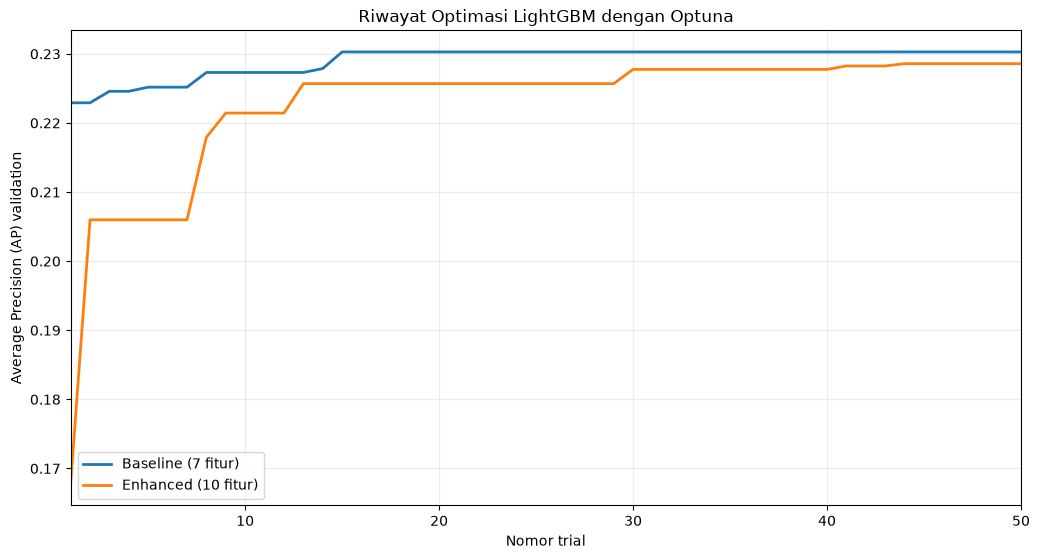

Gambar tersimpan: output_4_3_1\Gambar\Gambar_4_5_Riwayat_Optimasi_LightGBM_Optuna.png


In [101]:
def best_so_far_431(study):
    vals = [float(t.value) for t in sorted(study.trials, key=lambda t: t.number)]
    assert len(vals) == N_TRIALS_431 and np.isfinite(vals).all()
    return np.maximum.accumulate(np.asarray(vals))

best_so_far_baseline_431 = best_so_far_431(study_baseline)
best_so_far_enhanced_431 = best_so_far_431(study_enhanced)
trial_axis_431 = np.arange(1, N_TRIALS_431 + 1)

fig_431, ax_431 = plt.subplots(figsize=(10.5, 5.7))
ax_431.plot(trial_axis_431, best_so_far_baseline_431,
            label="Baseline (7 fitur)", linewidth=2)
ax_431.plot(trial_axis_431, best_so_far_enhanced_431,
            label="Enhanced (10 fitur)", linewidth=2)
ax_431.set_xlabel("Nomor trial")
ax_431.set_ylabel("Average Precision (AP) validation")
ax_431.set_title("Riwayat Optimasi LightGBM dengan Optuna")
ax_431.grid(alpha=0.25)
ax_431.legend()
ax_431.set_xlim(1, N_TRIALS_431)
fig_431.tight_layout()
file_figure_431 = FIGURE_DIR_431 / "Gambar_4_5_Riwayat_Optimasi_LightGBM_Optuna.png"
fig_431.savefig(file_figure_431, dpi=300, bbox_inches="tight")
print("Gambar 4.5 Riwayat Optimasi Hiperparameter LightGBM Menggunakan Optuna")
plt.show()
print("Gambar tersimpan:", file_figure_431)

### Penyimpanan model, parameter, metadata, dan audit akhir
Setiap model disimpan sebagai .joblib dengan informasi tujuh/sepuluh fitur dan daftar kategori training. JSON menyimpan parameter terbaik, versi perangkat lunak, AP validation, dan durasi eksperimen. File trial mentah Optuna disimpan pada SQLite dan CSV. Tidak ada evaluasi pada testing maupun penentuan threshold; tahap tersebut hanya dilakukan pada subbab berikutnya.

In [102]:
# Memastikan dataset, indeks, serta nilai fitur tidak berubah sejak sebelum optimasi.
for name, before_hash in SOURCE_FINGERPRINTS_431.items():
    after_hash = fingerprint_dataframe_431(globals()[name])
    assert after_hash == before_hash, f"Objek {name} berubah sejak tahap audit!"

# Menyimpan kosakata kategori dari TRAINING untuk persiapan inference/Streamlit.
category_vocab_431 = {
    col: X_train_baseline[col].cat.categories.tolist()
    for col in CAT_FEATURES
}
model_bundle_baseline_431 = {
    "model": model_baseline_best,
    "scenario": "baseline",
    "feature_names": list(BASELINE_FEATURES),
    "categorical_features": list(CAT_FEATURES),
    "category_vocab_from_training": category_vocab_431,
    "training_period": "2024-01-01 s.d. 2024-08-31",
    "validation_period": "2024-09-01 s.d. 2024-10-31",
    "prediction_horizon": "T-2h",
    "best_params": best_params_baseline,
}
model_bundle_enhanced_431 = {
    "model": model_enhanced_best,
    "scenario": "enhanced",
    "feature_names": list(ENHANCED_FEATURES),
    "historical_features": list(HISTORICAL_FEATURES),
    "categorical_features": list(CAT_FEATURES),
    "category_vocab_from_training": category_vocab_431,
    "training_period": "2024-01-01 s.d. 2024-08-31",
    "validation_period": "2024-09-01 s.d. 2024-10-31",
    "prediction_horizon": "T-2h, historis walk-forward",
    "best_params": best_params_enhanced,
}
joblib.dump(model_bundle_baseline_431, MODEL_DIR_431 / "Model_4_3_1_Baseline.joblib")
joblib.dump(model_bundle_enhanced_431, MODEL_DIR_431 / "Model_4_3_1_Enhanced.joblib")

# Simpan ringkasan mesin-baca untuk reproduksibilitas, tanpa metrik testing.
metadata_431 = {
    "subbab": "4.3.1",
    "seed": SEED_431,
    "trial_budget_per_scenario": N_TRIALS_431,
    "versions": VERSIONS_431,
    "common_params": COMMON_PARAMS_431,
    "search_space": SEARCH_SPACE_431,
    "feature_names_baseline": list(BASELINE_FEATURES),
    "feature_names_enhanced": list(ENHANCED_FEATURES),
    "categorical_vocab_from_training": category_vocab_431,
    "data_fingerprints_sha256": SOURCE_FINGERPRINTS_431,
    "baseline": {
        "best_params": best_params_baseline,
        "best_validation_ap": ap_baseline_431,
        "completed_trials": len(study_baseline.trials),
        "optimization_wall_seconds": study_baseline.user_attrs["optimization_wall_seconds"],
        "final_fit_seconds": fit_seconds_baseline_431,
    },
    "enhanced": {
        "best_params": best_params_enhanced,
        "best_validation_ap": ap_enhanced_431,
        "completed_trials": len(study_enhanced.trials),
        "optimization_wall_seconds": study_enhanced.user_attrs["optimization_wall_seconds"],
        "final_fit_seconds": fit_seconds_enhanced_431,
    },
    "delta_ap_percentage_points_enhanced_minus_baseline": delta_ap_pp_431,
    "testing_performance_evaluated": False,
    "threshold_optimized": False,
}
metadata_file_431 = OUTPUT_DIR_431 / "Metadata_Eksperimen_4_3_1.json"
metadata_file_431.write_text(
    json.dumps(metadata_431, indent=2, ensure_ascii=False), encoding="utf-8"
)

assert all(strict_by_feature_422.values())
assert all(no_self_source_422.values())
assert all(no_history_nan_422.values())
assert file_table_csv_431.exists() and file_table_html_431.exists()
assert file_figure_431.exists()
print("Audit akhir LULUS: fitur/label tidak berubah; tidak ada evaluasi testing.")
print("Model baseline dan enhanced, metadata JSON, SQLite, CSV trial, tabel, gambar: tersimpan.")

Audit akhir LULUS: fitur/label tidak berubah; tidak ada evaluasi testing.
Model baseline dan enhanced, metadata JSON, SQLite, CSV trial, tabel, gambar: tersimpan.


### Ringkasan hasil untuk pemeriksaan sebelum 4.3.2
Angka pada keluaran sel berikut merupakan hasil yang baru muncul setelah seluruh trial benar-benar dieksekusi. AP validation bukan AP testing; threshold akan dibahas pada 4.3.2 dan evaluasi testing pada 4.4.1. Peningkatan terhadap penelitian eksternal tidak boleh disimpulkan langsung dari angka accuracy atau AP yang tidak sebanding.

In [103]:
print("RINGKASAN EKSPERIMEN 4.3.1")
print(f"Baseline:  AP validation={ap_baseline_431:.6f}, "
      f"n_fitur={len(BASELINE_FEATURES)}, trial={len(study_baseline.trials)}")
print(f"Enhanced:  AP validation={ap_enhanced_431:.6f}, "
      f"n_fitur={len(ENHANCED_FEATURES)}, trial={len(study_enhanced.trials)}")
print(f"Selisih Enhanced − Baseline: {delta_ap_pp_431:+.4f} poin persentase")
print("Model terbaik baseline:", best_params_baseline)
print("Model terbaik enhanced:", best_params_enhanced)
print("Durasi optimasi baseline/enhanced (detik):",
      round(study_baseline.user_attrs["optimization_wall_seconds"], 2),
      round(study_enhanced.user_attrs["optimization_wall_seconds"], 2))
print("Durasi fit ulang baseline/enhanced (detik):",
      round(fit_seconds_baseline_431, 2),
      round(fit_seconds_enhanced_431, 2))
print("Keluaran siap untuk 4.3.2: model_baseline_best, model_enhanced_best,",
      "y_val_proba_baseline, y_val_proba_enhanced, y_val, study_baseline, study_enhanced")
print("Tidak ada prediksi testing, penilaian testing, atau optimasi threshold pada 4.3.1.")

RINGKASAN EKSPERIMEN 4.3.1
Baseline:  AP validation=0.230280, n_fitur=7, trial=50
Enhanced:  AP validation=0.228579, n_fitur=10, trial=50
Selisih Enhanced − Baseline: -0.1701 poin persentase
Model terbaik baseline: {'max_depth': 11, 'num_leaves': 15, 'learning_rate': 0.017758555324220587, 'n_estimators': 250, 'min_child_samples': 140}
Model terbaik enhanced: {'max_depth': 4, 'num_leaves': 15, 'learning_rate': 0.01646963061813987, 'n_estimators': 250, 'min_child_samples': 60}
Durasi optimasi baseline/enhanced (detik): 245.82 257.27
Durasi fit ulang baseline/enhanced (detik): 2.33 2.31
Keluaran siap untuk 4.3.2: model_baseline_best, model_enhanced_best, y_val_proba_baseline, y_val_proba_enhanced, y_val, study_baseline, study_enhanced
Tidak ada prediksi testing, penilaian testing, atau optimasi threshold pada 4.3.1.


## 4.3.2 Hasil Validasi dan Penentuan Ambang Klasifikasi

### 1. Inisialisasi pustaka, pengaturan tampilan, dan direktori keluaran
Pengaturan output memastikan semua teks tabel terlihat penuh. Tabel resmi disimpan sebagai CSV dan HTML, dengan lokasi prioritas folder Tabel Data di laptop Windows. File 4.3.1 tidak akan ditimpa.

In [104]:
import sys
import os
import json
import hashlib
import html
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import joblib
import lightgbm as lgb
import optuna
from optuna.trial import TrialState
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)
from IPython.display import display

# Tampilkan seluruh baris, kolom, dan teks panjang tanpa pemotongan.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1400)
pd.set_option("display.expand_frame_repr", False)

SEED_432 = 42
N_TRIALS_REQUIRED_432 = 50
THRESHOLD_GRID_432 = np.arange(1, 1000, dtype=np.int64) / 1000.0
AP_TOL_432 = 1e-8       # Toleransi numerik hasil refit terhadap Optuna.
TIE_TOL_432 = 1e-10      # Toleransi pembanding kesetaraan AP / F1.

OUTPUT_DIR_432 = Path("output_4_3_2")
HISTORY_DIR_432 = OUTPUT_DIR_432 / "Riwayat Threshold"
MODEL_DIR_432 = OUTPUT_DIR_432 / "Model dan Konfigurasi"
for folder in (OUTPUT_DIR_432, HISTORY_DIR_432, MODEL_DIR_432):
    folder.mkdir(parents=True, exist_ok=True)

WINDOWS_TABLE_DIR_432 = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures"
    r"\Semester 7 - SI\Skripsi\Tabel Data"
)
if sys.platform.startswith("win") and WINDOWS_TABLE_DIR_432.is_dir():
    TABLE_DIR_432 = WINDOWS_TABLE_DIR_432
else:
    TABLE_DIR_432 = OUTPUT_DIR_432 / "Tabel Data"
TABLE_DIR_432.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR_431_FOR_432 = Path("output_4_3_1")
VERSIONS_432 = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "lightgbm": lgb.__version__,
    "optuna": optuna.__version__,
    "scikit_learn": version("scikit-learn"),
}
print("Output tabel 4.3.2:", TABLE_DIR_432.resolve())
print("Output audit dan model 4.3.2:", OUTPUT_DIR_432.resolve())
print("Grid threshold:", len(THRESHOLD_GRID_432), "kandidat (0.001–0.999)")

Output tabel 4.3.2: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data
Output audit dan model 4.3.2: C:\Users\Lenovo\Documents\Skripsi\output_4_3_2
Grid threshold: 999 kandidat (0.001–0.999)


### Audit objek, model, dan trial resmi dari Subbab 4.3.1
- Memakai objek X_val_baseline, X_val_enhanced, y_val serta metadata fitur yang telah dibuat.
- Jika model atau study Optuna tidak lagi berada di memori, muat artefak final 4.3.1 yang disimpan sebelumnya menggunakan joblib dan SQLite.
- Setiap skenario harus memiliki 50 trial COMPLETE, konfigurasi hiperparameter terpilih yang cocok, dan model yang sudah di-fit pada training.
- Nilai dan urutan kolom kategorikal diperiksa, tanpa membentuk ulang fitur.

In [105]:
# Objek validasi dan definisi fitur harus ada dari eksekusi 4.2.1–4.2.2.
REQUIRED_INPUTS_432 = [
    "X_val_baseline", "X_val_enhanced", "y_val",
    "BASELINE_FEATURES", "ENHANCED_FEATURES", "CAT_FEATURES", "HISTORICAL_FEATURES"
]
missing_432 = [name for name in REQUIRED_INPUTS_432 if name not in globals()]
if missing_432:
    raise RuntimeError(
        "Matriks/target validation belum tersedia: " + ", ".join(missing_432)
        + ". Jalankan sel pembentukan matriks 4.2.1 dan 4.2.2 terlebih dahulu; "
          "jangan membaca ulang data mentah pada 4.3.2."
    )

EXPECTED_BASELINE_432 = [
    "month", "day_of_week", "scheduled_dep_hour", "op_unique_carrier",
    "dest", "distance", "crs_elapsed_time"
]
EXPECTED_HISTORY_432 = [
    "hist_delay_rate_carrier", "hist_delay_rate_dest",
    "hist_delay_rate_carrier_dest"
]
assert list(BASELINE_FEATURES) == EXPECTED_BASELINE_432
assert list(HISTORICAL_FEATURES) == EXPECTED_HISTORY_432
assert list(ENHANCED_FEATURES) == EXPECTED_BASELINE_432 + EXPECTED_HISTORY_432
assert list(CAT_FEATURES) == ["op_unique_carrier", "dest"]
assert X_val_baseline.shape == (57_593, 7)
assert X_val_enhanced.shape == (57_593, 10)
assert len(y_val) == 57_593
assert X_val_baseline.index.equals(X_val_enhanced.index)
assert X_val_baseline.index.equals(y_val.index)
assert list(X_val_baseline.columns) == EXPECTED_BASELINE_432
assert list(X_val_enhanced.columns) == EXPECTED_BASELINE_432 + EXPECTED_HISTORY_432
assert X_val_baseline.equals(X_val_enhanced[EXPECTED_BASELINE_432])
assert y_val.notna().all() and y_val.isin([0, 1]).all()
assert y_val.nunique() == 2, "Kedua kelas harus tersedia pada validation."

FORBIDDEN_432 = {
    "dep_delay", "dep_time", "arr_delay", "taxi_out", "wheels_off",
    "actual_elapsed_time", "target_delay", "t_gate_proxy", "t_cutoff",
    "cancelled", "wheels_on", "arr_time"
}
assert FORBIDDEN_432.isdisjoint(X_val_baseline.columns)
assert FORBIDDEN_432.isdisjoint(X_val_enhanced.columns)

# Memastikan setiap fitur kategori menggunakan kosakata yang sama pada kedua skenario.
for col in CAT_FEATURES:
    assert isinstance(X_val_baseline[col].dtype, pd.CategoricalDtype)
    assert isinstance(X_val_enhanced[col].dtype, pd.CategoricalDtype)
    assert X_val_baseline[col].cat.categories.equals(
        X_val_enhanced[col].cat.categories
    )
    assert not X_val_baseline[col].cat.ordered
    if "X_train_baseline" in globals():
        assert X_val_baseline[col].cat.categories.equals(
            X_train_baseline[col].cat.categories
        ), f"Kategori validation tidak berasal dari training: {col}"

for col in X_val_enhanced.columns.difference(CAT_FEATURES):
    assert pd.api.types.is_numeric_dtype(X_val_enhanced[col]), col
    assert np.isfinite(X_val_enhanced[col].dropna().to_numpy()).all()

# Fungsi fingerprint identik dengan yang digunakan di 4.3.1.
def fingerprint_432(obj):
    hashes = pd.util.hash_pandas_object(obj, index=True).to_numpy(dtype="uint64")
    return hashlib.sha256(hashes.tobytes()).hexdigest()

metadata_path_431_432 = OUTPUT_DIR_431_FOR_432 / "Metadata_Eksperimen_4_3_1.json"
if "metadata_431" not in globals() and metadata_path_431_432.exists():
    metadata_431 = json.loads(metadata_path_431_432.read_text(encoding="utf-8"))

# Study Optuna harus resmi, bukan hasil smoke test/percobaan teknis.
for name in ("baseline", "enhanced"):
    var_name = f"study_{name}"
    if var_name not in globals():
        sqlite_path = OUTPUT_DIR_431_FOR_432 / f"optuna_4_3_1_{name}.sqlite3"
        if not sqlite_path.exists():
            raise RuntimeError(
                f"Study resmi 4.3.1 untuk {name} tidak ditemukan. "
                "Jalankan 50 trial Optuna pada subbab 4.3.1 sampai selesai; "
                f"file yang diharapkan: {sqlite_path}"
            )
        globals()[var_name] = optuna.load_study(
            study_name=f"LightGBM_4_3_1_{name}",
            storage=f"sqlite:///{sqlite_path.resolve().as_posix()}"
        )
    study = globals()[var_name]
    complete = [t for t in study.trials if t.state == TrialState.COMPLETE]
    assert len(study.trials) == N_TRIALS_REQUIRED_432, (
        f"Trial {name} tidak lengkap: {len(study.trials)}/50. "
        "Selesaikan 4.3.1 sebelum melakukan validasi threshold."
    )
    assert len(complete) == N_TRIALS_REQUIRED_432
    assert study.direction == optuna.study.StudyDirection.MAXIMIZE
    assert np.isfinite(study.best_value)

# Muat bundle model terpilih, hanya jika model tidak lagi berada di memori.
for name in ("baseline", "enhanced"):
    model_name = f"model_{name}_best"
    bundle_name = f"model_bundle_{name}_431"
    if model_name not in globals():
        model_path = OUTPUT_DIR_431_FOR_432 / "Model" / f"Model_4_3_1_{name.title()}.joblib"
        if not model_path.exists():
            raise RuntimeError(
                f"Model final {name} dari 4.3.1 belum tersedia: {model_path}. "
                "Selesaikan sel pelatihan ulang model terpilih di 4.3.1."
            )
        globals()[bundle_name] = joblib.load(model_path)
        assert globals()[bundle_name]["scenario"] == name
        globals()[model_name] = globals()[bundle_name]["model"]

# Parameter terbaik dibandingkan dengan study, metadata, dan parameter model tersimpan.
for name, expected_cols in [
    ("baseline", EXPECTED_BASELINE_432),
    ("enhanced", EXPECTED_BASELINE_432 + EXPECTED_HISTORY_432),
]:
    study = globals()[f"study_{name}"]
    model = globals()[f"model_{name}_best"]
    params_key = f"best_params_{name}"
    if params_key not in globals():
        globals()[params_key] = dict(study.best_params)
    assert globals()[params_key] == dict(study.best_params)
    assert list(model.feature_name_) == expected_cols
    assert model.n_features_in_ == len(expected_cols)
    assert getattr(model, "classes_", np.array([])).tolist() == [0, 1]
    assert hasattr(model, "booster_")
    for param, value in study.best_params.items():
        assert model.get_params()[param] == value, (
            f"Parameter model {name}/{param} berbeda dengan hasil Optuna."
        )

    # Verifikasi kosakata kategori berdasarkan training tersimpan pada bundle, bila ada.
    bundle = globals().get(f"model_bundle_{name}_431", {})
    if bundle:
        assert bundle["feature_names"] == expected_cols
        vocab = bundle.get("category_vocab_from_training", {})
        X_val = X_val_baseline if name == "baseline" else X_val_enhanced
        for col in CAT_FEATURES:
            assert list(X_val[col].cat.categories) == vocab[col]

if "metadata_431" in globals():
    assert metadata_431["baseline"]["completed_trials"] == 50
    assert metadata_431["enhanced"]["completed_trials"] == 50
    for name in ("baseline", "enhanced"):
        assert metadata_431[name]["best_params"] == dict(globals()[f"study_{name}"].best_params)
    original_fp = metadata_431.get("data_fingerprints_sha256", {})
    for name in ("X_val_baseline", "X_val_enhanced", "y_val"):
        if name in original_fp:
            assert fingerprint_432(globals()[name]) == original_fp[name], (
                f"Data/urutan {name} berubah sejak optimasi 4.3.1."
            )

print("AUDIT 4.3.1: LULUS — 50 trial COMPLETE per skenario, model terlatih, "
      "matriks dan target validation identik dengan rancangan.")

AUDIT 4.3.1: LULUS — 50 trial COMPLETE per skenario, model terlatih, matriks dan target validation identik dengan rancangan.


### Prediksi probabilitas validasi dan pemeriksaan Average Precision
Probabilitas dihitung ulang hanya dengan predict_proba()[:, 1] sebagai pemeriksaan urutan; tidak ada pelatihan ulang. AP harus sesuai nilai trial terbaik Optuna dalam toleransi 1e-8.

In [106]:
# Snapshot isi model untuk audit bahwa proses selanjutnya tidak mengubah parameter.
def booster_hash_432(model):
    return hashlib.sha256(
        model.booster_.model_to_string().encode("utf-8")
    ).hexdigest()

MODEL_HASH_BEFORE_432 = {
    "baseline": booster_hash_432(model_baseline_best),
    "enhanced": booster_hash_432(model_enhanced_best),
}
VALIDATION_HASH_BEFORE_432 = {
    "X_val_baseline": fingerprint_432(X_val_baseline),
    "X_val_enhanced": fingerprint_432(X_val_enhanced),
    "y_val": fingerprint_432(y_val),
}

def compute_validate_proba_432(name, model, X_val, study):
    # Model telah terlatih pada 4.3.1; tidak ada fit pada fungsi ini.
    proba = np.asarray(model.predict_proba(X_val)[:, 1], dtype=float)
    assert proba.shape == (len(y_val),)
    assert np.isfinite(proba).all()
    assert ((0.0 <= proba) & (proba <= 1.0)).all()
    cached_name = f"y_val_proba_{name}"
    if cached_name in globals():
        old = np.asarray(globals()[cached_name], dtype=float)
        assert np.allclose(old, proba, rtol=1e-10, atol=1e-12), (
            f"Probabilitas validation tersimpan tidak sesuai urutan/model: {name}."
        )
    globals()[cached_name] = proba
    ap = float(average_precision_score(y_val, proba))
    assert np.isclose(ap, float(study.best_value), rtol=AP_TOL_432, atol=AP_TOL_432), (
        f"AP {name} = {ap:.10f} berbeda dari Optuna = {study.best_value:.10f}. "
        "Periksa model, data, label, urutan, versi library, dan parameter 4.3.1."
    )
    return ap

ap_val_baseline_432 = compute_validate_proba_432(
    "baseline", model_baseline_best, X_val_baseline, study_baseline
)
ap_val_enhanced_432 = compute_validate_proba_432(
    "enhanced", model_enhanced_best, X_val_enhanced, study_enhanced
)

print(f"AP validasi baseline: {ap_val_baseline_432:.6f}")
print(f"AP validasi enhanced: {ap_val_enhanced_432:.6f}")
print(f"Selisih AP enhanced - baseline: "
      f"{(ap_val_enhanced_432 - ap_val_baseline_432):+.6f} "
      f"({100 * (ap_val_enhanced_432 - ap_val_baseline_432):+.4f} poin persentase)")

AP validasi baseline: 0.230280
AP validasi enhanced: 0.228579
Selisih AP enhanced - baseline: -0.001701 (-0.1701 poin persentase)


### Pencarian threshold dengan F1-Score kelas Delayed
Threshold diuji secara deterministik pada grid 0,001–0,999 (999 kandidat). Untuk efisiensi, penghitungan TP, FP, dan FN dilakukan menggunakan pengurutan probabilitas dan numpy.searchsorted, lalu hasil threshold 0,5 dan terpilih diperiksa ulang dengan metrik Scikit-learn. Aturan tie-breaking adalah threshold paling tinggi bila terdapat F1 yang identik hingga toleransi numerik 1e-12.

In [107]:
def threshold_search_432(y_true, proba):
    y = np.asarray(y_true, dtype=np.int8)
    p = np.asarray(proba, dtype=float)
    assert y.shape == p.shape and len(y) == 57_593
    assert np.isin(y, [0, 1]).all() and np.isfinite(p).all()

    # Urutkan sekali; gunakan jumlah kumulatif positif untuk setiap cutoff.
    order = np.argsort(p, kind="stable")
    p_sorted = p[order]
    y_sorted = y[order]
    n = len(p)
    positive_total = int(y.sum())
    suffix_tp = np.r_[np.cumsum(y_sorted[::-1], dtype=np.int64)[::-1], 0]
    start_idx = np.searchsorted(p_sorted, THRESHOLD_GRID_432, side="left")
    tp = suffix_tp[start_idx]
    n_pred_positive = n - start_idx
    fp = n_pred_positive - tp
    fn = positive_total - tp

    precision = np.divide(
        tp, tp + fp, out=np.zeros(len(tp), dtype=float), where=(tp + fp) > 0
    )
    recall = np.divide(
        tp, tp + fn, out=np.zeros(len(tp), dtype=float), where=(tp + fn) > 0
    )
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros(len(tp), dtype=float), where=(precision + recall) > 0
    )

    history = pd.DataFrame({
        "threshold": THRESHOLD_GRID_432,
        "precision": precision,
        "recall": recall,
        "f1_delayed": f1,
        "tp": tp,
        "fp": fp,
        "fn": fn,
    })
    max_f1 = float(f1.max())
    tied = np.flatnonzero(np.isclose(f1, max_f1, atol=1e-12, rtol=0.0))
    selected_idx = int(tied[-1])  # Threshold tertinggi bila F1 identik.
    selected_threshold = float(THRESHOLD_GRID_432[selected_idx])

    # Threshold 0,500 harus masuk ke grid, sebagai pembanding yang adil.
    idx_default = np.flatnonzero(np.isclose(THRESHOLD_GRID_432, 0.5, atol=1e-15))
    assert len(idx_default) == 1
    assert f1[selected_idx] >= f1[idx_default[0]] - 1e-12

    # Audit hasil ringkasan dengan fungsi metrik resmi Scikit-learn.
    def metrics_at(t):
        pred = (p >= t).astype(np.int8)
        return {
            "threshold": float(t),
            "precision": float(precision_score(y, pred, pos_label=1, zero_division=0)),
            "recall": float(recall_score(y, pred, pos_label=1, zero_division=0)),
            "f1": float(f1_score(y, pred, pos_label=1, zero_division=0)),
        }
    standard = metrics_at(0.5)
    selected = metrics_at(selected_threshold)
    for report in (standard, selected):
        idx = int(np.flatnonzero(np.isclose(
            THRESHOLD_GRID_432, report["threshold"], atol=1e-15, rtol=0.0
        ))[0])
        for key, hist_key in (("precision", "precision"),
                              ("recall", "recall"), ("f1", "f1_delayed")):
            assert np.isclose(report[key], float(history.iloc[idx][hist_key]), atol=1e-12)
    assert selected["f1"] >= standard["f1"] - 1e-12
    return history, standard, selected

history_threshold_baseline_432, metrics_default_baseline_432, metrics_selected_baseline_432 = (
    threshold_search_432(y_val, y_val_proba_baseline)
)
history_threshold_enhanced_432, metrics_default_enhanced_432, metrics_selected_enhanced_432 = (
    threshold_search_432(y_val, y_val_proba_enhanced)
)

threshold_baseline_best_432 = metrics_selected_baseline_432["threshold"]
threshold_enhanced_best_432 = metrics_selected_enhanced_432["threshold"]
assert 0.001 <= threshold_baseline_best_432 <= 0.999
assert 0.001 <= threshold_enhanced_best_432 <= 0.999
assert len(history_threshold_baseline_432) == 999
assert len(history_threshold_enhanced_432) == 999

for name, standard, selected in (
    ("Baseline", metrics_default_baseline_432, metrics_selected_baseline_432),
    ("Enhanced", metrics_default_enhanced_432, metrics_selected_enhanced_432),
):
    print(f"{name}: threshold terpilih={selected['threshold']:.4f}; "
          f"F1 {standard['f1']:.6f} -> {selected['f1']:.6f}; "
          f"Precision {standard['precision']:.6f} -> {selected['precision']:.6f}; "
          f"Recall {standard['recall']:.6f} -> {selected['recall']:.6f}")

Baseline: threshold terpilih=0.2420; F1 0.119265 -> 0.296814; Precision 0.381706 -> 0.215587; Recall 0.070674 -> 0.476251
Enhanced: threshold terpilih=0.2500; F1 0.099542 -> 0.294048; Precision 0.402527 -> 0.207813; Recall 0.056794 -> 0.502610


### Tabel 4.9 — Perbandingan hasil validasi dan ambang klasifikasi
Tabel 4.9 adalah satu-satunya tabel utama pada subbab ini. Seluruh nilai dihitung dari output validasi dan baru dibulatkan untuk tampilan (enam desimal untuk AP dan metrik, empat desimal untuk threshold). Sebelum menampilkan tabel, notebook mencetak nomor dan judulnya.

In [108]:
# Susun tabel hanya dari hasil aktual pada validation.
rows_432 = [
    ("AP validasi", ap_val_baseline_432, ap_val_enhanced_432, "metric"),
    ("Threshold standar", 0.5, 0.5, "threshold"),
    ("Precision pada threshold 0,5", metrics_default_baseline_432["precision"],
     metrics_default_enhanced_432["precision"], "metric"),
    ("Recall pada threshold 0,5", metrics_default_baseline_432["recall"],
     metrics_default_enhanced_432["recall"], "metric"),
    ("F1-Score pada threshold 0,5", metrics_default_baseline_432["f1"],
     metrics_default_enhanced_432["f1"], "metric"),
    ("Threshold terpilih", threshold_baseline_best_432,
     threshold_enhanced_best_432, "threshold"),
    ("Precision pada threshold terpilih", metrics_selected_baseline_432["precision"],
     metrics_selected_enhanced_432["precision"], "metric"),
    ("Recall pada threshold terpilih", metrics_selected_baseline_432["recall"],
     metrics_selected_enhanced_432["recall"], "metric"),
    ("F1-Score pada threshold terpilih", metrics_selected_baseline_432["f1"],
     metrics_selected_enhanced_432["f1"], "metric"),
]
tabel_4_9 = pd.DataFrame([
    {
        "Metrik": metric,
        "Baseline": f"{b:.4f}" if kind == "threshold" else f"{b:.6f}",
        "Enhanced": f"{e:.4f}" if kind == "threshold" else f"{e:.6f}",
    }
    for metric, b, e, kind in rows_432
])

print("Tabel 4.9 Perbandingan Hasil Validasi dan Ambang Klasifikasi Kedua Skenario LightGBM")
display(tabel_4_9.style.set_properties(**{
    "white-space": "normal", "overflow-wrap": "break-word",
    "vertical-align": "top", "text-align": "left",
}))
print("Keterangan: 999 kandidat threshold (0,001–0,999) diuji untuk setiap skenario; "
      "F1 kelas Delayed; pada F1 identik, threshold tertinggi dipilih.")
print(f"Selisih AP enhanced - baseline: "
      f"{100*(ap_val_enhanced_432-ap_val_baseline_432):+.4f} poin persentase")
print(f"Selisih F1 terpilih enhanced - baseline: "
      f"{100*(metrics_selected_enhanced_432['f1']-metrics_selected_baseline_432['f1']):+.4f} "
      "poin persentase")

Tabel 4.9 Perbandingan Hasil Validasi dan Ambang Klasifikasi Kedua Skenario LightGBM


,Metrik,Baseline,Enhanced
0,AP validasi,0.230280,0.228579
1,Threshold standar,0.5000,0.5000
2,"Precision pada threshold 0,5",0.381706,0.402527
3,"Recall pada threshold 0,5",0.070674,0.056794
4,"F1-Score pada threshold 0,5",0.119265,0.099542
5,Threshold terpilih,0.2420,0.2500
6,Precision pada threshold terpilih,0.215587,0.207813
7,Recall pada threshold terpilih,0.476251,0.502610
8,F1-Score pada threshold terpilih,0.296814,0.294048


Keterangan: 999 kandidat threshold (0,001–0,999) diuji untuk setiap skenario; F1 kelas Delayed; pada F1 identik, threshold tertinggi dipilih.
Selisih AP enhanced - baseline: -0.1701 poin persentase
Selisih F1 terpilih enhanced - baseline: -0.2766 poin persentase


### Ekspor Tabel 4.9 ke CSV dan HTML untuk Microsoft Word
File HTML disusun dengan tiga kolom dan pengaturan lebar yang sesuai untuk halaman A4 portrait. Ekspor ditempatkan ke folder Windows Tabel Data jika ditemukan; jika tidak, ke output_4_3_2/Tabel Data. Riwayat 999 kandidat tiap skenario disimpan ke CSV terpisah sebagai bahan audit, tidak ditampilkan di output utama.

In [109]:
# Nama file baru; jangan menimpa tabel 4.3.1.
TABLE_NAME_432 = "Tabel_4_9_Perbandingan_Hasil_Validasi_dan_Ambang_Klasifikasi"
table_csv_432 = TABLE_DIR_432 / f"{TABLE_NAME_432}.csv"
table_html_432 = TABLE_DIR_432 / f"{TABLE_NAME_432}.html"

# Simpan tabel berisi nilai hasil validasi aktual.
tabel_4_9.to_csv(table_csv_432, index=False, encoding="utf-8-sig")
html_body_432 = tabel_4_9.to_html(index=False, border=0, escape=True)
html_doc_432 = """<!doctype html>
<html lang="id"><head><meta charset="utf-8"><title>Tabel 4.9</title>
<style>
@page { size: A4 portrait; margin: 18mm; }
body { font-family: "Times New Roman", serif; font-size: 11pt; color: #1b1b1b; }
h3 { font-size: 11pt; font-weight: bold; text-align: center; margin-bottom: 10px; }
table { border-collapse: collapse; width: 100%; table-layout: fixed; }
th, td { border: 1px solid #555; padding: 5px 7px; text-align: left;
 vertical-align: middle; white-space: normal; overflow-wrap: break-word; }
th { background: #edf1f5; text-align: center; }
th:first-child, td:first-child { width: 52%; }
th:nth-child(2), td:nth-child(2) { width: 24%; text-align: center; }
th:nth-child(3), td:nth-child(3) { width: 24%; text-align: center; }
.note { font-size: 9pt; margin-top: 8px; }
</style></head><body>
<h3>Tabel 4.9 Perbandingan Hasil Validasi dan Ambang Klasifikasi Kedua Skenario LightGBM</h3>
""" + html_body_432 + """
<p class="note">Keterangan: setiap skenario menggunakan 999 kandidat ambang
(0,001–0,999; interval 0,001). Ambang terbaik memaksimalkan F1-Score kelas
Delayed pada data validasi. Bila F1 identik, ambang terbesar dipilih.
AP dihitung dari probabilitas sebelum klasifikasi, tanpa menggunakan data testing.</p>
</body></html>"""
table_html_432.write_text(html_doc_432, encoding="utf-8")

# Simpan seluruh hasil kandidat threshold, tetapi jangan display 999 baris.
file_history_baseline_432 = HISTORY_DIR_432 / "Threshold_Validation_Baseline_999_Kandidat.csv"
file_history_enhanced_432 = HISTORY_DIR_432 / "Threshold_Validation_Enhanced_999_Kandidat.csv"
history_threshold_baseline_432.to_csv(
    file_history_baseline_432, index=False, encoding="utf-8-sig"
)
history_threshold_enhanced_432.to_csv(
    file_history_enhanced_432, index=False, encoding="utf-8-sig"
)
assert table_csv_432.exists() and table_html_432.exists()
assert file_history_baseline_432.exists() and file_history_enhanced_432.exists()
print("Tabel HTML untuk Word:", table_html_432.resolve())
print("Tabel CSV:", table_csv_432.resolve())
print("Riwayat 999 threshold per skenario telah disimpan untuk audit.")

Tabel HTML untuk Word: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_9_Perbandingan_Hasil_Validasi_dan_Ambang_Klasifikasi.html
Tabel CSV: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_9_Perbandingan_Hasil_Validasi_dan_Ambang_Klasifikasi.csv
Riwayat 999 threshold per skenario telah disimpan untuk audit.


### Pemilihan skenario untuk prototipe Streamlit
Kriteria berurutan: (1) AP validation tertinggi; (2) jika AP identik hingga toleransi 1e-10, F1 pada threshold terbaik; (3) jika masih identik, pilih baseline yang lebih sederhana. Threshold selalu berasal dari model yang dipilih, bukan milik skenario lain.

In [110]:
# Pemilihan dilakukan hanya dengan hasil validation.
if abs(ap_val_enhanced_432 - ap_val_baseline_432) > TIE_TOL_432:
    scenario_selected_432 = (
        "enhanced" if ap_val_enhanced_432 > ap_val_baseline_432 else "baseline"
    )
    selection_reason_432 = "AP validasi lebih tinggi"
else:
    f1_b = metrics_selected_baseline_432["f1"]
    f1_e = metrics_selected_enhanced_432["f1"]
    if abs(f1_e - f1_b) > TIE_TOL_432:
        scenario_selected_432 = "enhanced" if f1_e > f1_b else "baseline"
        selection_reason_432 = "AP setara; F1-Score validasi terpilih lebih tinggi"
    else:
        scenario_selected_432 = "baseline"
        selection_reason_432 = "AP dan F1 setara; baseline dipilih karena lebih sederhana"

selected_config_432 = {
    "baseline": {
        "model": model_baseline_best,
        "ap": ap_val_baseline_432,
        "threshold": threshold_baseline_best_432,
        "metrics": metrics_selected_baseline_432,
        "features": list(BASELINE_FEATURES),
        "best_params": dict(best_params_baseline),
    },
    "enhanced": {
        "model": model_enhanced_best,
        "ap": ap_val_enhanced_432,
        "threshold": threshold_enhanced_best_432,
        "metrics": metrics_selected_enhanced_432,
        "features": list(ENHANCED_FEATURES),
        "best_params": dict(best_params_enhanced),
    },
}
model_deployment_432 = selected_config_432[scenario_selected_432]["model"]
threshold_deployment_432 = selected_config_432[scenario_selected_432]["threshold"]
feature_names_deployment_432 = selected_config_432[scenario_selected_432]["features"]

print("MODEL TERPILIH UNTUK DEPLOYMENT STREAMLIT")
print("Skenario          :", scenario_selected_432.title())
print(f"AP validasi       : {selected_config_432[scenario_selected_432]['ap']:.6f}")
print(f"Threshold terpilih: {threshold_deployment_432:.4f}")
print("Jumlah fitur      :", len(feature_names_deployment_432))
print("Alasan pemilihan  :", selection_reason_432)
print("Catatan: Pemilihan berbasis validation, bukan testing.")

MODEL TERPILIH UNTUK DEPLOYMENT STREAMLIT
Skenario          : Baseline
AP validasi       : 0.230280
Threshold terpilih: 0.2420
Jumlah fitur      : 7
Alasan pemilihan  : AP validasi lebih tinggi
Catatan: Pemilihan berbasis validation, bukan testing.


### Mengunci model, threshold, fitur, dan metadata sebelum evaluasi testing
Kedua model beserta threshold masing-masing disimpan dalam artefak baru 4.3.2. Artefak khusus deployment juga dibuat untuk Streamlit. Sidik jari SHA-256 model dan file dicatat agar konfigurasi dapat dibandingkan pada Subbab 4.4 tanpa mengubah hasil validasi.

In [111]:
# Gunakan vocab kategori dari training; tidak mempelajari kategori baru dari validation.
if "category_vocab_431" in globals():
    category_vocab_432 = {
        c: list(category_vocab_431[c]) for c in CAT_FEATURES
    }
elif "metadata_431" in globals() and "categorical_vocab_from_training" in metadata_431:
    category_vocab_432 = {
        c: list(metadata_431["categorical_vocab_from_training"][c])
        for c in CAT_FEATURES
    }
else:
    category_vocab_432 = {
        c: list(X_val_baseline[c].cat.categories) for c in CAT_FEATURES
    }

for c in CAT_FEATURES:
    assert list(X_val_baseline[c].cat.categories) == category_vocab_432[c]
    assert list(X_val_enhanced[c].cat.categories) == category_vocab_432[c]

# Periksa kembali bahwa model dan data validation tidak berubah sejak audit.
for scenario, model in (
    ("baseline", model_baseline_best),
    ("enhanced", model_enhanced_best),
):
    assert booster_hash_432(model) == MODEL_HASH_BEFORE_432[scenario]
for name, before_hash in VALIDATION_HASH_BEFORE_432.items():
    assert fingerprint_432(globals()[name]) == before_hash

# Model disimpan dalam file baru, tanpa menimpa hasil 4.3.1.
ARTIFACTS_432 = {}
for scenario in ("baseline", "enhanced"):
    config = selected_config_432[scenario]
    bundle = {
        "source_subchapter": "4.3.1",
        "validation_subchapter": "4.3.2",
        "scenario": scenario,
        "model": config["model"],
        "threshold": float(config["threshold"]),
        "feature_names": config["features"],
        "categorical_features": list(CAT_FEATURES),
        "category_vocab_from_training": category_vocab_432,
        "best_params": config["best_params"],
        "validation_ap": float(config["ap"]),
        "validation_precision": float(config["metrics"]["precision"]),
        "validation_recall": float(config["metrics"]["recall"]),
        "validation_f1": float(config["metrics"]["f1"]),
        "random_seed": SEED_432,
        "validation_period": "2024-09-01 s.d. 2024-10-31",
        "prediction_horizon": "T-2h",
        "versions": VERSIONS_432,
        "model_sha256": MODEL_HASH_BEFORE_432[scenario],
    }
    output_file = MODEL_DIR_432 / f"Model_4_3_2_{scenario.title()}_Threshold_Terkunci.joblib"
    joblib.dump(bundle, output_file)
    ARTIFACTS_432[scenario] = str(output_file)

# Artefak deployment adalah salinan konfigurasi model yang terpilih,
# termasuk threshold dari skenario yang sama.
file_deployment_432 = MODEL_DIR_432 / "Model_4_3_2_Terpilih_Streamlit.joblib"
joblib.dump(joblib.load(ARTIFACTS_432[scenario_selected_432]), file_deployment_432)

# Hash file untuk audit sebelum periode pengujian.
def sha256_file_432(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

artifact_sha256_432 = {
    name: sha256_file_432(path) for name, path in ARTIFACTS_432.items()
}
artifact_sha256_432["selected_streamlit"] = sha256_file_432(file_deployment_432)

metadata_432 = {
    "subchapter": "4.3.2",
    "objective_for_hyperparameter_tuning": "validation_average_precision",
    "objective_for_threshold_selection": "validation_f1_delayed",
    "threshold_grid": {"min": 0.001, "max": 0.999, "step": 0.001,
                       "count": len(THRESHOLD_GRID_432)},
    "tie_break_threshold": "highest_threshold_at_equal_f1",
    "ap_match_atol_rtol": AP_TOL_432,
    "model_selection_tolerance": TIE_TOL_432,
    "seed": SEED_432,
    "library_versions": VERSIONS_432,
    "validation_data_hashes": VALIDATION_HASH_BEFORE_432,
    "model_hashes": MODEL_HASH_BEFORE_432,
    "model_files_sha256": artifact_sha256_432,
    "model_files": ARTIFACTS_432,
    "selected_deployment_model_file": str(file_deployment_432),
    "selected_deployment_scenario": scenario_selected_432,
    "selection_reason": selection_reason_432,
    "baseline": {
        "best_params": dict(best_params_baseline),
        "ap": ap_val_baseline_432,
        "threshold": threshold_baseline_best_432,
        "metrics_at_0_5": metrics_default_baseline_432,
        "metrics_at_selected": metrics_selected_baseline_432,
    },
    "enhanced": {
        "best_params": dict(best_params_enhanced),
        "ap": ap_val_enhanced_432,
        "threshold": threshold_enhanced_best_432,
        "metrics_at_0_5": metrics_default_enhanced_432,
        "metrics_at_selected": metrics_selected_enhanced_432,
    },
    "testing_evaluated": False,
    "retraining_performed": False,
}
metadata_file_432 = OUTPUT_DIR_432 / "Metadata_Validasi_dan_Threshold_4_3_2.json"
metadata_file_432.write_text(
    json.dumps(metadata_432, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Artefak kedua model dan threshold terkunci tersimpan.")
print("Model deployment:", file_deployment_432.resolve())
print("Metadata konfigurasi:", metadata_file_432.resolve())

Artefak kedua model dan threshold terkunci tersimpan.
Model deployment: C:\Users\Lenovo\Documents\Skripsi\output_4_3_2\Model dan Konfigurasi\Model_4_3_2_Terpilih_Streamlit.joblib
Metadata konfigurasi: C:\Users\Lenovo\Documents\Skripsi\output_4_3_2\Metadata_Validasi_dan_Threshold_4_3_2.json


### Audit akhir Subbab 4.3.2
Periksa kembali akurasi perhitungan, kesamaan AP dengan Optuna, tidak adanya refit, kestabilan matriks validation, serta keberadaan file HTML untuk Word. Tabel evaluasi testing dan confusion matrix tidak dihasilkan pada subbab ini.

In [112]:
# Bukti akhir: tidak ada perubahan model/validation pada 4.3.2.
for scenario, model in (
    ("baseline", model_baseline_best), ("enhanced", model_enhanced_best)
):
    assert booster_hash_432(model) == MODEL_HASH_BEFORE_432[scenario]
for name, before_hash in VALIDATION_HASH_BEFORE_432.items():
    assert fingerprint_432(globals()[name]) == before_hash

assert np.isclose(ap_val_baseline_432, study_baseline.best_value,
                  atol=AP_TOL_432, rtol=AP_TOL_432)
assert np.isclose(ap_val_enhanced_432, study_enhanced.best_value,
                  atol=AP_TOL_432, rtol=AP_TOL_432)
assert metrics_selected_baseline_432["f1"] >= metrics_default_baseline_432["f1"] - 1e-12
assert metrics_selected_enhanced_432["f1"] >= metrics_default_enhanced_432["f1"] - 1e-12
assert all(Path(p).exists() for p in ARTIFACTS_432.values())
assert file_deployment_432.exists() and metadata_file_432.exists()
assert table_html_432.exists() and table_csv_432.exists()
assert file_history_baseline_432.exists() and file_history_enhanced_432.exists()
assert metadata_432["testing_evaluated"] is False
assert metadata_432["retraining_performed"] is False
assert metadata_432["selected_deployment_scenario"] == scenario_selected_432

print("AUDIT AKHIR 4.3.2: LULUS")
print("50 trial Optuna masing-masing skenario telah diverifikasi.")
print("Model dan data validation tidak berubah; fit() tidak dipanggil.")
print("AP validasi, pencarian 999 threshold, dan pemilihan model konsisten.")
print("Tabel 4.9 HTML/CSV, riwayat threshold, serta konfigurasi terkunci tersedia.")
print("Belum ada evaluasi atau optimasi berdasarkan data testing.")
print("Hasil validasi pada threshold terpilih masih bersifat in-sample untuk threshold tuning;")
print("evaluasi independen dilakukan nanti pada 4.4 dengan konfigurasi yang dibekukan.")

AUDIT AKHIR 4.3.2: LULUS
50 trial Optuna masing-masing skenario telah diverifikasi.
Model dan data validation tidak berubah; fit() tidak dipanggil.
AP validasi, pencarian 999 threshold, dan pemilihan model konsisten.
Tabel 4.9 HTML/CSV, riwayat threshold, serta konfigurasi terkunci tersedia.
Belum ada evaluasi atau optimasi berdasarkan data testing.
Hasil validasi pada threshold terpilih masih bersifat in-sample untuk threshold tuning;
evaluasi independen dilakukan nanti pada 4.4 dengan konfigurasi yang dibekukan.


## BAB IV — 4.4 Hasil dan Pembahasan
### 4.4.1 Evaluasi Komparatif Kinerja Skenario Baseline dan Enhanced

### Inisialisasi library, direktori output, dan konfigurasi evaluasi
Menggunakan model dan threshold yang dibekukan pada 4.3.2. CSV/HTML tabel dikirim ke folder OneDrive skripsi jika tersedia; di lingkungan non-Windows, gunakan folder lokal output_4_4_1/Tabel Data. Grafik disimpan pada output_4_4_1/Gambar, minimal 300 dpi.

In [113]:
import sys
import json
import hashlib
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
import optuna
from optuna.trial import TrialState
from IPython.display import display
from sklearn.metrics import (
    average_precision_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    roc_curve, precision_recall_curve,
)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1400)
pd.set_option("display.expand_frame_repr", False)

SEED_441 = 42
EXPECTED_TEST_SIZE_441 = 56_936
EXPECTED_DELAYED_441 = 10_296
BENCHMARK_ACCURACY_441 = 0.732  # Referensi kontekstual, bukan target optimasi
MAKE_ROC_441 = True             # Gambar 4.7 opsional
RUN_BLOCK_BOOTSTRAP_441 = True  # Tidak melatih/mengubah model
BOOTSTRAP_REPS_441 = 1000

OUTPUT_DIR_441 = Path("output_4_4_1")
FIGURE_DIR_441 = OUTPUT_DIR_441 / "Gambar"
AUDIT_DIR_441 = OUTPUT_DIR_441 / "Audit"
for folder in (OUTPUT_DIR_441, FIGURE_DIR_441, AUDIT_DIR_441):
    folder.mkdir(parents=True, exist_ok=True)

WINDOWS_TABLE_DIR_441 = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures"
    r"\Semester 7 - SI\Skripsi\Tabel Data"
)
if sys.platform.startswith("win") and WINDOWS_TABLE_DIR_441.is_dir():
    TABLE_DIR_441 = WINDOWS_TABLE_DIR_441
else:
    TABLE_DIR_441 = OUTPUT_DIR_441 / "Tabel Data"
    if sys.platform.startswith("win"):
        print("Folder OneDrive belum ditemukan; gunakan folder output lokal.")
TABLE_DIR_441.mkdir(parents=True, exist_ok=True)

VERSIONS_441 = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "lightgbm": lgb.__version__,
    "scikit_learn": version("scikit-learn"),
}
print("Subbab 4.4.1 — Evaluasi FINAL hold-out (tanpa fit/Optuna)")
print("Lokasi tabel:", TABLE_DIR_441.resolve())
print("Lokasi gambar:", FIGURE_DIR_441.resolve())
print("Konfigurasi bootstrap:", RUN_BLOCK_BOOTSTRAP_441, "; replikasi:", BOOTSTRAP_REPS_441)

Subbab 4.4.1 — Evaluasi FINAL hold-out (tanpa fit/Optuna)
Lokasi tabel: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data
Lokasi gambar: C:\Users\Lenovo\Documents\Skripsi\output_4_4_1\Gambar
Konfigurasi bootstrap: True ; replikasi: 1000


### Audit keberadaan matriks testing dan identitas observasi
Sel ini hanya membaca objek dari 4.2.1–4.2.2. Jika objek hilang setelah kernel di-restart, jalankan sel prapemrosesan pada notebook gabungan; jangan menggantinya dengan dataset sintetis atau menghitung fitur historis baru pada bagian ini.

In [114]:
REQUIRED_INPUTS_441 = [
    "X_test_baseline", "X_test_enhanced", "y_test",
    "BASELINE_FEATURES", "ENHANCED_FEATURES", "CAT_FEATURES", "HISTORICAL_FEATURES",
]
missing_inputs_441 = [n for n in REQUIRED_INPUTS_441 if n not in globals()]
if missing_inputs_441:
    raise RuntimeError(
        "Objek testing belum ada: " + ", ".join(missing_inputs_441)
        + ". Jalankan sel 4.1–4.2.2 (dan 4.3.1–4.3.2 untuk model terkunci) "
          "dalam kernel yang sama. Jangan memuat dataset pengganti."
    )

EXPECTED_BASELINE_441 = [
    "month", "day_of_week", "scheduled_dep_hour", "op_unique_carrier",
    "dest", "distance", "crs_elapsed_time"
]
EXPECTED_HISTORY_441 = [
    "hist_delay_rate_carrier", "hist_delay_rate_dest",
    "hist_delay_rate_carrier_dest"
]
assert list(BASELINE_FEATURES) == EXPECTED_BASELINE_441, "Daftar baseline berubah"
assert list(HISTORICAL_FEATURES) == EXPECTED_HISTORY_441, "Daftar historis berubah"
assert list(ENHANCED_FEATURES) == EXPECTED_BASELINE_441 + EXPECTED_HISTORY_441
assert list(CAT_FEATURES) == ["op_unique_carrier", "dest"]
assert X_test_baseline.shape == (EXPECTED_TEST_SIZE_441, 7)
assert X_test_enhanced.shape == (EXPECTED_TEST_SIZE_441, 10)
assert len(y_test) == EXPECTED_TEST_SIZE_441
assert X_test_baseline.index.equals(X_test_enhanced.index)
assert X_test_baseline.index.equals(y_test.index)
assert X_test_baseline.columns.tolist() == EXPECTED_BASELINE_441
assert X_test_enhanced.columns.tolist() == EXPECTED_BASELINE_441 + EXPECTED_HISTORY_441
assert X_test_enhanced[EXPECTED_BASELINE_441].equals(X_test_baseline)
assert y_test.notna().all() and y_test.isin([0, 1]).all()
assert int(y_test.sum()) == EXPECTED_DELAYED_441
assert int((y_test == 0).sum()) == 46_640

FORBIDDEN_FEATURES_441 = {
    "dep_delay", "target_delay", "dep_time", "arr_delay", "taxi_out",
    "wheels_off", "wheels_on", "taxi_in", "arr_time", "actual_elapsed_time",
    "air_time", "carrier_delay", "weather_delay", "nas_delay",
    "security_delay", "late_aircraft_delay", "cancelled", "diverted",
    "t_cutoff", "t_gate_proxy", "scheduled_dep_datetime", "flight_uid"
}
assert FORBIDDEN_FEATURES_441.isdisjoint(X_test_baseline.columns)
assert FORBIDDEN_FEATURES_441.isdisjoint(X_test_enhanced.columns)
for col in CAT_FEATURES:
    assert isinstance(X_test_baseline[col].dtype, pd.CategoricalDtype)
    assert isinstance(X_test_enhanced[col].dtype, pd.CategoricalDtype)
    assert X_test_baseline[col].cat.categories.equals(
        X_test_enhanced[col].cat.categories
    )
    assert not X_test_baseline[col].cat.ordered
for col in X_test_enhanced.columns.difference(CAT_FEATURES):
    assert pd.api.types.is_numeric_dtype(X_test_enhanced[col]), col
    assert np.isfinite(X_test_enhanced[col].dropna().to_numpy()).all(), col
for col in HISTORICAL_FEATURES:
    assert X_test_enhanced[col].dropna().between(0, 1).all(), col

# Kode OGG pada testing tidak ada pada kosakata training sehingga tetap NaN.
assert int(X_test_baseline["dest"].isna().sum()) == 41, (
    "Jumlah kategori destinasi tak dikenal berubah; audit data/kategori dahulu."
)

# Jika audit 4.2.2 masih tersimpan, periksa tanda kelulusannya tanpa menghitung ulang fitur.
for audit_name in ("strict_by_feature_422", "no_self_source_422", "no_history_nan_422"):
    if audit_name in globals():
        assert all(bool(v) for v in globals()[audit_name].values()), audit_name

print("Audit matriks testing: LULUS")
print("Baseline", X_test_baseline.shape, "; Enhanced", X_test_enhanced.shape)
print("On-Time:", int((y_test == 0).sum()), "; Delayed:", int(y_test.sum()))
print("Kategori dest tak dikenal pada testing:", int(X_test_baseline['dest'].isna().sum()))

Audit matriks testing: LULUS
Baseline (56936, 7) ; Enhanced (56936, 10)
On-Time: 46640 ; Delayed: 10296
Kategori dest tak dikenal pada testing: 41


### Memuat konfigurasi terkunci dan mengaudit provenance 4.3.1–4.3.2
Sumber konfigurasi yang digunakan harus berkas hasil resmi: Metadata_Eksperimen_4_3_1.json, Metadata_Validasi_dan_Threshold_4_3_2.json, serta dua bundle Model_4_3_2_*_Threshold_Terkunci.joblib. Berkas dari uji teknis tidak boleh menggantikan berkas resmi. Model yang sudah ada di memori wajib cocok secara bitwise dengan model tersimpan.

In [115]:
SOURCE_DIR_431_441 = Path("output_4_3_1")
SOURCE_DIR_432_441 = Path("output_4_3_2")
META_FILE_431_441 = SOURCE_DIR_431_441 / "Metadata_Eksperimen_4_3_1.json"
META_FILE_432_441 = SOURCE_DIR_432_441 / "Metadata_Validasi_dan_Threshold_4_3_2.json"
BUNDLE_FILES_441 = {
    scenario: SOURCE_DIR_432_441 / "Model dan Konfigurasi" /
              f"Model_4_3_2_{scenario.title()}_Threshold_Terkunci.joblib"
    for scenario in ("baseline", "enhanced")
}
needed_files_441 = [META_FILE_431_441, META_FILE_432_441, *BUNDLE_FILES_441.values()]
absent_files_441 = [str(p) for p in needed_files_441 if not p.is_file()]
if absent_files_441:
    raise RuntimeError(
        "Artefak FINAL prasyarat 4.3.1–4.3.2 belum ditemukan:\n- "
        + "\n- ".join(absent_files_441)
        + "\nSelesaikan dan jalankan 50 trial resmi serta seluruh sel 4.3.2 pada laptop "
          "sampai model/threshold terkunci tersimpan. Jangan evaluasi testing dahulu."
    )

metadata_431_for_441 = json.loads(META_FILE_431_441.read_text(encoding="utf-8"))
metadata_432_for_441 = json.loads(META_FILE_432_441.read_text(encoding="utf-8"))
assert metadata_432_for_441.get("testing_evaluated") is False, (
    "Metadata menunjukkan testing sudah pernah dievaluasi. Audit penggunaan hold-out dahulu."
)
assert metadata_432_for_441.get("retraining_performed") is False
assert metadata_431_for_441["baseline"]["completed_trials"] == 50
assert metadata_431_for_441["enhanced"]["completed_trials"] == 50
assert metadata_432_for_441["selected_deployment_scenario"] in ("baseline", "enhanced")

# Membaca status trial Optuna dari SQLite saja, tanpa menjalankan study.optimize().
# Menolak hasil tidak lengkap dan memverifikasi asal data train/validation.
for scenario in ("baseline", "enhanced"):
    sqlite_file = SOURCE_DIR_431_441 / f"optuna_4_3_1_{scenario}.sqlite3"
    if not sqlite_file.is_file():
        raise RuntimeError(
            f"Riwayat 50 trial resmi tidak ditemukan: {sqlite_file}. "
            "Jalankan 4.3.1 resmi sampai selesai atau pulihkan file SQLite asli."
        )
    study_ro = optuna.load_study(
        study_name=f"LightGBM_4_3_1_{scenario}",
        storage=f"sqlite:///{sqlite_file.resolve().as_posix()}"
    )
    assert len(study_ro.trials) == 50
    assert all(t.state == TrialState.COMPLETE for t in study_ro.trials), scenario
    assert study_ro.direction == optuna.study.StudyDirection.MAXIMIZE
    assert dict(study_ro.best_params) == metadata_431_for_441[scenario]["best_params"]
    assert np.isclose(
        study_ro.best_value,
        metadata_431_for_441[scenario]["best_validation_ap"],
        atol=1e-8, rtol=1e-8
    )
    signature = study_ro.user_attrs.get("experiment_signature")
    assert isinstance(signature, dict), "Metadata jejak trial Optuna tidak tersedia"
    ref_fingerprints = metadata_431_for_441["data_fingerprints_sha256"]
    assert signature["train_feature_sha256"] == ref_fingerprints[f"X_train_{scenario}"]
    assert signature["val_feature_sha256"] == ref_fingerprints[f"X_val_{scenario}"]
    assert signature["train_target_sha256"] == ref_fingerprints["y_train"]
    assert signature["val_target_sha256"] == ref_fingerprints["y_val"]
    print(f"Audit Optuna {scenario}: 50/50 trial COMPLETE, best params/AP cocok.")

# Hash booster dan hash file joblib digunakan untuk memastikan artefak tidak berubah.
def sha256_file_441(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def booster_sha256_441(model):
    assert hasattr(model, "booster_"), "Model belum terlatih"
    return hashlib.sha256(model.booster_.model_to_string().encode("utf-8")).hexdigest()

def dataframe_sha256_441(frame):
    hashes = pd.util.hash_pandas_object(frame, index=True).to_numpy(dtype="uint64")
    return hashlib.sha256(hashes.tobytes()).hexdigest()

BUNDLES_441 = {}
MODELS_441 = {}
THRESHOLDS_441 = {}
MODEL_HASHES_BEFORE_441 = {}
MODEL_PARAMS_BEFORE_441 = {}

for scenario in ("baseline", "enhanced"):
    file = BUNDLE_FILES_441[scenario]
    expected_file_hash = metadata_432_for_441["model_files_sha256"][scenario]
    assert sha256_file_441(file) == expected_file_hash, (
        f"File model terkunci {scenario} berbeda dari hash metadata 4.3.2."
    )
    bundle = joblib.load(file)
    assert bundle["scenario"] == scenario
    assert bundle["source_subchapter"] == "4.3.1"
    assert bundle["validation_subchapter"] == "4.3.2"
    assert bundle["prediction_horizon"] == "T-2h"
    assert bundle["validation_period"] == "2024-09-01 s.d. 2024-10-31"

    model = bundle["model"]
    assert isinstance(model, lgb.LGBMClassifier)
    expected_features = EXPECTED_BASELINE_441 if scenario == "baseline" else (
        EXPECTED_BASELINE_441 + EXPECTED_HISTORY_441
    )
    assert bundle["feature_names"] == expected_features
    assert list(model.feature_name_) == expected_features
    assert model.n_features_in_ == len(expected_features)
    assert np.array_equal(model.classes_, [0, 1])
    assert list(bundle["categorical_features"]) == list(CAT_FEATURES)

    for col in CAT_FEATURES:
        vocab = list(bundle["category_vocab_from_training"][col])
        assert list(X_test_baseline[col].cat.categories) == vocab, (
            f"Kategori testing {col} tidak sesuai training pada bundle {scenario}."
        )
        assert list(X_test_enhanced[col].cat.categories) == vocab
        assert vocab == list(metadata_431_for_441["categorical_vocab_from_training"][col])

    trained_params = dict(bundle["best_params"])
    assert trained_params == metadata_431_for_441[scenario]["best_params"]
    assert trained_params == metadata_432_for_441[scenario]["best_params"]
    for key, value in trained_params.items():
        assert model.get_params()[key] == value, f"Hiperparameter berubah: {scenario}/{key}"

    # Bandingkan threshold dan nilai AP validation dengan yang dibekukan pada 4.3.2.
    threshold = float(bundle["threshold"])
    assert 0.001 <= threshold <= 0.999
    assert np.isclose(threshold, metadata_432_for_441[scenario]["threshold"], atol=1e-12)
    assert np.isclose(threshold,
                      metadata_432_for_441[scenario]["metrics_at_selected"]["threshold"],
                      atol=1e-12)
    assert np.isclose(float(bundle["validation_ap"]),
                      float(metadata_432_for_441[scenario]["ap"]), atol=1e-10)
    assert np.isclose(float(bundle["validation_ap"]),
                      float(metadata_431_for_441[scenario]["best_validation_ap"]), atol=1e-8)

    model_hash = booster_sha256_441(model)
    assert model_hash == bundle["model_sha256"]
    assert model_hash == metadata_432_for_441["model_hashes"][scenario]

    # Jika model sebelumnya masih ada di kernel, harus sama dengan model terkunci di file.
    memory_model = globals().get(f"model_{scenario}_best")
    if memory_model is not None:
        assert booster_sha256_441(memory_model) == model_hash, (
            f"Model memori {scenario} berbeda dari bundle terkunci."
        )

    BUNDLES_441[scenario] = bundle
    MODELS_441[scenario] = model
    THRESHOLDS_441[scenario] = threshold
    MODEL_HASHES_BEFORE_441[scenario] = model_hash
    MODEL_PARAMS_BEFORE_441[scenario] = dict(model.get_params())

TEST_DATA_HASHES_BEFORE_441 = {
    "X_test_baseline": dataframe_sha256_441(X_test_baseline),
    "X_test_enhanced": dataframe_sha256_441(X_test_enhanced),
    "y_test": dataframe_sha256_441(y_test),
}

print("Audit model dan threshold terkunci: LULUS")
for s in ("baseline", "enhanced"):
    print(f"- {s.title()}: {len(BUNDLES_441[s]['feature_names'])} fitur; "
          f"threshold={THRESHOLDS_441[s]:.4f}; "
          f"AP validasi={BUNDLES_441[s]['validation_ap']:.6f}")
print("- Skenario Streamlit dipilih sebelumnya:",
      metadata_432_for_441["selected_deployment_scenario"].title())

Audit Optuna baseline: 50/50 trial COMPLETE, best params/AP cocok.
Audit Optuna enhanced: 50/50 trial COMPLETE, best params/AP cocok.
Audit model dan threshold terkunci: LULUS
- Baseline: 7 fitur; threshold=0.2420; AP validasi=0.230280
- Enhanced: 10 fitur; threshold=0.2500; AP validasi=0.228579
- Skenario Streamlit dipilih sebelumnya: Baseline


### Prediksi testing menggunakan konfigurasi yang telah dibekukan
Tidak ada proses pelatihan atau optimasi. Untuk setiap skenario, predict_proba()[:, 1] menghasilkan probabilitas Delayed; label prediksi memakai threshold masing-masing dari 4.3.2. AP dan ROC-AUC dihitung dari probabilitas, sedangkan Accuracy, Precision, Recall, F1 dan confusion matrix dihitung dari label prediksi.

In [116]:
def evaluate_locked_model_441(scenario, X_test):
    model = MODELS_441[scenario]
    threshold = THRESHOLDS_441[scenario]
    probabilities = np.asarray(model.predict_proba(X_test)[:, 1], dtype=np.float64)
    assert probabilities.shape == (EXPECTED_TEST_SIZE_441,)
    assert np.isfinite(probabilities).all(), f"Probabilitas tidak finite: {scenario}"
    assert ((probabilities >= 0) & (probabilities <= 1)).all(), scenario

    predictions = (probabilities >= threshold).astype(np.uint8)
    y_actual = y_test.to_numpy(dtype=np.uint8)
    cm = confusion_matrix(y_actual, predictions, labels=[0, 1])
    assert cm.shape == (2, 2) and int(cm.sum()) == EXPECTED_TEST_SIZE_441
    tn, fp, fn, tp = (int(x) for x in cm.ravel())
    assert tp + fn == EXPECTED_DELAYED_441
    assert tn + fp == 46_640

    metrics = {
        "Average Precision (AP)": float(average_precision_score(y_actual, probabilities)),
        "Accuracy": float(accuracy_score(y_actual, predictions)),
        "Precision (Delayed)": float(precision_score(y_actual, predictions, pos_label=1, zero_division=0)),
        "Recall (Delayed)": float(recall_score(y_actual, predictions, pos_label=1, zero_division=0)),
        "F1-Score (Delayed)": float(f1_score(y_actual, predictions, pos_label=1, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_actual, probabilities)),
    }
    for key, score in metrics.items():
        assert np.isfinite(score) and 0 <= score <= 1, f"Metrik tidak valid: {scenario}/{key}"
    return {
        "probabilities": probabilities,
        "predictions": predictions,
        "cm": cm,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "metrics": metrics,
        "threshold": threshold,
    }

RESULTS_441 = {
    "baseline": evaluate_locked_model_441("baseline", X_test_baseline),
    "enhanced": evaluate_locked_model_441("enhanced", X_test_enhanced),
}
assert set(RESULTS_441["baseline"]["metrics"]) == set(RESULTS_441["enhanced"]["metrics"])
print("Kedua model telah dievaluasi sekali pada observasi testing yang sama.")
print("Tidak ada fit(), Optuna, atau pemilihan threshold baru.")

Kedua model telah dievaluasi sekali pada observasi testing yang sama.
Tidak ada fit(), Optuna, atau pemilihan threshold baru.


### Tabel 4.10 — Hasil Evaluasi Kinerja Baseline dan Enhanced
Metrik menggunakan skala 0–1 dan enam angka desimal. Kolom selisih ditampilkan dalam poin persentase (pp) agar perubahan 0,1 pp tetap terlihat. HTML dibuat dengan lebar kolom dan pembungkusan teks agar dapat disalin ke Microsoft Word A4 portrait.

In [117]:
TITLE_TABLE_441 = (
    "Tabel 4.10 Hasil Evaluasi Kinerja Skenario Baseline dan Enhanced "
    "pada Hold-Out Test Set"
)
METRIC_ORDER_441 = [
    "Average Precision (AP)", "Accuracy", "Precision (Delayed)",
    "Recall (Delayed)", "F1-Score (Delayed)", "ROC-AUC"
]
rows_441 = []
for metric in METRIC_ORDER_441:
    b = RESULTS_441["baseline"]["metrics"][metric]
    e = RESULTS_441["enhanced"]["metrics"][metric]
    delta = (e - b) * 100
    rows_441.append({
        "Metrik": metric,
        "Baseline": f"{b:.6f}",
        "Enhanced": f"{e:.6f}",
        "Selisih (pp)": f"{delta:+.4f}",
    })
tabel_4_10 = pd.DataFrame(rows_441)

print(TITLE_TABLE_441)
display(tabel_4_10.style.set_properties(**{
    "white-space": "normal",
    "overflow-wrap": "break-word",
    "vertical-align": "top",
    "text-align": "left",
}))
print("Keterangan: N testing=56.936; kelas positif=Delayed (1); "
      f"threshold baseline={THRESHOLDS_441['baseline']:.4f}; "
      f"threshold enhanced={THRESHOLDS_441['enhanced']:.4f}; "
      "selisih=Enhanced − Baseline dalam poin persentase.")

FILE_TABLE_CSV_441 = TABLE_DIR_441 / "Tabel_4_10_Hasil_Evaluasi_Baseline_Enhanced.csv"
FILE_TABLE_HTML_441 = TABLE_DIR_441 / "Tabel_4_10_Hasil_Evaluasi_Baseline_Enhanced.html"
tabel_4_10.to_csv(FILE_TABLE_CSV_441, index=False, encoding="utf-8-sig")

# HTML dilengkapi caption dan CSS agar empat kolom muat A4 portrait.
html_table_441 = tabel_4_10.to_html(index=False, escape=True, border=0)
html_text_441 = f"""<!doctype html><html lang="id"><head><meta charset="utf-8">
<style>
@page{{size:A4 portrait;margin:1.5cm}}
body{{font-family:'Times New Roman',serif;font-size:10pt;color:#171717}}
h3{{font-size:10pt;text-align:center;line-height:1.35}}
table{{width:100%;border-collapse:collapse;table-layout:fixed;font-size:9pt}}
th,td{{border:1px solid #777;padding:6px 5px;overflow-wrap:anywhere;
word-wrap:break-word;white-space:normal;text-align:left;vertical-align:top}}
th{{background:#eef1f5}}
th:nth-child(1){{width:36%}}
th:nth-child(2),th:nth-child(3){{width:20%}}
th:nth-child(4){{width:24%}}
p.note{{font-size:9pt;line-height:1.4}}
</style></head><body><h3>{TITLE_TABLE_441}</h3>
{html_table_441}
<p class="note">Testing: 56.936 observasi; kelas positif: Delayed (1).
Threshold baseline: {THRESHOLDS_441['baseline']:.4f};
threshold enhanced: {THRESHOLDS_441['enhanced']:.4f}.
Selisih dihitung sebagai Enhanced − Baseline (poin persentase).
Average Precision dihitung dengan average_precision_score, bukan integrasi trapesium.</p>
</body></html>"""
FILE_TABLE_HTML_441.write_text(html_text_441, encoding="utf-8")
assert FILE_TABLE_HTML_441.is_file() and FILE_TABLE_CSV_441.is_file()
print("File tabel untuk Word:", FILE_TABLE_HTML_441.resolve())
print("File tabel CSV:", FILE_TABLE_CSV_441.resolve())

Tabel 4.10 Hasil Evaluasi Kinerja Skenario Baseline dan Enhanced pada Hold-Out Test Set


,Metrik,Baseline,Enhanced,Selisih (pp)
0,Average Precision (AP),0.282596,0.278441,-0.4154
1,Accuracy,0.682292,0.679552,-0.2740
2,Precision (Delayed),0.269642,0.266439,-0.3203
3,Recall (Delayed),0.442988,0.440365,-0.2622
4,F1-Score (Delayed),0.335232,0.332003,-0.3229
5,ROC-AUC,0.627177,0.622433,-0.4744


Keterangan: N testing=56.936; kelas positif=Delayed (1); threshold baseline=0.2420; threshold enhanced=0.2500; selisih=Enhanced − Baseline dalam poin persentase.
File tabel untuk Word: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_10_Hasil_Evaluasi_Baseline_Enhanced.html
File tabel CSV: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_10_Hasil_Evaluasi_Baseline_Enhanced.csv


### Pemeriksaan accuracy terhadap referensi publikasi dan kelas mayoritas
Accuracy LightGBM dibandingkan secara numerik-deskriptif dengan angka 73,2% yang dilaporkan Alfarhood et al. (2024); protokol dan distribusi kelas kedua studi berbeda. Nilai accuracy strategi selalu On-Time dihitung sebagai referensi dominasi kelas, bukan model tambahan.

In [118]:
MAJORITY_ACCURACY_441 = float((y_test.to_numpy() == 0).mean())
print("REFERENSI ACCURACY — bukan proses seleksi/optimasi model")
print(f"Accuracy majority-class (selalu On-Time): {MAJORITY_ACCURACY_441:.6f} "
      f"({MAJORITY_ACCURACY_441*100:.2f}%)")
print(f"Accuracy LightGBM Alfarhood et al. (2024): {BENCHMARK_ACCURACY_441*100:.2f}%")
for scenario in ("baseline", "enhanced"):
    accuracy = RESULTS_441[scenario]["metrics"]["Accuracy"]
    delta_benchmark = (accuracy - BENCHMARK_ACCURACY_441) * 100
    delta_majority = (accuracy - MAJORITY_ACCURACY_441) * 100
    print(f"{scenario.title()}: Accuracy {accuracy:.6f} ({accuracy*100:.2f}%)")
    print(f"  Selisih numerik vs 73,2%: {delta_benchmark:+.4f} pp")
    print(f"  Selisih vs majority-class testing: {delta_majority:+.4f} pp")
print("Perbandingan lintas publikasi bersifat kontekstual, bukan klaim keunggulan ilmiah.")

REFERENSI ACCURACY — bukan proses seleksi/optimasi model
Accuracy majority-class (selalu On-Time): 0.819165 (81.92%)
Accuracy LightGBM Alfarhood et al. (2024): 73.20%
Baseline: Accuracy 0.682292 (68.23%)
  Selisih numerik vs 73,2%: -4.9708 pp
  Selisih vs majority-class testing: -13.6873 pp
Enhanced: Accuracy 0.679552 (67.96%)
  Selisih numerik vs 73,2%: -5.2448 pp
  Selisih vs majority-class testing: -13.9613 pp
Perbandingan lintas publikasi bersifat kontekstual, bukan klaim keunggulan ilmiah.


### Gambar 4.6 — Confusion Matrix Skenario Baseline dan Enhanced
Dua confusion matrix ditampilkan berdampingan menggunakan skala warna yang sama. Baris = aktual dan kolom = prediksi; sel TN/FP/FN/TP dilabeli untuk mencegah salah tafsir. Tidak dibuat tabel confusion matrix terpisah agar tidak redundan.

Gambar 4.6 Confusion Matrix Skenario Baseline dan Enhanced


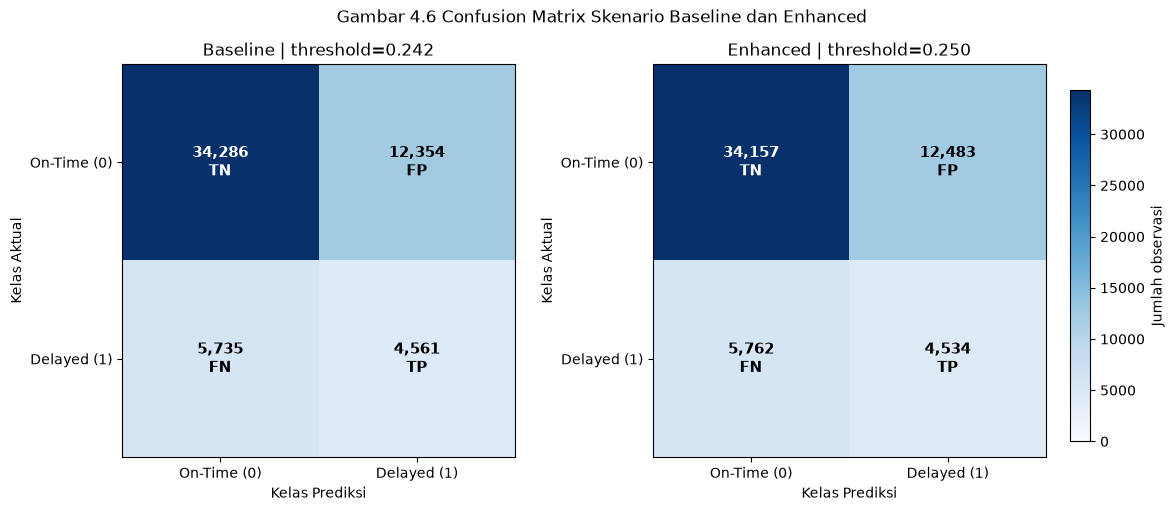

Baseline: TP=4,561 (terdeteksi); FN=5,735 (terlewat); FP=12,354 (false alarm); TN=34,286 (tepat On-Time)
Enhanced: TP=4,534 (terdeteksi); FN=5,762 (terlewat); FP=12,483 (false alarm); TN=34,157 (tepat On-Time)
Selisih Enhanced − Baseline: ΔTP=-27, ΔFN=+27, ΔFP=+129, ΔTN=-129


In [120]:
TITLE_CM_441 = "Gambar 4.6 Confusion Matrix Skenario Baseline dan Enhanced"
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
all_matrices_441 = [RESULTS_441[s]["cm"] for s in ("baseline", "enhanced")]
scale_max_441 = max(int(cm.max()) for cm in all_matrices_441)
cell_labels_441 = np.array([["TN", "FP"], ["FN", "TP"]])
for ax, scenario in zip(axes, ("baseline", "enhanced")):
    cm = RESULTS_441[scenario]["cm"]
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=scale_max_441)
    ax.set_title(f"{scenario.title()} | threshold={THRESHOLDS_441[scenario]:.3f}")
    ax.set_xticks([0, 1], labels=["On-Time (0)", "Delayed (1)"])
    ax.set_yticks([0, 1], labels=["On-Time (0)", "Delayed (1)"])
    ax.set_xlabel("Kelas Prediksi")
    ax.set_ylabel("Kelas Aktual")
    for row in range(2):
        for col in range(2):
            value = int(cm[row, col])
            ax.text(col, row, f"{value:,}\n{cell_labels_441[row, col]}",
                    ha="center", va="center", fontsize=11,
                    color="white" if value > scale_max_441 * 0.5 else "black",
                    fontweight="bold")
fig.suptitle(TITLE_CM_441, fontsize=12, y=0.98)
fig.subplots_adjust(left=0.10, right=0.87, top=0.88, bottom=0.15, wspace=0.35)
cbar_ax = fig.add_axes([0.89, 0.18, 0.017, 0.65])
fig.colorbar(im, cax=cbar_ax, label="Jumlah observasi")
FILE_CM_441 = FIGURE_DIR_441 / "Gambar_4_6_Confusion_Matrix_Baseline_Enhanced.png"
fig.savefig(FILE_CM_441, dpi=300, bbox_inches="tight")
print(TITLE_CM_441)
plt.show()

for scenario in ("baseline", "enhanced"):
    r = RESULTS_441[scenario]
    print(f"{scenario.title()}: TP={r['tp']:,} (terdeteksi); "
          f"FN={r['fn']:,} (terlewat); FP={r['fp']:,} (false alarm); "
          f"TN={r['tn']:,} (tepat On-Time)")
b, e = RESULTS_441["baseline"], RESULTS_441["enhanced"]
print(f"Selisih Enhanced − Baseline: ΔTP={e['tp']-b['tp']:+,}, "
      f"ΔFN={e['fn']-b['fn']:+,}, ΔFP={e['fp']-b['fp']:+,}, "
      f"ΔTN={e['tn']-b['tn']:+,}")

### Gambar 4.7 — Perbandingan Kurva ROC (opsional)
Gunakan probabilitas predict_proba untuk menghitung kurva dan ROC-AUC. Gambar hanya dibuat apabila MAKE_ROC_441 = True.

Gambar 4.7 Perbandingan Kurva ROC Skenario Baseline dan Enhanced


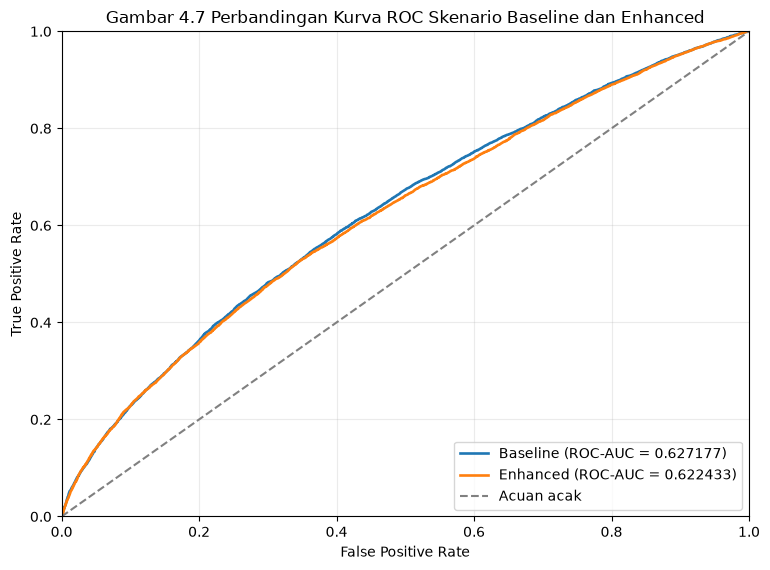

In [121]:
FILE_ROC_441 = None
if MAKE_ROC_441:
    TITLE_ROC_441 = "Gambar 4.7 Perbandingan Kurva ROC Skenario Baseline dan Enhanced"
    fig, ax = plt.subplots(figsize=(7.8, 5.8))
    for scenario in ("baseline", "enhanced"):
        fpr, tpr, _ = roc_curve(y_test, RESULTS_441[scenario]["probabilities"], pos_label=1)
        auc_value = RESULTS_441[scenario]["metrics"]["ROC-AUC"]
        ax.plot(fpr, tpr, linewidth=1.9,
                label=f"{scenario.title()} (ROC-AUC = {auc_value:.6f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acuan acak")
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
           xlim=(0, 1), ylim=(0, 1))
    ax.set_title(TITLE_ROC_441)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")
    fig.tight_layout()
    FILE_ROC_441 = FIGURE_DIR_441 / "Gambar_4_7_Kurva_ROC_Baseline_Enhanced.png"
    fig.savefig(FILE_ROC_441, dpi=300, bbox_inches="tight")
    print(TITLE_ROC_441)
    plt.show()
else:
    print("Gambar 4.7 tidak dibuat karena MAKE_ROC_441=False (opsional).")

### Gambar 4.8 — Perbandingan Kurva Precision–Recall
Grafik ini wajib karena AP adalah metrik utama. Garis horizontal menunjukkan prevalensi kelas Delayed pada testing. Nilai AP yang ditampilkan berasal dari average_precision_score; bukan luas trapesium grafik. Titik menunjukkan Precision–Recall pada threshold validasi yang telah dibekukan.

Gambar 4.8 Perbandingan Kurva Precision–Recall Skenario Baseline dan Enhanced


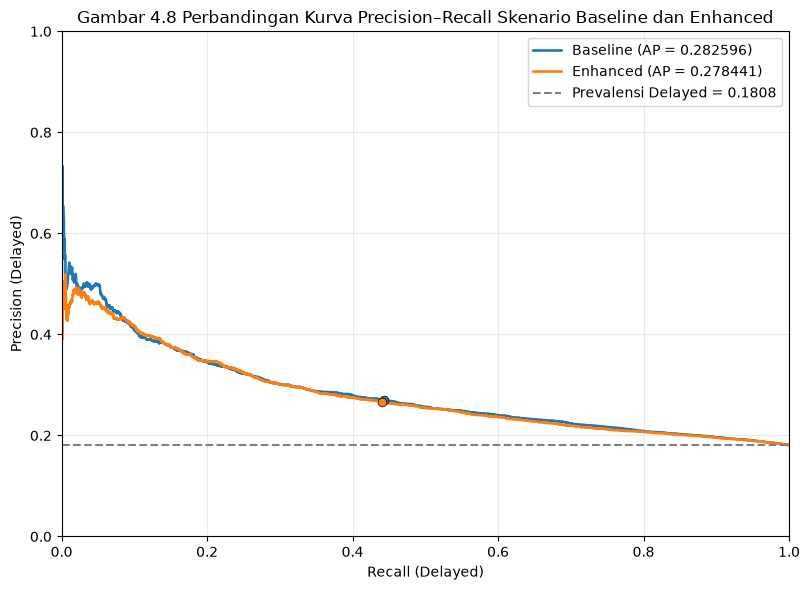

Titik kurva adalah Precision dan Recall pada threshold terkunci masing-masing model.
AP berbeda dari integrasi kurva Precision–Recall dengan aturan trapesium.


In [122]:
TITLE_PR_441 = "Gambar 4.8 Perbandingan Kurva Precision–Recall Skenario Baseline dan Enhanced"
fig, ax = plt.subplots(figsize=(8.2, 6.0))
for scenario in ("baseline", "enhanced"):
    r = RESULTS_441[scenario]
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, r["probabilities"], pos_label=1)
    ap = r["metrics"]["Average Precision (AP)"]
    line, = ax.plot(recall_curve, precision_curve, linewidth=1.9,
                    label=f"{scenario.title()} (AP = {ap:.6f})")
    ax.scatter(r["metrics"]["Recall (Delayed)"],
               r["metrics"]["Precision (Delayed)"],
               s=40, color=line.get_color(), edgecolors="black", linewidths=0.5,
               zorder=5)
ax.axhline(float(y_test.mean()), linestyle="--", color="gray",
           label=f"Prevalensi Delayed = {float(y_test.mean()):.4f}")
ax.set(xlabel="Recall (Delayed)", ylabel="Precision (Delayed)",
       xlim=(0, 1), ylim=(0, 1))
ax.set_title(TITLE_PR_441)
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
fig.tight_layout()
FILE_PR_441 = FIGURE_DIR_441 / "Gambar_4_8_Kurva_Precision_Recall_Baseline_Enhanced.png"
fig.savefig(FILE_PR_441, dpi=300, bbox_inches="tight")
print(TITLE_PR_441)
plt.show()
print("Titik kurva adalah Precision dan Recall pada threshold terkunci masing-masing model.")
print("AP berbeda dari integrasi kurva Precision–Recall dengan aturan trapesium.")

### Pemeriksaan ketidakpastian selisih AP melalui paired bootstrap blok tanggal
Resampling dilakukan terhadap hari kalender, bukan baris individual, untuk mempertahankan kelompok penerbangan dalam satu hari. Per hari, seluruh penerbangan diambil bersama; dua model menggunakan indeks resampling yang sama. BOOTSTRAP_REPS_441 secara default 1.000 dengan seed 42. Ini merupakan estimasi ketidakpastian deskriptif pada periode testing, bukan dasar pemilihan model. Jika tanggal pengamatan tidak lagi tersedia, aktifkan hanya setelah menjalankan sel sebelumnya yang menghasilkan tanggal asli.

In [124]:
BOOTSTRAP_CI_441 = None
BOOTSTRAP_DELTAS_441 = None
FILE_BOOTSTRAP_441 = None

if RUN_BLOCK_BOOTSTRAP_441:
    # Tanggal testing harus berasal dari fitur/metadata lama, tidak dari data rekaan.
    if "df_prepared" in globals() and "fl_date" in df_prepared.columns:
        test_dates_441 = pd.to_datetime(
            df_prepared.loc[y_test.index, "fl_date"], errors="raise"
        )
    elif "df_test" in globals() and "fl_date" in df_test.columns and df_test.index.equals(y_test.index):
        test_dates_441 = pd.to_datetime(df_test["fl_date"], errors="raise")
    else:
        raise RuntimeError(
            "Tanggal testing tidak tersedia untuk paired day-block bootstrap. "
            "Jalankan kembali sel 4.2.1 yang menghasilkan df_prepared/fl_date, "
            "atau set RUN_BLOCK_BOOTSTRAP_441=False untuk melewati audit opsional."
        )
    assert len(test_dates_441) == EXPECTED_TEST_SIZE_441
    assert test_dates_441.between("2024-11-01", "2024-12-31").all()

    day_ids, day_inverse = np.unique(
        test_dates_441.to_numpy(dtype="datetime64[D]"), return_inverse=True
    )
    blocks = [np.flatnonzero(day_inverse == i) for i in range(len(day_ids))]
    assert len(day_ids) >= 2 and sum(len(b) for b in blocks) == len(y_test)
    y_array = y_test.to_numpy(dtype=np.uint8)
    pb = RESULTS_441["baseline"]["probabilities"]
    pe = RESULTS_441["enhanced"]["probabilities"]
    rng = np.random.default_rng(SEED_441)
    deltas = np.empty(BOOTSTRAP_REPS_441, dtype=float)
    for iteration in range(BOOTSTRAP_REPS_441):
        chosen_day_ids = rng.integers(0, len(day_ids), size=len(day_ids))
        idx = np.concatenate([blocks[i] for i in chosen_day_ids])
        y_rep = y_array[idx]
        assert (y_rep == 0).any() and (y_rep == 1).any(), (
            "Sampel bootstrap hanya satu kelas; audit periode tanggal."
        )
        deltas[iteration] = (
            average_precision_score(y_rep, pe[idx])
            - average_precision_score(y_rep, pb[idx])
        )
    bounds = np.percentile(deltas, [2.5, 97.5])
    BOOTSTRAP_DELTAS_441 = deltas
    BOOTSTRAP_CI_441 = (float(bounds[0]), float(bounds[1]))
    FILE_BOOTSTRAP_441 = AUDIT_DIR_441 / "Bootstrap_Paired_Block_Dates_Delta_AP_1000.csv"
    pd.DataFrame({"replikasi": np.arange(1, len(deltas)+1),
                  "delta_ap_enhanced_minus_baseline": deltas,
                  "delta_ap_pp": deltas*100}).to_csv(
        FILE_BOOTSTRAP_441, index=False, encoding="utf-8-sig"
    )
    point_delta = RESULTS_441["enhanced"]["metrics"]["Average Precision (AP)"] - (
        RESULTS_441["baseline"]["metrics"]["Average Precision (AP)"]
    )
    print(f"Paired bootstrap tanggal: {len(day_ids)} hari; {BOOTSTRAP_REPS_441} replikasi.")
    print(f"Selisih AP observasi: {point_delta:+.6f} ({point_delta*100:+.4f} pp)")
    print(f"Interval ketidakpastian 95%: [{bounds[0]*100:+.4f}, {bounds[1]*100:+.4f}] pp")
    if bounds[0] <= 0 <= bounds[1]:
        print("Interval mencakup nol; bukti peningkatan AP Enhanced belum kuat dalam estimasi ini.")
    elif bounds[0] > 0:
        print("Interval positif; mendukung peningkatan AP pada testing dalam estimasi ini.")
    else:
        print("Interval negatif; mendukung penurunan AP Enhanced dalam estimasi ini.")
else:
    print("Paired bootstrap blok tanggal dilewati sesuai konfigurasi (opsional).")

Paired bootstrap tanggal: 61 hari; 1000 replikasi.
Selisih AP observasi: -0.004154 (-0.4154 pp)
Interval ketidakpastian 95%: [-0.7881, -0.0914] pp
Interval negatif; mendukung penurunan AP Enhanced dalam estimasi ini.


### Ekspor prediksi testing dan metadata evaluasi
Prediksi kedua model disimpan bersama indeks observasi (dan tanggal jika tersedia), label aktual, probabilitas, serta prediksi final. Berkas ini untuk audit, tidak dipakai untuk menyesuaikan fitur, parameter, atau threshold setelah melihat testing. Metadata memuat checksum model, data, metrik, dan file hasil.

In [125]:
FILE_PREDICTIONS_441 = AUDIT_DIR_441 / "Prediksi_Testing_Baseline_Enhanced_4_4_1.csv"
export_predictions_441 = pd.DataFrame({
    "observation_index": y_test.index.to_numpy(),
    "y_true": y_test.to_numpy(dtype=np.uint8),
    "baseline_proba_delayed": RESULTS_441["baseline"]["probabilities"],
    "baseline_pred_locked_threshold": RESULTS_441["baseline"]["predictions"],
    "enhanced_proba_delayed": RESULTS_441["enhanced"]["probabilities"],
    "enhanced_pred_locked_threshold": RESULTS_441["enhanced"]["predictions"],
})
if "test_dates_441" in globals():
    export_predictions_441.insert(1, "fl_date", test_dates_441.dt.strftime("%Y-%m-%d").to_numpy())
export_predictions_441.to_csv(FILE_PREDICTIONS_441, index=False, encoding="utf-8-sig")

# Hasil evaluasi disimpan dengan nama subbab baru, tanpa menimpa artefak 4.3.1/4.3.2.
selected_scenario_441 = metadata_432_for_441["selected_deployment_scenario"]
model_enhanced_for_shap_441 = MODELS_441["enhanced"]
model_selected_for_next_phase_441 = MODELS_441[selected_scenario_441]
threshold_selected_for_next_phase_441 = THRESHOLDS_441[selected_scenario_441]

evaluation_metadata_441 = {
    "subchapter": "4.4.1",
    "testing_period": "2024-11-01 s.d. 2024-12-31",
    "n_test": int(len(y_test)),
    "n_on_time": int((y_test == 0).sum()),
    "n_delayed": int((y_test == 1).sum()),
    "positive_class": 1,
    "comparison": "enhanced_minus_baseline",
    "metric_units": "0-1",
    "benchmark_accuracy_contextual": BENCHMARK_ACCURACY_441,
    "majority_accuracy": MAJORITY_ACCURACY_441,
    "seed": SEED_441,
    "versions": VERSIONS_441,
    "model_sha256_frozen": MODEL_HASHES_BEFORE_441,
    "test_data_sha256_before": TEST_DATA_HASHES_BEFORE_441,
    "selected_deployment_scenario_from_validation": selected_scenario_441,
    "models": {
        s: {
            "threshold_from_validation": THRESHOLDS_441[s],
            "feature_names": BUNDLES_441[s]["feature_names"],
            "validation_ap": float(BUNDLES_441[s]["validation_ap"]),
            "test_metrics": RESULTS_441[s]["metrics"],
            "confusion_matrix_TN_FP_FN_TP": {
                k: RESULTS_441[s][k] for k in ("tn", "fp", "fn", "tp")
            },
        }
        for s in ("baseline", "enhanced")
    },
    "delta_ap_enhanced_minus_baseline": float(
        RESULTS_441["enhanced"]["metrics"]["Average Precision (AP)"] -
        RESULTS_441["baseline"]["metrics"]["Average Precision (AP)"]
    ),
    "bootstrap": {
        "enabled": RUN_BLOCK_BOOTSTRAP_441,
        "n_replications": BOOTSTRAP_REPS_441 if RUN_BLOCK_BOOTSTRAP_441 else 0,
        "confidence_interval_delta_ap": list(BOOTSTRAP_CI_441) if BOOTSTRAP_CI_441 else None,
    },
    "paths": {
        "tabel_html": str(FILE_TABLE_HTML_441),
        "tabel_csv": str(FILE_TABLE_CSV_441),
        "confusion_matrix_png": str(FILE_CM_441),
        "roc_png": str(FILE_ROC_441) if FILE_ROC_441 is not None else None,
        "precision_recall_png": str(FILE_PR_441),
        "predictions_csv": str(FILE_PREDICTIONS_441),
        "bootstrap_csv": str(FILE_BOOTSTRAP_441) if FILE_BOOTSTRAP_441 is not None else None,
    },
    "retraining_performed": False,
    "hyperparameter_tuning_on_testing": False,
    "threshold_tuning_on_testing": False,
    "test_based_model_selection": False,
}
FILE_SUMMARY_441 = AUDIT_DIR_441 / "Ringkasan_Evaluasi_4_4_1.json"
FILE_SUMMARY_441.write_text(
    json.dumps(evaluation_metadata_441, indent=2, ensure_ascii=False),
    encoding="utf-8"
)
print("Prediksi per observasi tersimpan:", FILE_PREDICTIONS_441.resolve())
print("Ringkasan JSON tersimpan:", FILE_SUMMARY_441.resolve())

Prediksi per observasi tersimpan: C:\Users\Lenovo\Documents\Skripsi\output_4_4_1\Audit\Prediksi_Testing_Baseline_Enhanced_4_4_1.csv
Ringkasan JSON tersimpan: C:\Users\Lenovo\Documents\Skripsi\output_4_4_1\Audit\Ringkasan_Evaluasi_4_4_1.json


### Audit akhir dan ringkasan interpretasi hasil
Verifikasi bahwa model, parameter, dan data testing tetap identik setelah proses prediksi, tabel, grafik, dan bootstrap. Interpretasi otomatis di bawah menggunakan angka aktual setelah evaluasi dijalankan; tidak menetapkan model baru berdasarkan hasil testing. Objek model Enhanced dan model pilihan validasi tetap tersedia untuk SHAP pada Subbab 4.4.2 berikutnya, tanpa menjalankan SHAP di sini.

In [126]:
for scenario in ("baseline", "enhanced"):
    assert booster_sha256_441(MODELS_441[scenario]) == MODEL_HASHES_BEFORE_441[scenario]
    assert dict(MODELS_441[scenario].get_params()) == MODEL_PARAMS_BEFORE_441[scenario]
    assert float(THRESHOLDS_441[scenario]) == float(BUNDLES_441[scenario]["threshold"])
for name, original_hash in TEST_DATA_HASHES_BEFORE_441.items():
    assert dataframe_sha256_441(globals()[name]) == original_hash, f"Data testing berubah: {name}"
for scenario, r in RESULTS_441.items():
    assert r["cm"].sum() == EXPECTED_TEST_SIZE_441
    assert r["tp"] + r["fn"] == EXPECTED_DELAYED_441
    assert r["tn"] + r["fp"] == 46_640
    assert np.isfinite(r["probabilities"]).all()
    assert np.all((r["probabilities"] >= 0) & (r["probabilities"] <= 1))
    assert np.array_equal(
        r["predictions"], (r["probabilities"] >= THRESHOLDS_441[scenario]).astype(np.uint8)
    )
assert metadata_432_for_441["selected_deployment_scenario"] == selected_scenario_441
assert all(p.is_file() for p in (FILE_TABLE_CSV_441, FILE_TABLE_HTML_441, FILE_CM_441,
                                 FILE_PR_441, FILE_SUMMARY_441, FILE_PREDICTIONS_441))
if MAKE_ROC_441:
    assert FILE_ROC_441 is not None and FILE_ROC_441.is_file()
if RUN_BLOCK_BOOTSTRAP_441:
    assert FILE_BOOTSTRAP_441 is not None and FILE_BOOTSTRAP_441.is_file()

b, e = RESULTS_441["baseline"], RESULTS_441["enhanced"]
delta_ap_pp = 100*(e["metrics"]["Average Precision (AP)"] - b["metrics"]["Average Precision (AP)"])
print("AUDIT FINAL 4.4.1: LULUS")
print("- Model dan hiperparameter tidak berubah; tidak ada fit()/Optuna.")
print("- Threshold masing-masing tetap berasal dari 4.3.2.")
print("- 56.936 observasi testing dievaluasi pada dua skenario yang identik.")
print("- Seluruh tabel/gambar dan artefak audit telah tersimpan.")
print("\nRINGKASAN INTERPRETASI OTOMATIS")
print(f"AP testing: Baseline={b['metrics']['Average Precision (AP)']:.6f}; "
      f"Enhanced={e['metrics']['Average Precision (AP)']:.6f}; "
      f"Δ Enhanced−Baseline={delta_ap_pp:+.4f} pp")
print(f"Precision Delayed: Baseline={b['metrics']['Precision (Delayed)']:.6f}; "
      f"Enhanced={e['metrics']['Precision (Delayed)']:.6f}")
print(f"Recall Delayed: Baseline={b['metrics']['Recall (Delayed)']:.6f}; "
      f"Enhanced={e['metrics']['Recall (Delayed)']:.6f}")
print(f"F1 Delayed: Baseline={b['metrics']['F1-Score (Delayed)']:.6f}; "
      f"Enhanced={e['metrics']['F1-Score (Delayed)']:.6f}")
print(f"ROC-AUC: Baseline={b['metrics']['ROC-AUC']:.6f}; "
      f"Enhanced={e['metrics']['ROC-AUC']:.6f}")
if delta_ap_pp > 0:
    print("Enhanced menunjukkan AP lebih tinggi pada hold-out; cek interval ketidakpastian.")
elif delta_ap_pp < 0:
    print("Enhanced menunjukkan AP lebih rendah pada hold-out; jangan menyembunyikan penurunan.")
else:
    print("AP kedua skenario sama pada presisi pengukuran ini.")
print(f"Model yang tetap dipilih berdasarkan validasi 4.3.2: {selected_scenario_441.title()}")
print("Objek Enhanced dan model pilihan validasi tersedia untuk analisis SHAP berikutnya.")

AUDIT FINAL 4.4.1: LULUS
- Model dan hiperparameter tidak berubah; tidak ada fit()/Optuna.
- Threshold masing-masing tetap berasal dari 4.3.2.
- 56.936 observasi testing dievaluasi pada dua skenario yang identik.
- Seluruh tabel/gambar dan artefak audit telah tersimpan.

RINGKASAN INTERPRETASI OTOMATIS
AP testing: Baseline=0.282596; Enhanced=0.278441; Δ Enhanced−Baseline=-0.4154 pp
Precision Delayed: Baseline=0.269642; Enhanced=0.266439
Recall Delayed: Baseline=0.442988; Enhanced=0.440365
F1 Delayed: Baseline=0.335232; Enhanced=0.332003
ROC-AUC: Baseline=0.627177; Enhanced=0.622433
Enhanced menunjukkan AP lebih rendah pada hold-out; jangan menyembunyikan penurunan.
Model yang tetap dipilih berdasarkan validasi 4.3.2: Baseline
Objek Enhanced dan model pilihan validasi tersedia untuk analisis SHAP berikutnya.


## 4.4.2 Analisis Kontribusi Fitur Menggunakan SHAP

In [127]:
import json
import sys
import hashlib
import warnings
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
import joblib
from scipy.special import expit
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score
from IPython.display import display

SEED_442 = 42
SAMPLE_SIZE_442 = 3_000
EXPECTED_TEST_442 = 56_936
EXPECTED_FEATURES_442 = [
    "month", "day_of_week", "scheduled_dep_hour", "op_unique_carrier",
    "dest", "distance", "crs_elapsed_time",
    "hist_delay_rate_carrier", "hist_delay_rate_dest", "hist_delay_rate_carrier_dest"
]
BASIC_442 = EXPECTED_FEATURES_442[:7]
HISTORY_442 = EXPECTED_FEATURES_442[7:]
CAT_442 = ["op_unique_carrier", "dest"]
EXPECTED_THRESHOLD_442 = 0.2500  # Konfirmasi terhadap bundel resmi di bawah.

OUTPUT_DIR_442 = Path("output_4_4_2")
FIGURE_DIR_442 = OUTPUT_DIR_442 / "Gambar"
AUDIT_DIR_442 = OUTPUT_DIR_442 / "Audit"
for d in (OUTPUT_DIR_442, FIGURE_DIR_442, AUDIT_DIR_442):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"font.size": 10, "savefig.dpi": 300})

VERSIONS_442 = {
    "python": sys.version.split()[0], "pandas": pd.__version__,
    "numpy": np.__version__, "lightgbm": lgb.__version__,
    "shap": shap.__version__, "scipy": version("scipy"),
}
print("Subbab 4.4.2 — SHAP Enhanced V1 (tanpa training dan Optuna)")
print("Versi pustaka:", VERSIONS_442)
print("Folder keluaran:", OUTPUT_DIR_442.resolve())

Subbab 4.4.2 — SHAP Enhanced V1 (tanpa training dan Optuna)
Versi pustaka: {'python': '3.14.6', 'pandas': '3.0.3', 'numpy': '2.4.6', 'lightgbm': '4.7.0', 'shap': '0.54.1', 'scipy': '1.18.0'}
Folder keluaran: C:\Users\Lenovo\Documents\Skripsi\output_4_4_2


### Audit matriks testing dan identitas model V1 yang terkunci
Sel ini memeriksa bentuk data, kategori, indeks, hash booster, serta metadata bundel 4.3.2. Perhitungan SHAP tidak akan dimulai bila model atau matriks berbeda dari evaluasi 4.4.1.

In [128]:
def sha256_file_442(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def booster_sha256_442(model):
    if not isinstance(model, lgb.LGBMClassifier) or not hasattr(model, "booster_"):
        raise RuntimeError("Objek model bukan LightGBMClassifier V1 yang sudah dilatih.")
    return hashlib.sha256(model.booster_.model_to_string().encode("utf-8")).hexdigest()


def frame_sha256_442(frame):
    return hashlib.sha256(
        pd.util.hash_pandas_object(frame, index=True).to_numpy(dtype="uint64").tobytes()
    ).hexdigest()

missing_442 = [k for k in ("X_test_enhanced", "y_test") if k not in globals()]
if missing_442:
    raise RuntimeError(
        "Matriks testing belum ada: " + ", ".join(missing_442) +
        ". Jalankan sel persiapan data 4.1–4.2.2 dahulu; jangan latih ulang model."
    )

assert isinstance(X_test_enhanced, pd.DataFrame)
assert isinstance(y_test, pd.Series)
assert X_test_enhanced.shape == (EXPECTED_TEST_442, 10)
assert y_test.shape[0] == EXPECTED_TEST_442
assert X_test_enhanced.index.equals(y_test.index)
assert X_test_enhanced.index.is_unique
assert X_test_enhanced.columns.tolist() == EXPECTED_FEATURES_442
assert y_test.isin([0, 1]).all() and y_test.notna().all()
assert int(y_test.sum()) == 10_296
for col in CAT_442:
    assert isinstance(X_test_enhanced[col].dtype, pd.CategoricalDtype), col
    assert not X_test_enhanced[col].cat.ordered
for col in set(EXPECTED_FEATURES_442) - set(CAT_442):
    assert pd.api.types.is_numeric_dtype(X_test_enhanced[col]), col
    assert np.isfinite(X_test_enhanced[col].dropna().to_numpy()).all(), col
for col in HISTORY_442:
    assert X_test_enhanced[col].dropna().between(0, 1).all(), col
assert int(X_test_enhanced["dest"].isna().sum()) == 41

BUNDLE_PATH_442 = Path("output_4_3_2") / "Model dan Konfigurasi" / "Model_4_3_2_Enhanced_Threshold_Terkunci.joblib"
META_PATH_442 = Path("output_4_3_2") / "Metadata_Validasi_dan_Threshold_4_3_2.json"
if not BUNDLE_PATH_442.is_file() or not META_PATH_442.is_file():
    raise RuntimeError(
        "Bundel Enhanced V1 atau metadata 4.3.2 tidak ditemukan. "
        f"Butuh:\n{BUNDLE_PATH_442}\n{META_PATH_442}\n"
        "Pindahkan file keluaran resmi 4.3.2 ke direktori proyek notebook; "
        "jangan membuat model pengganti."
    )

META_432_442 = json.loads(META_PATH_442.read_text(encoding="utf-8"))
assert META_432_442["enhanced"]["threshold"] == EXPECTED_THRESHOLD_442, (
    "Threshold tidak sesuai hasil V1 yang telah dilaporkan; periksa metadata."
)
assert META_432_442["selected_deployment_scenario"] == "baseline", (
    "Skenario Streamlit berbeda dari keputusan validasi V1."
)
assert sha256_file_442(BUNDLE_PATH_442) == META_432_442["model_files_sha256"]["enhanced"], (
    "Hash file model berbeda dengan metadata resmi 4.3.2."
)
BUNDLE_442 = joblib.load(BUNDLE_PATH_442)
MODEL_442 = BUNDLE_442["model"]
THRESHOLD_442 = float(BUNDLE_442["threshold"])
assert BUNDLE_442["scenario"] == "enhanced"
assert BUNDLE_442["source_subchapter"] == "4.3.1"
assert BUNDLE_442["validation_subchapter"] == "4.3.2"
assert BUNDLE_442["feature_names"] == EXPECTED_FEATURES_442
assert MODEL_442.feature_name_ == EXPECTED_FEATURES_442
assert MODEL_442.n_features_in_ == 10
assert np.array_equal(MODEL_442.classes_, [0, 1])
assert BUNDLE_442["categorical_features"] == CAT_442
assert np.isclose(THRESHOLD_442, EXPECTED_THRESHOLD_442, rtol=0, atol=1e-12)
MODEL_HASH_BEFORE_442 = booster_sha256_442(MODEL_442)
assert MODEL_HASH_BEFORE_442 == BUNDLE_442["model_sha256"]
assert MODEL_HASH_BEFORE_442 == META_432_442["model_hashes"]["enhanced"]
PARAMS_BEFORE_442 = dict(MODEL_442.get_params())
X_HASH_BEFORE_442 = frame_sha256_442(X_test_enhanced)
Y_HASH_BEFORE_442 = frame_sha256_442(y_test)
for col in CAT_442:
    assert list(X_test_enhanced[col].cat.categories) == list(
        BUNDLE_442["category_vocab_from_training"][col]
    ), col

# Kecocokan dengan objek dan hasil 4.4.1 jika tersedia di kernel.
if "MODELS_441" in globals():
    assert booster_sha256_442(MODELS_441["enhanced"]) == MODEL_HASH_BEFORE_442
if "THRESHOLDS_441" in globals():
    assert np.isclose(THRESHOLDS_441["enhanced"], THRESHOLD_442, atol=1e-12)
if "MODEL_HASHES_BEFORE_441" in globals():
    assert MODEL_HASHES_BEFORE_441["enhanced"] == MODEL_HASH_BEFORE_442
if "df_prepared" not in globals():
    raise RuntimeError(
        "df_prepared tidak tersedia. Jalankan sel 4.2.1 yang membentuk data bersih "
        "untuk metadata tanggal dan pemilihan kasus SHAP lokal."
    )
assert X_test_enhanced.index.isin(df_prepared.index).all()
assert pd.to_datetime(df_prepared.loc[X_test_enhanced.index, "fl_date"]).between(
    "2024-11-01", "2024-12-31"
).all()

print("Audit model Enhanced V1, matriks testing, kategori dan threshold: LULUS")
print("Hash model:", MODEL_HASH_BEFORE_442)
print("Threshold V1:", f"{THRESHOLD_442:.4f}")
print("Ukuran matriks:", X_test_enhanced.shape)

Audit model Enhanced V1, matriks testing, kategori dan threshold: LULUS
Hash model: c97b6c525cc704ad1f4224de4adc7c60c5d16cd842162cfcbca370de79ff0684
Threshold V1: 0.2500
Ukuran matriks: (56936, 10)


### Sampel global 3.000 observasi yang representatif dan dapat direproduksi
Sampel dipilih sebelum melihat SHAP, secara acak terstratifikasi berdasarkan kelas aktual. Label digunakan hanya untuk pengambilan sampel penjelasan pascaevaluasi, tidak untuk mengubah model.

In [129]:
assert SAMPLE_SIZE_442 <= len(y_test)
y_all_442 = y_test.to_numpy(dtype=int)
rows_pos_442 = np.flatnonzero(y_all_442 == 1)
rows_neg_442 = np.flatnonzero(y_all_442 == 0)
n_pos_sample_442 = int(round(SAMPLE_SIZE_442 * len(rows_pos_442) / len(y_all_442)))
n_neg_sample_442 = SAMPLE_SIZE_442 - n_pos_sample_442
rng_sample_442 = np.random.default_rng(SEED_442)
selected_positions_442 = np.sort(np.concatenate([
    rng_sample_442.choice(rows_pos_442, n_pos_sample_442, replace=False),
    rng_sample_442.choice(rows_neg_442, n_neg_sample_442, replace=False)
]))
assert len(selected_positions_442) == SAMPLE_SIZE_442
assert np.unique(selected_positions_442).size == SAMPLE_SIZE_442
X_SHAP_442 = X_test_enhanced.iloc[selected_positions_442].copy()
y_SHAP_442 = y_test.iloc[selected_positions_442].copy()
assert X_SHAP_442.index.equals(y_SHAP_442.index)

SAMPLE_FILE_442 = AUDIT_DIR_442 / "Indeks_Sampel_SHAP_Global_V1.csv"
pd.DataFrame({
    "posisi_testing": selected_positions_442,
    "indeks_observasi": X_SHAP_442.index,
    "fl_date": pd.to_datetime(df_prepared.loc[X_SHAP_442.index, "fl_date"]).dt.strftime("%Y-%m-%d").to_numpy(),
    "label_aktual": y_SHAP_442.to_numpy(),
}).to_csv(SAMPLE_FILE_442, index=False)

print("Sampel SHAP global:", len(X_SHAP_442), "observasi")
print(f"Prevalensi Delayed testing: {float(y_test.mean()):.4%}")
print(f"Prevalensi Delayed sampel : {float(y_SHAP_442.mean()):.4%}")
print("Indeks sampel tersimpan:", SAMPLE_FILE_442)

Sampel SHAP global: 3000 observasi
Prevalensi Delayed testing: 18.0835%
Prevalensi Delayed sampel : 18.1000%
Indeks sampel tersimpan: output_4_4_2\Audit\Indeks_Sampel_SHAP_Global_V1.csv


### SHAP TreeExplainer, normalisasi kelas Delayed, dan audit aditivitas
Penanganan kompatibilitas output SHAP: matriks satu kelas, daftar dua kelas, atau array tiga dimensi. Kandidat keluaran diperiksa terhadap skor mentah kelas positif. Jika tidak ada pasangan SHAP/base value yang cocok, proses dihentikan.

In [130]:
def select_positive_shap_raw_442(values, expected_value, raw_scores, n_features):
    """Menetapkan SHAP kelas 1 melalui verifikasi aditivitas, bukan asumsi indeks."""
    raw = np.asarray(raw_scores, dtype=float).reshape(-1)
    n = len(raw)
    ev = np.asarray(expected_value, dtype=float).reshape(-1)
    if ev.size not in (1, 2):
        raise ValueError(f"Bentuk expected_value belum didukung: {ev.shape}")

    candidates = []
    def register(arr, label, preferred_base=None):
        arr = np.asarray(arr, dtype=float)
        if arr.shape != (n, n_features):
            raise ValueError(f"Bentuk SHAP {label}: {arr.shape}, seharusnya {(n, n_features)}")
        choices = [preferred_base] if preferred_base is not None else list(range(ev.size))
        for bi in choices:
            base = float(ev[bi])
            residual = float(np.max(np.abs(base + arr.sum(axis=1) - raw)))
            candidates.append((residual, label, bi, arr, base))

    if isinstance(values, list):
        if len(values) not in (1, 2):
            raise ValueError(f"Panjang daftar SHAP tidak dikenali: {len(values)}")
        for k, arr in enumerate(values):
            register(arr, f"list_class_{k}", k if ev.size == len(values) else None)
    else:
        vals = np.asarray(values, dtype=float)
        if vals.ndim == 2 and vals.shape == (n, n_features):
            register(vals, "matrix")
        elif vals.ndim == 3 and vals.shape[:2] == (n, n_features) and vals.shape[2] in (1,2):
            for k in range(vals.shape[2]):
                register(vals[:, :, k], f"last_axis_class_{k}", k if ev.size == vals.shape[2] else None)
        elif vals.ndim == 3 and vals.shape[1:] == (n, n_features) and vals.shape[0] in (1,2):
            for k in range(vals.shape[0]):
                register(vals[k], f"first_axis_class_{k}", k if ev.size == vals.shape[0] else None)
        else:
            raise ValueError(f"Bentuk keluaran SHAP tidak dikenal: {vals.shape}")

    candidates.sort(key=lambda x: x[0])
    best = candidates[0]
    if not np.isfinite(best[0]) or best[0] > 1e-5:
        diagnostic = [(label, float(error)) for error, label, *_ in candidates]
        raise RuntimeError(
            "Tidak ada SHAP yang aditif terhadap raw score Delayed; audit skala/kelas. "
            f"Kandidat: {diagnostic}"
        )
    tied = [c for c in candidates[1:] if c[0] <= 1e-5 and
            (c[1], c[2]) != (best[1], best[2])]
    if tied:
        raise RuntimeError("Ambiguitas keluaran SHAP: lebih dari satu pasangan kelas/base aditif.")
    return best[3], best[4], {"detected_format": best[1], "expected_value_index": int(best[2]),
                              "maximum_additivity_error": float(best[0])}

EXPLAINER_442 = shap.TreeExplainer(
    MODEL_442.booster_, model_output="raw", feature_perturbation="tree_path_dependent"
)
# LightGBM/SHAP berbeda versi dapat menghasilkan satu matriks atau dua matriks.
with warnings.catch_warnings(record=True) as shap_warnings_442:
    warnings.simplefilter("always")
    shap_raw_442 = EXPLAINER_442.shap_values(X_SHAP_442, check_additivity=False)
for w in shap_warnings_442:
    print("Peringatan SHAP:", str(w.message))

raw_model_442 = np.asarray(
    MODEL_442.booster_.predict(X_SHAP_442, raw_score=True), dtype=float
).reshape(-1)
proba_model_442 = np.asarray(MODEL_442.predict_proba(X_SHAP_442)[:, 1], dtype=float)
assert np.isfinite(raw_model_442).all()
assert np.isfinite(proba_model_442).all()
assert np.allclose(expit(raw_model_442), proba_model_442, atol=1e-7, rtol=1e-7), (
    "Konversi sigmoid(raw score) tidak cocok dengan predict_proba; hentikan interpretasi."
)
SHAP_VALUES_442, BASE_VALUE_442, SHAP_FORMAT_442 = select_positive_shap_raw_442(
    shap_raw_442, EXPLAINER_442.expected_value, raw_model_442, len(EXPECTED_FEATURES_442)
)
assert SHAP_VALUES_442.shape == (SAMPLE_SIZE_442, 10)
assert np.isfinite(SHAP_VALUES_442).all()
assert np.isfinite(BASE_VALUE_442)
assert np.allclose(BASE_VALUE_442 + SHAP_VALUES_442.sum(axis=1), raw_model_442,
                   atol=1e-5, rtol=1e-6)
assert np.allclose(expit(BASE_VALUE_442 + SHAP_VALUES_442.sum(axis=1)),
                   proba_model_442, atol=1e-7, rtol=1e-7)

print("Keluaran SHAP kelas Delayed tervalidasi:", SHAP_FORMAT_442)
print("Base value raw score:", f"{BASE_VALUE_442:.8f}")
print("Maksimum galat aditivitas:", f"{SHAP_FORMAT_442['maximum_additivity_error']:.3e}")
print("SHAP menggunakan satuan raw score/log-odds, BUKAN poin persentase.")

Peringatan SHAP: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
Keluaran SHAP kelas Delayed tervalidasi: {'detected_format': 'matrix', 'expected_value_index': 0, 'maximum_additivity_error': 5.329070518200751e-15}
Base value raw score: -1.38742321
Maksimum galat aditivitas: 5.329e-15
SHAP menggunakan satuan raw score/log-odds, BUKAN poin persentase.


### Kepentingan SHAP global dan kontribusi tujuh fitur dasar versus tiga fitur historis
Tampilkan hanya ringkasan, bukan 3.000×10 nilai SHAP. Rincian lengkap diekspor ke berkas audit CSV.

In [131]:
MEAN_ABS_442 = np.mean(np.abs(SHAP_VALUES_442), axis=0)
RANKED_442 = pd.DataFrame({
    "fitur": EXPECTED_FEATURES_442,
    "kelompok": ["Historis" if c in HISTORY_442 else "Dasar" for c in EXPECTED_FEATURES_442],
    "mean_abs_shap_raw": MEAN_ABS_442
}).sort_values("mean_abs_shap_raw", ascending=False, kind="stable").reset_index(drop=True)
RANKED_442["peringkat"] = np.arange(1, len(RANKED_442) + 1)
TOTAL_442 = float(RANKED_442["mean_abs_shap_raw"].sum())
assert np.isfinite(TOTAL_442) and TOTAL_442 > 0
RANKED_442["persentase_total_abs"] = 100 * RANKED_442["mean_abs_shap_raw"] / TOTAL_442

GROUPED_442 = (RANKED_442.groupby("kelompok", sort=False)
    .agg(jumlah_fitur=("fitur", "size"), jumlah_mean_abs_shap=("mean_abs_shap_raw", "sum"),
         rerata_per_fitur=("mean_abs_shap_raw", "mean")))
GROUPED_442["persentase_total_abs"] = 100 * GROUPED_442["jumlah_mean_abs_shap"] / TOTAL_442
assert np.isclose(GROUPED_442["persentase_total_abs"].sum(), 100, atol=1e-10)

FILE_IMPORTANCE_442 = AUDIT_DIR_442 / "SHAP_Global_Feature_Importance_Enhanced_V1.csv"
FILE_GROUPED_442 = AUDIT_DIR_442 / "SHAP_Ringkasan_Kontribusi_Kelompok_V1.csv"
RANKED_442.to_csv(FILE_IMPORTANCE_442, index=False)
GROUPED_442.to_csv(FILE_GROUPED_442)

print("LIMA FITUR SHAP TERATAS — Enhanced V1 (skor mentah)")
for _, r in RANKED_442.head(5).iterrows():
    print(f"#{int(r['peringkat'])} {r['fitur']}: {r['mean_abs_shap_raw']:.6f}")
print("\nPERINGKAT FITUR HISTORIS")
for _, r in RANKED_442[RANKED_442["kelompok"] == "Historis"].iterrows():
    print(f"#{int(r['peringkat'])} {r['fitur']}: {r['mean_abs_shap_raw']:.6f}")
print("\nRINGKASAN KELOMPOK")
for group, r in GROUPED_442.iterrows():
    print(f"{group}: {int(r['jumlah_fitur'])} fitur; "
          f"total mean|SHAP|={r['jumlah_mean_abs_shap']:.6f}; "
          f"rata-rata per fitur={r['rerata_per_fitur']:.6f}; "
          f"bagian dari total absolut={r['persentase_total_abs']:.2f}%")
print("Persentase kontribusi absolut BUKAN persentase peningkatan AP atau pengaruh kausal.")

LIMA FITUR SHAP TERATAS — Enhanced V1 (skor mentah)
#1 scheduled_dep_hour: 0.366981
#2 dest: 0.163132
#3 hist_delay_rate_carrier: 0.148376
#4 month: 0.128149
#5 hist_delay_rate_carrier_dest: 0.094218

PERINGKAT FITUR HISTORIS
#3 hist_delay_rate_carrier: 0.148376
#5 hist_delay_rate_carrier_dest: 0.094218
#8 hist_delay_rate_dest: 0.001858

RINGKASAN KELOMPOK
Dasar: 7 fitur; total mean|SHAP|=0.798403; rata-rata per fitur=0.114058; bagian dari total absolut=76.56%
Historis: 3 fitur; total mean|SHAP|=0.244453; rata-rata per fitur=0.081484; bagian dari total absolut=23.44%
Persentase kontribusi absolut BUKAN persentase peningkatan AP atau pengaruh kausal.


### Gambar 4.9 — SHAP Global Feature Importance Model Enhanced
Grafik sepuluh fitur dengan warna berbeda untuk fitur dasar dan historis; panjang batang = mean(abs(SHAP)) pada sampel 3.000 observasi.

Gambar 4.9 SHAP Global Feature Importance Model Enhanced


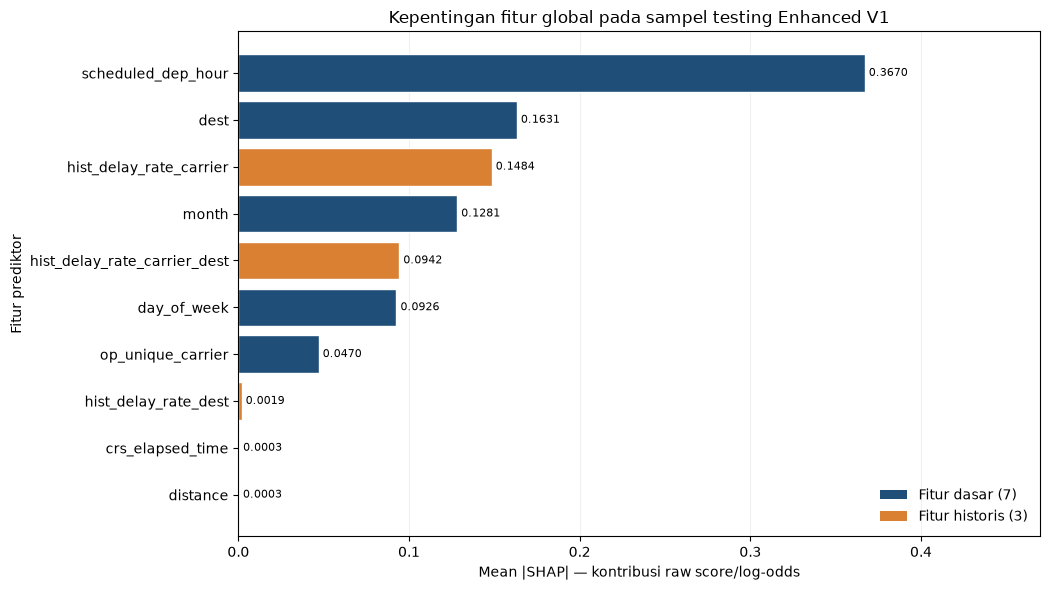

Tersimpan: output_4_4_2\Gambar\Gambar_4_9_SHAP_Global_Feature_Importance_Enhanced_V1.png


In [132]:
TITLE_49_442 = "Gambar 4.9 SHAP Global Feature Importance Model Enhanced"
FIG_49_442 = FIGURE_DIR_442 / "Gambar_4_9_SHAP_Global_Feature_Importance_Enhanced_V1.png"
print(TITLE_49_442)

ordered_442 = RANKED_442.iloc[::-1].copy()
fig, ax = plt.subplots(figsize=(10.6, 6.0))
colors_442 = ["#1F4E79" if group == "Dasar" else "#D98032"
              for group in ordered_442["kelompok"]]
bars = ax.barh(ordered_442["fitur"], ordered_442["mean_abs_shap_raw"],
               color=colors_442, edgecolor="white")
ax.set_xlabel("Mean |SHAP| — kontribusi raw score/log-odds")
ax.set_ylabel("Fitur prediktor")
ax.set_title("Kepentingan fitur global pada sampel testing Enhanced V1")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="#1F4E79", label="Fitur dasar (7)"),
                   Patch(facecolor="#D98032", label="Fitur historis (3)")],
          loc="lower right", frameon=False)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in ordered_442["mean_abs_shap_raw"]],
             padding=3, fontsize=8)
ax.set_xlim(0, max(ordered_442["mean_abs_shap_raw"]) * 1.28)
fig.tight_layout()
fig.savefig(FIG_49_442, dpi=320, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)
print("Tersimpan:", FIG_49_442)

### Gambar 4.10 — SHAP Summary / Beeswarm Plot
Untuk menghindari kesan adanya urutan pada kategori nominal, nilai op_unique_carrier dan dest diberi nilai warna netral konstan (0) pada data visualisasi saja. Warna titik kedua fitur nominal tidak ditafsirkan; kontribusi SHAP tetap dihitung pada matriks asli dengan tipe category.

Gambar 4.10 SHAP Summary Plot Model Enhanced


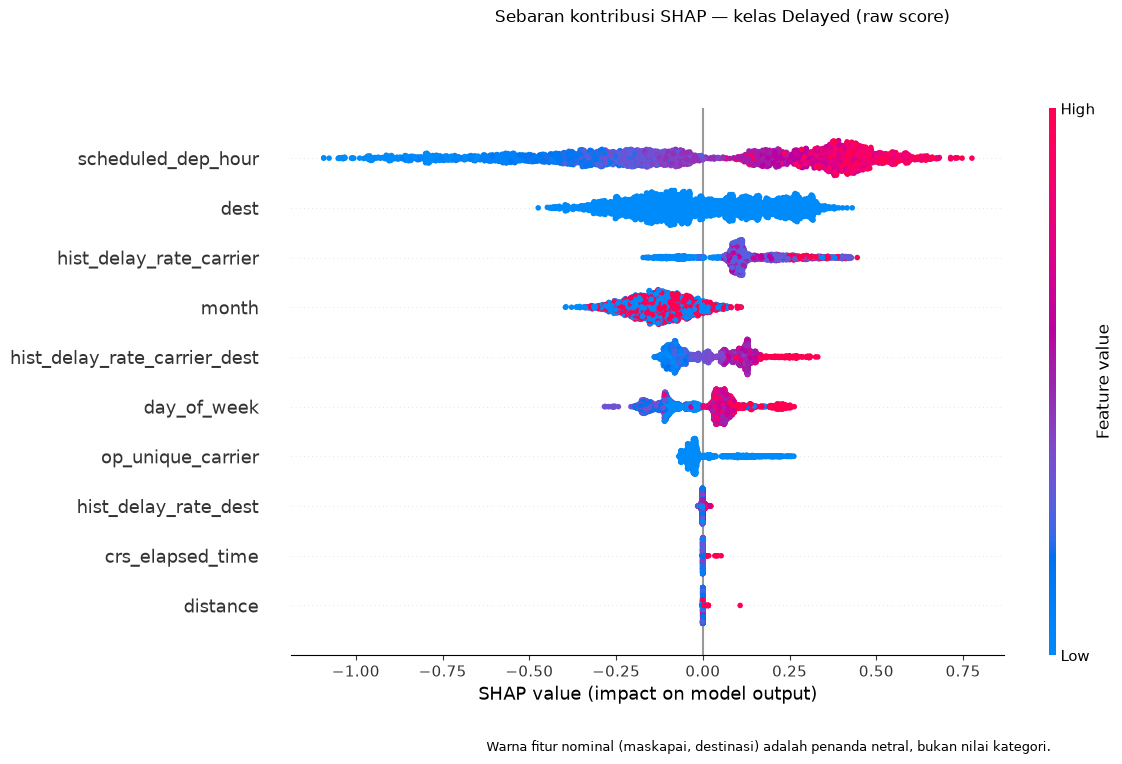

Tersimpan: output_4_4_2\Gambar\Gambar_4_10_SHAP_Summary_Beeswarm_Enhanced_V1.png


In [133]:
# Salinan khusus VISUALISASI — tidak pernah dipakai untuk inferensi model.
X_COLOR_442 = X_SHAP_442.copy()
for col in CAT_442:
    X_COLOR_442[col] = 0.0  # Nilai netral KONSTAN hanya untuk warna; bukan kode kategori.
X_COLOR_442 = X_COLOR_442.astype("float64")
assert X_SHAP_442[CAT_442].equals(X_test_enhanced.loc[X_SHAP_442.index, CAT_442])
EXPLANATION_GLOBAL_442 = shap.Explanation(
    values=SHAP_VALUES_442,
    base_values=np.full(len(X_SHAP_442), BASE_VALUE_442),
    data=X_COLOR_442.to_numpy(dtype=float),
    feature_names=EXPECTED_FEATURES_442,
)
TITLE_410_442 = "Gambar 4.10 SHAP Summary Plot Model Enhanced"
FIG_410_442 = FIGURE_DIR_442 / "Gambar_4_10_SHAP_Summary_Beeswarm_Enhanced_V1.png"
print(TITLE_410_442)
shap.plots.beeswarm(EXPLANATION_GLOBAL_442, max_display=10, show=False,
                    plot_size=(11.5, 7.1))
fig = plt.gcf()
fig.suptitle("Sebaran kontribusi SHAP — kelas Delayed (raw score)", y=1.02, fontsize=12)
fig.text(0.54, -0.025, "Warna fitur nominal (maskapai, destinasi) adalah penanda netral, bukan nilai kategori.",
         ha="center", fontsize=9)
fig.savefig(FIG_410_442, dpi=320, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)
print("Tersimpan:", FIG_410_442)

### Diagnostik arah kontribusi historis dan kaitan deskriptif dengan EDA
Koefisien Spearman hanya digunakan sebagai ringkasan asosiasi nilai fitur dengan SHAP dalam sampel, bukan penjelasan kausal atau ukuran peningkatan performa. Hasil mungkin nonlinier, sehingga harus dibaca bersama beeswarm.

In [134]:
HISTORIC_DIAG_442 = []
for col in HISTORY_442:
    j = EXPECTED_FEATURES_442.index(col)
    values = X_SHAP_442[col].to_numpy(dtype=float)
    effects = SHAP_VALUES_442[:, j]
    mask = np.isfinite(values)
    if mask.sum() >= 3 and len(np.unique(values[mask])) > 1:
        corr = spearmanr(values[mask], effects[mask])
        rho = float(corr.statistic)
    else:
        rho = np.nan
    HISTORIC_DIAG_442.append({
        "fitur": col,
        "mean_abs_shap": float(MEAN_ABS_442[j]),
        "min_shap": float(np.min(effects)),
        "max_shap": float(np.max(effects)),
        "proporsi_shap_positif": float(np.mean(effects > 0)),
        "n_nonmissing": int(mask.sum()),
        "spearman_fitur_shap": rho,
        "peringkat": int(RANKED_442.set_index("fitur").loc[col, "peringkat"]),
    })
HIST_DIAG_FRAME_442 = pd.DataFrame(HISTORIC_DIAG_442)
FILE_HIST_DIAG_442 = AUDIT_DIR_442 / "SHAP_Diagnostik_Tiga_Fitur_Historis.csv"
HIST_DIAG_FRAME_442.to_csv(FILE_HIST_DIAG_442, index=False)

print("DIAGNOSTIK TIGA FITUR HISTORIS")
for row in HISTORIC_DIAG_442:
    print(f"{row['fitur']}: peringkat {row['peringkat']}, mean|SHAP|={row['mean_abs_shap']:.6f}, "
          f"rentang=[{row['min_shap']:+.4f},{row['max_shap']:+.4f}], "
          f"SHAP positif={row['proporsi_shap_positif']:.1%}, "
          f"rho Spearman={row['spearman_fitur_shap']:.4f}")

hour_idx_442 = EXPECTED_FEATURES_442.index("scheduled_dep_hour")
hour_bins_442 = pd.cut(X_SHAP_442["scheduled_dep_hour"].to_numpy(),
                       bins=[-1, 5, 11, 17, 23],
                       labels=["00–05", "06–11", "12–17", "18–23"])
print("\nRATA-RATA KONTRIBUSI SHAP JAM BERDASARKAN KELOMPOK WAKTU")
for bin_label in hour_bins_442.categories:
    group_mask = np.asarray(hour_bins_442 == bin_label)
    print(f"{bin_label}: n={int(group_mask.sum())}, "
          f"rata-rata SHAP raw={SHAP_VALUES_442[group_mask, hour_idx_442].mean():+.5f}")
print("Bandingkan dengan pola EDA 4.1.2; asosiasi agregat tidak membuktikan sebab-akibat.")

DIAGNOSTIK TIGA FITUR HISTORIS
hist_delay_rate_carrier: peringkat 3, mean|SHAP|=0.148376, rentang=[-0.1721,+0.4451], SHAP positif=90.5%, rho Spearman=0.6134
hist_delay_rate_dest: peringkat 8, mean|SHAP|=0.001858, rentang=[-0.0151,+0.0229], SHAP positif=44.0%, rho Spearman=0.6569
hist_delay_rate_carrier_dest: peringkat 5, mean|SHAP|=0.094218, rentang=[-0.1405,+0.3313], SHAP positif=51.4%, rho Spearman=0.9059

RATA-RATA KONTRIBUSI SHAP JAM BERDASARKAN KELOMPOK WAKTU
00–05: n=17, rata-rata SHAP raw=-0.88782
06–11: n=1062, rata-rata SHAP raw=-0.46496
12–17: n=978, rata-rata SHAP raw=+0.08054
18–23: n=943, rata-rata SHAP raw=+0.43448
Bandingkan dengan pola EDA 4.1.2; asosiasi agregat tidak membuktikan sebab-akibat.


### Menetapkan tiga kasus lokal berdasarkan hasil klasifikasi V1 yang dibekukan
Pilih tepat satu contoh TP, FN, dan FP, menggunakan seed 42 dari tiap kelompok. Kasus dipilih tanpa memeriksa bentuk SHAP terlebih dahulu.

In [135]:
if "RESULTS_441" in globals():
    probabilities_all_442 = np.asarray(RESULTS_441["enhanced"]["probabilities"], dtype=float)
    assert np.isclose(float(RESULTS_441["enhanced"]["threshold"]), THRESHOLD_442, atol=1e-12)
else:
    probabilities_all_442 = np.asarray(MODEL_442.predict_proba(X_test_enhanced)[:, 1], dtype=float)
assert len(probabilities_all_442) == EXPECTED_TEST_442
assert np.isfinite(probabilities_all_442).all()
assert np.all((probabilities_all_442 >= 0) & (probabilities_all_442 <= 1))

# Cek referensi AP testing V1 dengan toleransi pembulatan enam desimal.
AP_ALL_442 = float(average_precision_score(y_test.to_numpy(), probabilities_all_442))
assert abs(AP_ALL_442 - 0.278441) < 1e-5, (
    "AP model yang dimuat tidak cocok dengan hasil 4.4.1 Enhanced V1; periksa file/matriks."
)

predictions_all_442 = (probabilities_all_442 >= THRESHOLD_442).astype(np.int8)
truth_all_442 = y_test.to_numpy(dtype=np.int8)
mask_types_442 = {
    "TP": (truth_all_442 == 1) & (predictions_all_442 == 1),
    "FN": (truth_all_442 == 1) & (predictions_all_442 == 0),
    "FP": (truth_all_442 == 0) & (predictions_all_442 == 1),
}
rng_local_442 = np.random.default_rng(SEED_442)
local_positions_442 = {}
for name, mask in mask_types_442.items():
    candidates = np.flatnonzero(mask)
    if len(candidates) == 0:
        raise RuntimeError(f"Tidak tersedia kasus {name} pada evaluasi Enhanced V1.")
    local_positions_442[name] = int(rng_local_442.choice(candidates))

X_LOCAL_442 = X_test_enhanced.iloc[list(local_positions_442.values())].copy()
assert X_LOCAL_442.index.is_unique and X_LOCAL_442.shape == (3,10)
LOCAL_INFO_442 = []
for name, position in local_positions_442.items():
    ix = X_test_enhanced.index[position]
    meta = df_prepared.loc[ix]
    item = {
        "kategori": name,
        "posisi_testing": position,
        "indeks_observasi": str(ix),
        "tanggal": pd.Timestamp(meta["fl_date"]).strftime("%Y-%m-%d"),
        "maskapai": str(meta["op_unique_carrier"]),
        "destinasi": str(meta["dest"]),
        "jam_terjadwal": int(X_test_enhanced.iloc[position]["scheduled_dep_hour"]),
        "label_aktual": int(truth_all_442[position]),
        "probabilitas_delayed": float(probabilities_all_442[position]),
        "threshold": THRESHOLD_442,
        "label_prediksi": int(predictions_all_442[position]),
    }
    LOCAL_INFO_442.append(item)
    assert mask_types_442[name][position]

FILE_LOCAL_CASES_442 = AUDIT_DIR_442 / "SHAP_Kasus_Lokal_TP_FN_FP_Enhanced_V1.csv"
pd.DataFrame(LOCAL_INFO_442).to_csv(FILE_LOCAL_CASES_442, index=False)
print("CONTOH PREDIKSI LOKAL YANG DIPILIH SECARA DETERMINISTIK")
for item in LOCAL_INFO_442:
    print(f"{item['kategori']}: indeks={item['indeks_observasi']}, tanggal={item['tanggal']}, "
          f"maskapai={item['maskapai']}, dest={item['destinasi']}, "
          f"jam={item['jam_terjadwal']:02d}, aktual={item['label_aktual']}, "
          f"P(Delayed)={item['probabilitas_delayed']:.6f}, threshold={THRESHOLD_442:.4f}, "
          f"prediksi={item['label_prediksi']}")

CONTOH PREDIKSI LOKAL YANG DIPILIH SECARA DETERMINISTIK
TP: indeks=288217, tanggal=2024-11-08, maskapai=F9, dest=FLL, jam=18, aktual=1, P(Delayed)=0.487484, threshold=0.2500, prediksi=1
FN: indeks=331470, tanggal=2024-12-23, maskapai=WN, dest=HOU, jam=16, aktual=1, P(Delayed)=0.225957, threshold=0.2500, prediksi=0
FP: indeks=315991, tanggal=2024-12-07, maskapai=DL, dest=LAS, jam=18, aktual=0, P(Delayed)=0.332367, threshold=0.2500, prediksi=1


### Perhitungan SHAP lokal pada TP, FN dan FP
Nilai dasar, kontribusi tiap fitur, skor mentah, serta probabilitas harus cocok dengan model terpilih; penentuan kelas SHAP dilakukan dengan pemeriksaan aditivitas seperti pada sampel global.

In [136]:
with warnings.catch_warnings(record=True) as local_warnings_442:
    warnings.simplefilter("always")
    local_raw_shap_442 = EXPLAINER_442.shap_values(X_LOCAL_442, check_additivity=False)
for w in local_warnings_442:
    print("Peringatan SHAP lokal:", str(w.message))

RAW_LOCAL_442 = np.asarray(MODEL_442.booster_.predict(X_LOCAL_442, raw_score=True), dtype=float)
P_LOCAL_442 = np.asarray(MODEL_442.predict_proba(X_LOCAL_442)[:, 1], dtype=float)
SV_LOCAL_442, BASE_LOCAL_442, FORMAT_LOCAL_442 = select_positive_shap_raw_442(
    local_raw_shap_442, EXPLAINER_442.expected_value, RAW_LOCAL_442, 10
)
assert np.isclose(BASE_LOCAL_442, BASE_VALUE_442, atol=1e-6)
assert np.allclose(RAW_LOCAL_442, BASE_LOCAL_442 + SV_LOCAL_442.sum(axis=1), atol=1e-5)
assert np.allclose(expit(RAW_LOCAL_442), P_LOCAL_442, atol=1e-7)
for j, item in enumerate(LOCAL_INFO_442):
    assert np.isclose(P_LOCAL_442[j], item["probabilitas_delayed"], atol=1e-10)

# Simpan kontribusi per kasus dalam CSV terpisah untuk reproduksi setiap waterfall.
file_local_shap_442 = AUDIT_DIR_442 / "SHAP_Nilai_Lokal_TP_FN_FP_Enhanced_V1.csv"
local_shap_rows_442 = []
for j, case in enumerate(LOCAL_INFO_442):
    for k, feat in enumerate(EXPECTED_FEATURES_442):
        local_shap_rows_442.append({
            "kategori": case["kategori"], "indeks_observasi": case["indeks_observasi"],
            "fitur": feat, "nilai_fitur": str(X_LOCAL_442.iloc[j, k]),
            "shap_raw": float(SV_LOCAL_442[j, k]),
            "base_value_raw": float(BASE_LOCAL_442),
            "final_raw": float(RAW_LOCAL_442[j]),
            "probabilitas": float(P_LOCAL_442[j])
        })
pd.DataFrame(local_shap_rows_442).to_csv(file_local_shap_442, index=False)
print("Audit aditivitas tiga kasus lokal: LULUS")
print("Format kelas lokal:", FORMAT_LOCAL_442)

Peringatan SHAP lokal: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
Audit aditivitas tiga kasus lokal: LULUS
Format kelas lokal: {'detected_format': 'matrix', 'expected_value_index': 0, 'maximum_additivity_error': 4.440892098500626e-16}


### Gambar 4.11 — SHAP Waterfall Plot pada Contoh Prediksi Penerbangan
Karena keterbatasan penggabungan panel pada versi SHAP, output dibuat sebagai tiga gambar berurutan: 4.11(a) TP, 4.11(b) FN, 4.11(c) FP. Tidak ada modifikasi nilai fitur pada saat inferensi.

Gambar 4.11(a) SHAP Waterfall Plot — TP


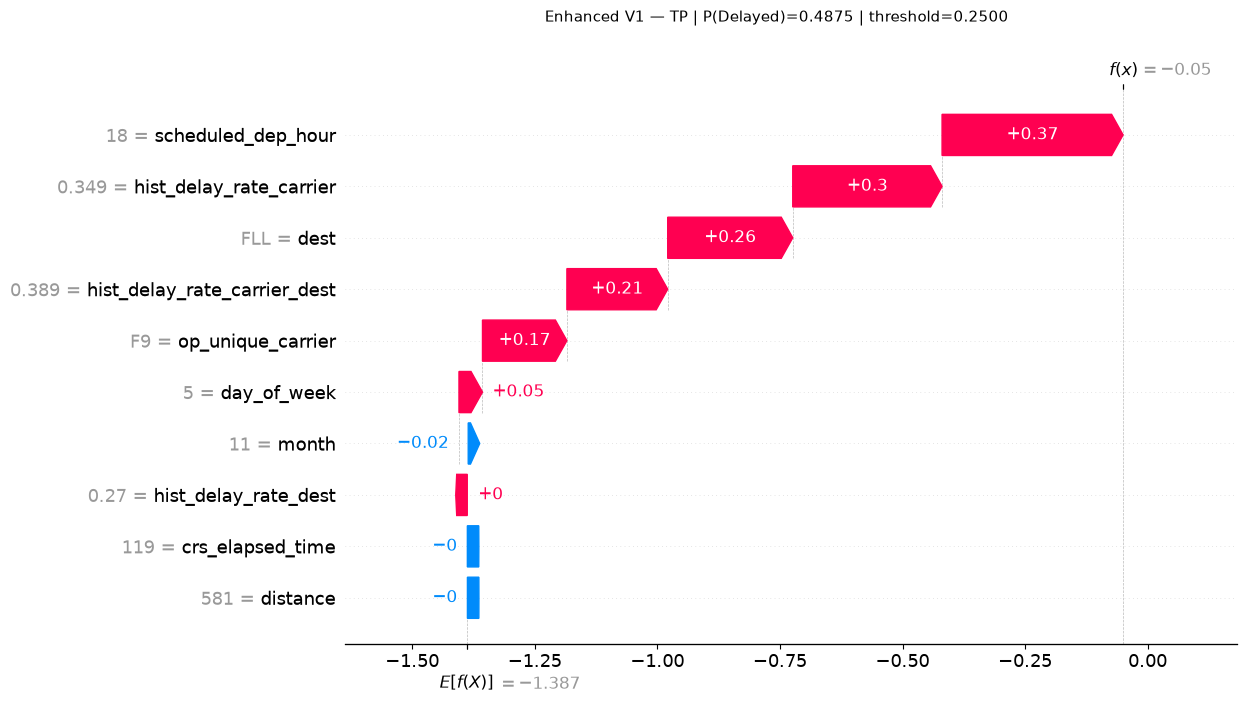

TP: base=-1.387423; raw akhir=-0.050074; probabilitas=0.487484
  Kontribusi paling menaikkan raw score: scheduled_dep_hour (+0.369235)
  Kontribusi paling menurunkan raw score: month (-0.018859)
  Catatan: SHAP dalam log-odds, bukan perubahan probabilitas langsung.
Gambar 4.11(b) SHAP Waterfall Plot — FN


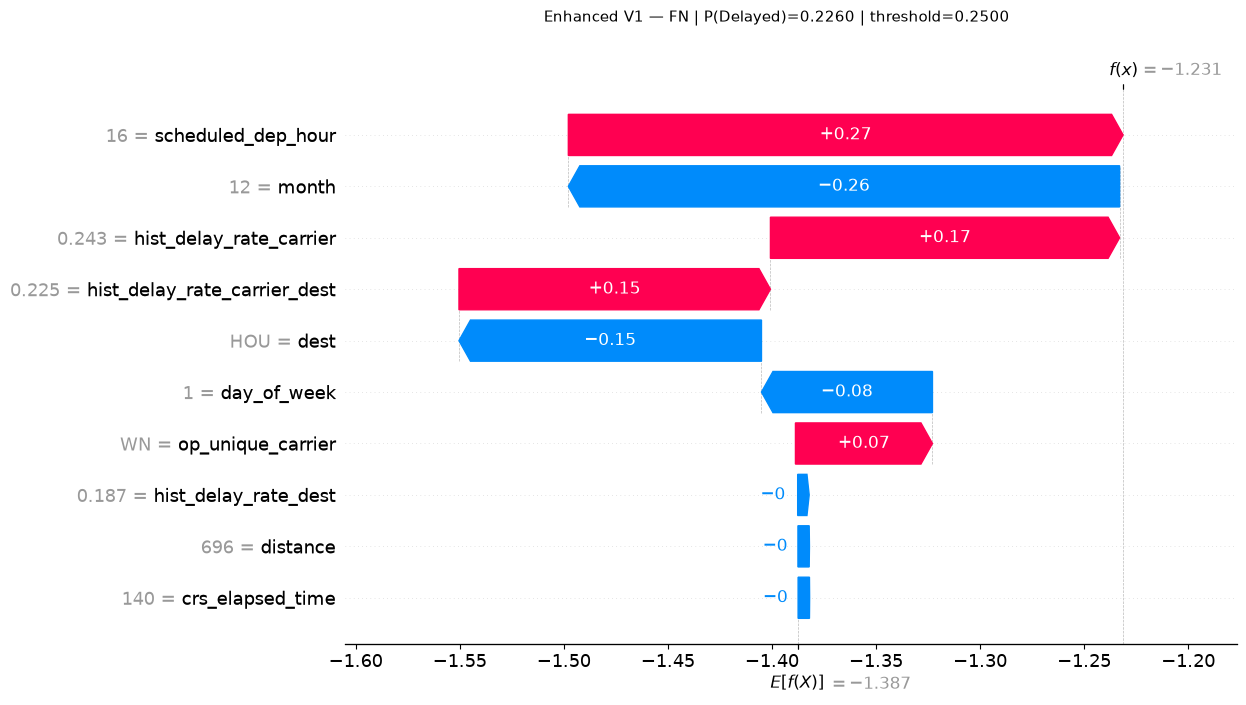

FN: base=-1.387423; raw akhir=-1.231284; probabilitas=0.225957
  Kontribusi paling menaikkan raw score: scheduled_dep_hour (+0.266544)
  Kontribusi paling menurunkan raw score: month (-0.264862)
  Catatan: SHAP dalam log-odds, bukan perubahan probabilitas langsung.
Gambar 4.11(c) SHAP Waterfall Plot — FP


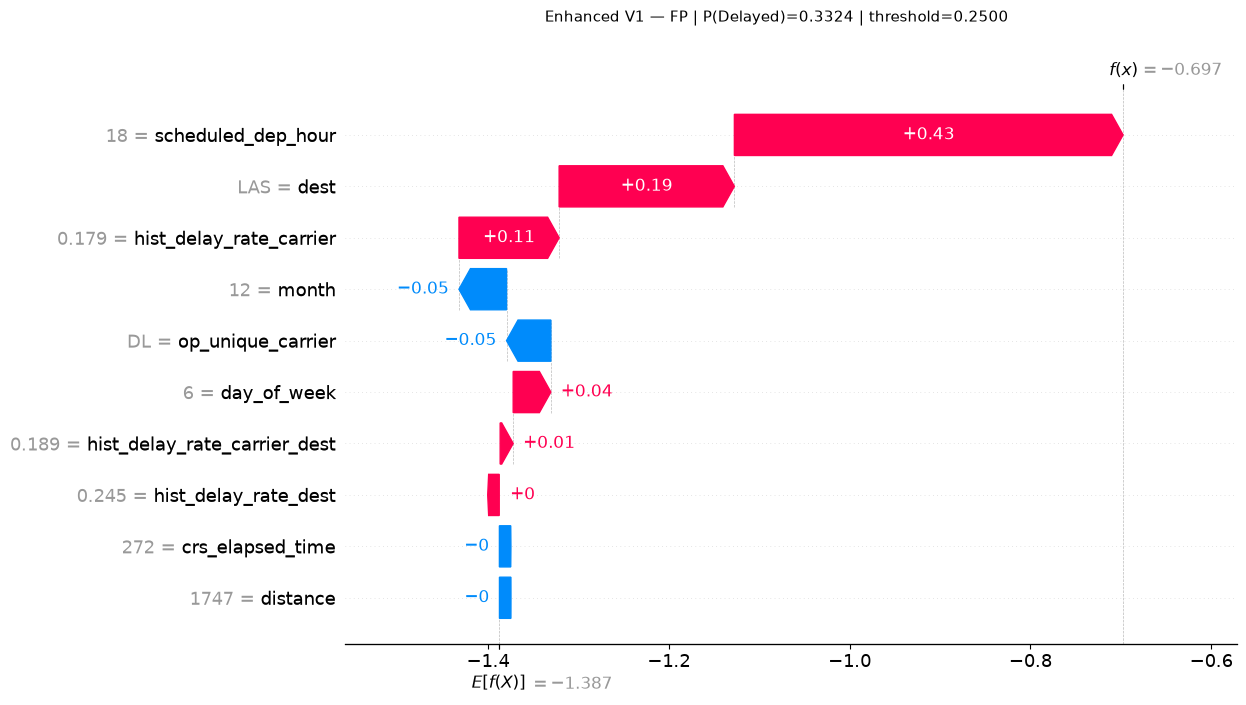

FP: base=-1.387423; raw akhir=-0.697499; probabilitas=0.332367
  Kontribusi paling menaikkan raw score: scheduled_dep_hour (+0.430048)
  Kontribusi paling menurunkan raw score: month (-0.052612)
  Catatan: SHAP dalam log-odds, bukan perubahan probabilitas langsung.


In [137]:
FIG_LOCAL_442 = {}
for j, name in enumerate(["TP", "FN", "FP"]):
    # Data dalam plot adalah tampilan nilai asli termasuk nama kategori dan NaN.
    row_values = X_LOCAL_442.iloc[j]
    display_values = [
        (str(row_values[col]) if col in CAT_442 else
         (float(row_values[col]) if pd.notna(row_values[col]) else np.nan))
        for col in EXPECTED_FEATURES_442
    ]
    explanation = shap.Explanation(
        values=SV_LOCAL_442[j], base_values=float(BASE_LOCAL_442),
        data=np.array(display_values, dtype=object),
        feature_names=EXPECTED_FEATURES_442,
    )
    title = f"Gambar 4.11({chr(ord('a') + j)}) SHAP Waterfall Plot — {name}"
    path = FIGURE_DIR_442 / f"Gambar_4_11{chr(ord('a')+j)}_SHAP_Waterfall_{name}.png"
    print(title)
    shap.plots.waterfall(explanation, max_display=10, show=False)
    fig = plt.gcf()
    fig.set_size_inches(11.5, 7.2)
    fig.suptitle(f"Enhanced V1 — {name} | P(Delayed)={P_LOCAL_442[j]:.4f} | "
                 f"threshold={THRESHOLD_442:.4f}", fontsize=11, y=0.99)
    fig.savefig(path, dpi=320, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    FIG_LOCAL_442[name] = path

    most_positive = int(np.argmax(SV_LOCAL_442[j]))
    most_negative = int(np.argmin(SV_LOCAL_442[j]))
    print(f"{name}: base={BASE_LOCAL_442:+.6f}; raw akhir={RAW_LOCAL_442[j]:+.6f}; "
          f"probabilitas={P_LOCAL_442[j]:.6f}")
    print(f"  Kontribusi paling menaikkan raw score: "
          f"{EXPECTED_FEATURES_442[most_positive]} ({SV_LOCAL_442[j,most_positive]:+.6f})")
    print(f"  Kontribusi paling menurunkan raw score: "
          f"{EXPECTED_FEATURES_442[most_negative]} ({SV_LOCAL_442[j,most_negative]:+.6f})")
    print("  Catatan: SHAP dalam log-odds, bukan perubahan probabilitas langsung.")

### Ekspor metadata, audit akhir, dan ringkasan interpretasi yang dibatasi hasil aktual
Menjamin integritas model V1 dan matriks test setelah analisis. Tidak ada tindakan pada Optuna, fit(), threshold, maupun data training. Kesimpulan SHAP adalah penjelasan keluaran model, bukan bukti penambahan fitur meningkatkan performa.

In [138]:
assert booster_sha256_442(MODEL_442) == MODEL_HASH_BEFORE_442
assert dict(MODEL_442.get_params()) == PARAMS_BEFORE_442
assert frame_sha256_442(X_test_enhanced) == X_HASH_BEFORE_442
assert frame_sha256_442(y_test) == Y_HASH_BEFORE_442
assert np.isclose(THRESHOLD_442, BUNDLE_442["threshold"], atol=1e-12)
assert np.isclose(THRESHOLD_442, META_432_442["enhanced"]["threshold"], atol=1e-12)
assert np.isfinite(SHAP_VALUES_442).all()
assert np.isfinite(SV_LOCAL_442).all()
assert SHAP_VALUES_442.shape == (SAMPLE_SIZE_442,10)
assert SV_LOCAL_442.shape == (3,10)
assert len(LOCAL_INFO_442) == 3
assert np.max(np.abs(BASE_VALUE_442 + SHAP_VALUES_442.sum(axis=1) - raw_model_442)) < 1e-5
assert np.max(np.abs(BASE_LOCAL_442 + SV_LOCAL_442.sum(axis=1) - RAW_LOCAL_442)) < 1e-5
assert np.array_equal(predictions_all_442, (probabilities_all_442 >= THRESHOLD_442).astype(np.int8))

ARTIFACTS_442 = [FIG_49_442, FIG_410_442, *FIG_LOCAL_442.values(),
                 FILE_IMPORTANCE_442, FILE_GROUPED_442, FILE_HIST_DIAG_442,
                 SAMPLE_FILE_442, FILE_LOCAL_CASES_442, file_local_shap_442]
assert all(p.is_file() and p.stat().st_size > 0 for p in ARTIFACTS_442)

metadata_442 = {
    "subchapter": "4.4.2", "experiment": "V1",
    "scenario": "enhanced", "positive_class": 1, "random_seed": SEED_442,
    "sample_size": SAMPLE_SIZE_442, "sample_delayed_rate": float(y_SHAP_442.mean()),
    "testing_total": EXPECTED_TEST_442, "testing_positive": int(y_test.sum()),
    "threshold_enhanced": THRESHOLD_442,
    "model_sha256": MODEL_HASH_BEFORE_442,
    "source_bundle_sha256": sha256_file_442(BUNDLE_PATH_442),
    "X_test_sha256": X_HASH_BEFORE_442,
    "y_test_sha256": Y_HASH_BEFORE_442,
    "shap_output": "raw/log-odds", "shap_format": SHAP_FORMAT_442,
    "shap_base_value": BASE_VALUE_442,
    "max_raw_additivity_error_global": float(np.max(np.abs(BASE_VALUE_442 + SHAP_VALUES_442.sum(axis=1) - raw_model_442))),
    "max_raw_additivity_error_local": float(np.max(np.abs(BASE_LOCAL_442 + SV_LOCAL_442.sum(axis=1) - RAW_LOCAL_442))),
    "versions": VERSIONS_442,
    "artifacts": [str(p) for p in ARTIFACTS_442],
    "note": "Interpretasi SHAP tidak dipakai untuk pemilihan ulang fitur, model, atau threshold."
}
META_FILE_442 = AUDIT_DIR_442 / "Metadata_SHAP_Enhanced_V1_4_4_2.json"
META_FILE_442.write_text(json.dumps(metadata_442, indent=2, ensure_ascii=False), encoding="utf-8")
print("AUDIT AKHIR 4.4.2: LULUS")
print("Model, parameter, threshold, matriks testing dan SHAP konsisten.")
print("Gambar 4.9, 4.10, 4.11a/b/c serta audit CSV/JSON tersimpan.")
print("\nTEMUAN RINGKAS (UNTUK PENULISAN SUBBAB; BUKAN NARASI FINAL)")
print(f"- Fitur global teratas: {RANKED_442.iloc[0]['fitur']} "
      f"(mean|SHAP|={RANKED_442.iloc[0]['mean_abs_shap_raw']:.6f}).")
for row in HISTORIC_DIAG_442:
    print(f"- {row['fitur']}: peringkat {row['peringkat']} "
          f"dari 10; mean|SHAP|={row['mean_abs_shap']:.6f}.")
print(f"- Kontribusi absolut historis: {GROUPED_442.loc['Historis','persentase_total_abs']:.2f}% "
      "dari jumlah mean|SHAP| sepuluh fitur dalam sampel.")
print(f"- AP testing Enhanced V1 tetap {AP_ALL_442:.6f}; "
      "AP Baseline V1 sebelumnya 0.282596 (referensi 4.4.1).")
print("- SHAP mengukur kontribusi pada skor model, bukan kenaikan AP atau efek kausal.")
print("- Hasil bergantung pada sampel testing 3.000 observasi; tidak dapat digeneralisasi tanpa batas.")
print("Selesai 4.4.2. Tidak ada SHAP V2 atau pekerjaan 4.4.3/Streamlit.")

AUDIT AKHIR 4.4.2: LULUS
Model, parameter, threshold, matriks testing dan SHAP konsisten.
Gambar 4.9, 4.10, 4.11a/b/c serta audit CSV/JSON tersimpan.

TEMUAN RINGKAS (UNTUK PENULISAN SUBBAB; BUKAN NARASI FINAL)
- Fitur global teratas: scheduled_dep_hour (mean|SHAP|=0.366981).
- hist_delay_rate_carrier: peringkat 3 dari 10; mean|SHAP|=0.148376.
- hist_delay_rate_dest: peringkat 8 dari 10; mean|SHAP|=0.001858.
- hist_delay_rate_carrier_dest: peringkat 5 dari 10; mean|SHAP|=0.094218.
- Kontribusi absolut historis: 23.44% dari jumlah mean|SHAP| sepuluh fitur dalam sampel.
- AP testing Enhanced V1 tetap 0.278441; AP Baseline V1 sebelumnya 0.282596 (referensi 4.4.1).
- SHAP mengukur kontribusi pada skor model, bukan kenaikan AP atau efek kausal.
- Hasil bergantung pada sampel testing 3.000 observasi; tidak dapat digeneralisasi tanpa batas.
Selesai 4.4.2. Tidak ada SHAP V2 atau pekerjaan 4.4.3/Streamlit.


In [139]:

# Ekstraksi hasil aktual untuk narasi Subbab 4.4.2

ranked = RANKED_442.set_index("fitur")
historis = [
    "hist_delay_rate_carrier",
    "hist_delay_rate_dest",
    "hist_delay_rate_carrier_dest"
]

print("=== PARAGRAF PERINGKAT FITUR HISTORIS ===")

for fitur in historis:
    r = ranked.loc[fitur]
    print(
        f"{fitur}: peringkat {int(r['peringkat'])}, "
        f"mean absolute SHAP = {r['mean_abs_shap_raw']:.6f}"
    )

print("\n=== TIGA FITUR PALING DOMINAN ===")
for _, r in RANKED_442.head(3).iterrows():
    print(
        f"{r['fitur']}: peringkat {int(r['peringkat'])}, "
        f"mean absolute SHAP = {r['mean_abs_shap_raw']:.6f}"
    )

print("\n=== KONTRIBUSI KELOMPOK FITUR ===")
for kelompok in ["Dasar", "Historis"]:
    r = GROUPED_442.loc[kelompok]
    print(
        f"{kelompok}: {r['persentase_total_abs']:.2f}%, "
        f"rerata per fitur = {r['rerata_per_fitur']:.6f}"
    )

print("\n=== DIAGNOSTIK HISTORIS ===")
print(HIST_DIAG_FRAME_442.to_string(index=False))

print("\n=== CONTOH PREDIKSI LOKAL ===")
for i, kasus in enumerate(LOCAL_INFO_442):
    shap_vals = SV_LOCAL_442[i]
    indeks_positif = int(np.argmax(shap_vals))
    indeks_negatif = int(np.argmin(shap_vals))

    print(
        f"{kasus['kategori']}: "
        f"probabilitas={kasus['probabilitas_delayed']:.6f}, "
        f"kontribusi positif terbesar="
        f"{EXPECTED_FEATURES_442[indeks_positif]} "
        f"({shap_vals[indeks_positif]:+.6f}), "
        f"kontribusi negatif terbesar="
        f"{EXPECTED_FEATURES_442[indeks_negatif]} "
        f"({shap_vals[indeks_negatif]:+.6f})"
    )


=== PARAGRAF PERINGKAT FITUR HISTORIS ===
hist_delay_rate_carrier: peringkat 3, mean absolute SHAP = 0.148376
hist_delay_rate_dest: peringkat 8, mean absolute SHAP = 0.001858
hist_delay_rate_carrier_dest: peringkat 5, mean absolute SHAP = 0.094218

=== TIGA FITUR PALING DOMINAN ===
scheduled_dep_hour: peringkat 1, mean absolute SHAP = 0.366981
dest: peringkat 2, mean absolute SHAP = 0.163132
hist_delay_rate_carrier: peringkat 3, mean absolute SHAP = 0.148376

=== KONTRIBUSI KELOMPOK FITUR ===
Dasar: 76.56%, rerata per fitur = 0.114058
Historis: 23.44%, rerata per fitur = 0.081484

=== DIAGNOSTIK HISTORIS ===
                       fitur  mean_abs_shap  min_shap  max_shap  proporsi_shap_positif  n_nonmissing  spearman_fitur_shap  peringkat
     hist_delay_rate_carrier       0.148376 -0.172146  0.445052               0.905333          3000             0.613419          3
        hist_delay_rate_dest       0.001858 -0.015117  0.022895               0.439667          3000             0.656

## 4.4.3 Sintesis Temuan dan Pembahasan Hasil Penelitian

In [142]:
from pathlib import Path
from html import escape
from datetime import datetime
import json, hashlib, sys
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from IPython.display import display

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1600)
pd.set_option("display.expand_frame_repr", False)

MANUAL_ROOT_V1_443 = None  # Contoh: Path(r"C:\...\Skripsi")
MANUAL_ROOT_V2_443 = None  # Isi bila output V2 berada di direktori lain
WINDOWS_PROJECT_443 = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures"
    r"\Semester 7 - SI\Skripsi"
)
CANDIDATES_443 = [Path.cwd(), Path.cwd().parent, WINDOWS_PROJECT_443]

def find_root_443(custom, relative_file):
    locations = ([Path(custom)] if custom is not None else []) + CANDIDATES_443
    found = next((p for p in locations if (p / relative_file).is_file()), None)
    if found is None:
        raise FileNotFoundError(
            f"File sumber belum tersedia: {relative_file}.\n"
            "Lokasi yang diperiksa:\n" + "\n".join(str(p) for p in locations)
            + "\nAtur MANUAL_ROOT_V1_443/MANUAL_ROOT_V2_443, lalu jalankan ulang sel."
        )
    return found

ROOT_V1_443 = find_root_443(MANUAL_ROOT_V1_443, "output_4_4_1/Audit/Ringkasan_Evaluasi_4_4_1.json")
ROOT_V2_443 = find_root_443(MANUAL_ROOT_V2_443, "output_eksperimen_v2_2024/OOF_V2_Baseline_Jan_Agu.csv")
OUTPUT_443 = ROOT_V1_443 / "output_4_4_3"
AUDIT_DIR_443 = OUTPUT_443 / "Audit"
for folder in (OUTPUT_443, AUDIT_DIR_443):
    folder.mkdir(parents=True, exist_ok=True)
WINDOWS_TABLE_DIR_443 = WINDOWS_PROJECT_443 / "Tabel Data"
TABLE_DIR_443 = WINDOWS_TABLE_DIR_443 if sys.platform.startswith("win") and WINDOWS_TABLE_DIR_443.is_dir() else OUTPUT_443 / "Tabel Data"
TABLE_DIR_443.mkdir(parents=True, exist_ok=True)
print("V1:", ROOT_V1_443.resolve())
print("V2:", ROOT_V2_443.resolve())
print("Output 4.4.3:", OUTPUT_443.resolve())
print("Tabel resmi:", TABLE_DIR_443.resolve())


V1: C:\Users\Lenovo\Documents\Skripsi
V2: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi
Output 4.4.3: C:\Users\Lenovo\Documents\Skripsi\output_4_4_3
Tabel resmi: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data


### Audit manifest artefak — tanpa mengarang hasil
Artefak kritis harus tersedia sebelum membuat tabel final. CSV prediksi OOF digunakan untuk memeriksa ulang AP, bukan melatih atau memilih model. Metadata 4.3.2 dan 4.4.2 digunakan untuk mengunci provenance V1.

In [143]:
ART_443 = {
    "V1 testing JSON": ROOT_V1_443 / "output_4_4_1/Audit/Ringkasan_Evaluasi_4_4_1.json",
    "V1 threshold metadata": ROOT_V1_443 / "output_4_3_2/Metadata_Validasi_dan_Threshold_4_3_2.json",
    "V1 SHAP importance": ROOT_V1_443 / "output_4_4_2/Audit/SHAP_Global_Feature_Importance_Enhanced_V1.csv",
    "V1 SHAP group": ROOT_V1_443 / "output_4_4_2/Audit/SHAP_Ringkasan_Kontribusi_Kelompok_V1.csv",
    "V1 SHAP metadata": ROOT_V1_443 / "output_4_4_2/Audit/Metadata_SHAP_Enhanced_V1_4_4_2.json",
    "V2 metadata": ROOT_V2_443 / "output_eksperimen_v2_2024/Metadata_Eksperimen_V2_2024.json",
    "V2 OOF baseline": ROOT_V2_443 / "output_eksperimen_v2_2024/OOF_V2_Baseline_Jan_Agu.csv",
    "V2 OOF enhanced": ROOT_V2_443 / "output_eksperimen_v2_2024/OOF_V2_Enhanced_Jan_Agu.csv",
    "V2 AP per fold": ROOT_V2_443 / "output_eksperimen_v2_2024/Audit_Lanjutan_AP_V2/Tabel_Eksperimen_V2_3_AP_Per_Fold.csv",
    "V2 bootstrap CI": ROOT_V2_443 / "output_eksperimen_v2_2024/Audit_Lanjutan_AP_V2/Tabel_Eksperimen_V2_4_Bootstrap_CI.csv",
}
missing_443 = [f"{name}: {path}" for name, path in ART_443.items() if not path.is_file() or path.stat().st_size == 0]
for name,path in ART_443.items():
    print(f"{'TERSEDIA' if path.is_file() and path.stat().st_size>0 else 'BELUM TERSEDIA':<16} {name}")
if missing_443:
    raise FileNotFoundError(
        "Audit 4.4.3 dihentikan; artefak resmi belum lengkap.\n"
        + "\n".join(missing_443)
        + "\nJalankan hanya sel EKSPOR yang relevan pada 4.4.1, 4.4.2, dan audit V2; "
          "jangan mengulang training/Optuna/SHAP."
    )

def sha_file_443(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fh:
        for block in iter(lambda: fh.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

SOURCE_SHA_443 = {name:sha_file_443(path) for name,path in ART_443.items()}
read_json_443 = lambda name: json.loads(ART_443[name].read_text(encoding="utf-8"))
V1_TEST_443 = read_json_443("V1 testing JSON")
V1_LOCK_443 = read_json_443("V1 threshold metadata")
V1_SHAP_META_443 = read_json_443("V1 SHAP metadata")
V2_META_443 = read_json_443("V2 metadata")
print("Manifest sepuluh sumber utama: lengkap; seluruh SHA-256 direkam.")


TERSEDIA         V1 testing JSON
TERSEDIA         V1 threshold metadata
TERSEDIA         V1 SHAP importance
TERSEDIA         V1 SHAP group
TERSEDIA         V1 SHAP metadata
TERSEDIA         V2 metadata
TERSEDIA         V2 OOF baseline
TERSEDIA         V2 OOF enhanced
TERSEDIA         V2 AP per fold
TERSEDIA         V2 bootstrap CI
Manifest sepuluh sumber utama: lengkap; seluruh SHA-256 direkam.


### Validasi hasil akhir dan konfigurasi terkunci V1
Verifikasi dua AP testing, enam metrik, kelas positif, jumlah observasi, threshold, serta hash artefak model. Angka hasil V1 yang pernah dilaporkan digunakan hanya untuk pemeriksaan konsistensi pembulatan.

In [144]:
EXPECTED_V1_443 = {
    "baseline": {"Average Precision (AP)":0.282596, "Accuracy":0.682292,
                 "Precision (Delayed)":0.269642, "Recall (Delayed)":0.442988,
                 "F1-Score (Delayed)":0.335232, "ROC-AUC":0.627177},
    "enhanced": {"Average Precision (AP)":0.278441, "Accuracy":0.679552,
                 "Precision (Delayed)":0.266439, "Recall (Delayed)":0.440365,
                 "F1-Score (Delayed)":0.332003, "ROC-AUC":0.622433},
}
assert V1_TEST_443["n_test"] == 56_936
assert V1_TEST_443["n_delayed"] == 10_296
assert V1_TEST_443["positive_class"] == 1
assert V1_TEST_443["selected_deployment_scenario_from_validation"] == "baseline"
assert V1_LOCK_443["selected_deployment_scenario"] == "baseline"
assert V1_TEST_443.get("retraining_performed") is False
assert V1_TEST_443.get("test_based_model_selection") is False

for s in ("baseline", "enhanced"):
    actual = V1_TEST_443["models"][s]["test_metrics"]
    for metric, expected in EXPECTED_V1_443[s].items():
        if not np.isclose(float(actual[metric]), expected, rtol=0, atol=1.5e-6):
            raise AssertionError(f"V1 {s} {metric} berbeda dari laporan: {actual[metric]} vs {expected}")
    locked = float(V1_LOCK_443[s]["threshold"])
    assert np.isclose(locked, float(V1_TEST_443["models"][s]["threshold_from_validation"]), atol=1e-12)
    expected_threshold = {"baseline":0.242, "enhanced":0.250}[s]
    assert np.isclose(locked, expected_threshold, atol=1e-10)
    bundle = ROOT_V1_443 / "output_4_3_2/Model dan Konfigurasi" / f"Model_4_3_2_{s.title()}_Threshold_Terkunci.joblib"
    if not bundle.is_file():
        raise FileNotFoundError(f"Bundel model terkunci tidak ditemukan: {bundle}")
    actual_sha = sha_file_443(bundle)
    assert actual_sha == V1_LOCK_443["model_files_sha256"][s], f"SHA bundel {s} berubah"
    assert (V1_TEST_443["model_sha256_frozen"][s]
            == V1_TEST_443["models"][s].get("model_sha256", V1_TEST_443["model_sha256_frozen"][s]))
    if s == "enhanced":
        assert actual_sha == V1_SHAP_META_443["source_bundle_sha256"]
        assert V1_SHAP_META_443["model_sha256"] == V1_TEST_443["model_sha256_frozen"]["enhanced"]
        assert np.isclose(V1_SHAP_META_443["threshold_enhanced"], locked, atol=1e-12)

AP_V1_B_443 = float(V1_TEST_443["models"]["baseline"]["test_metrics"]["Average Precision (AP)"])
AP_V1_E_443 = float(V1_TEST_443["models"]["enhanced"]["test_metrics"]["Average Precision (AP)"])
DELTA_V1_PP_443 = 100*(AP_V1_E_443 - AP_V1_B_443)
assert DELTA_V1_PP_443 < 0
CI_V1_443 = V1_TEST_443.get("bootstrap", {}).get("confidence_interval_delta_ap")
if CI_V1_443 is None:
    print("CI bootstrap V1: BELUM TERSEDIA (opsional; tidak akan diisi estimasi)")
else:
    CI_V1_443 = [100*float(v) for v in CI_V1_443]
    assert len(CI_V1_443) == 2 and CI_V1_443[0] <= CI_V1_443[1]
    for got, reported in zip(CI_V1_443, [-0.7881, -0.0914]):
        assert abs(got-reported) < 0.02, (
            "CI V1 berbeda dari nilai yang sebelumnya dilaporkan; "
            "periksa versi bootstrap pada 4.4.1."
        )
    print(f"CI bootstrap V1 (pp): {CI_V1_443[0]:+.4f} hingga {CI_V1_443[1]:+.4f}")
print(f"V1 testing: AP Baseline={AP_V1_B_443:.6f}; Enhanced={AP_V1_E_443:.6f}; "
      f"selisih={DELTA_V1_PP_443:+.4f} pp")
print("V1 dan model yang dipilih untuk Streamlit: tetap, provenance SHA valid.")


CI bootstrap V1 (pp): -0.7881 hingga -0.0914
V1 testing: AP Baseline=0.282596; Enhanced=0.278441; selisih=-0.4154 pp
V1 dan model yang dipilih untuk Streamlit: tetap, provenance SHA valid.


### Verifikasi nilai SHAP Enhanced V1 tanpa menghitung SHAP ulang
Nilai fitur global, kelompok, dan parameter explainer dibaca dari CSV/JSON 4.4.2; analisis menggunakan keluaran mentah (log-odds). Nilai absolut SHAP bukan ukuran peningkatan AP atau dampak kausal.

In [145]:
SHAP_FEATURE_443 = pd.read_csv(ART_443["V1 SHAP importance"])
SHAP_GROUP_443 = pd.read_csv(ART_443["V1 SHAP group"])
assert {"fitur", "kelompok", "mean_abs_shap_raw", "peringkat"}.issubset(SHAP_FEATURE_443)
assert {"kelompok", "jumlah_fitur", "persentase_total_abs"}.issubset(SHAP_GROUP_443)
assert len(SHAP_FEATURE_443)==10 and SHAP_FEATURE_443["fitur"].is_unique
assert set(SHAP_FEATURE_443["peringkat"]) == set(range(1,11))
assert set(SHAP_GROUP_443["kelompok"])=={"Dasar","Historis"}
assert SHAP_GROUP_443.set_index("kelompok")["jumlah_fitur"].to_dict()=={"Dasar":7,"Historis":3}
assert np.isclose(SHAP_GROUP_443["persentase_total_abs"].sum(),100,atol=1e-8)
assert V1_SHAP_META_443["sample_size"]==3000
assert V1_SHAP_META_443["shap_output"]=="raw/log-odds"
for key in ("max_raw_additivity_error_global", "max_raw_additivity_error_local"):
    assert 0 <= float(V1_SHAP_META_443[key]) < 1e-5

EXPECTED_SHAP_443={"scheduled_dep_hour":(1,0.366981),
                    "dest":(2,0.163132),
                    "hist_delay_rate_carrier":(3,0.148376),
                    "hist_delay_rate_carrier_dest":(5,0.094218),
                    "hist_delay_rate_dest":(8,0.001858)}
by_feature_443=SHAP_FEATURE_443.set_index("fitur")
for feature,(rank,val) in EXPECTED_SHAP_443.items():
    assert int(by_feature_443.loc[feature,"peringkat"])==rank
    assert np.isclose(float(by_feature_443.loc[feature,"mean_abs_shap_raw"]), val, atol=1.5e-6,rtol=0)
SHAP_SHARE_HIST_443=float(SHAP_GROUP_443.set_index("kelompok").loc["Historis","persentase_total_abs"])
assert abs(SHAP_SHARE_HIST_443 - 23.44) <= 0.03
print("SHAP V1: 5 fitur terbesar (peringkat dan mean absolute SHAP):")
for _,row in SHAP_FEATURE_443.sort_values("peringkat").head(5).iterrows():
    print(f"  {int(row['peringkat'])}. {row['fitur']}: {row['mean_abs_shap_raw']:.6f}")
print("Tiga fitur historis:")
for _,row in SHAP_FEATURE_443.loc[SHAP_FEATURE_443['kelompok'].eq('Historis')].sort_values('peringkat').iterrows():
    print(f"  #{int(row['peringkat'])} {row['fitur']} = {row['mean_abs_shap_raw']:.6f}")
print(f"Proporsi absolut SHAP: Dasar={100-SHAP_SHARE_HIST_443:.2f}%; Historis={SHAP_SHARE_HIST_443:.2f}%")
print("Skala log-odds; tidak setara dengan peningkatan AP maupun sebab-akibat.")


SHAP V1: 5 fitur terbesar (peringkat dan mean absolute SHAP):
  1. scheduled_dep_hour: 0.366981
  2. dest: 0.163132
  3. hist_delay_rate_carrier: 0.148376
  4. month: 0.128149
  5. hist_delay_rate_carrier_dest: 0.094218
Tiga fitur historis:
  #3 hist_delay_rate_carrier = 0.148376
  #5 hist_delay_rate_carrier_dest = 0.094218
  #8 hist_delay_rate_dest = 0.001858
Proporsi absolut SHAP: Dasar=76.56%; Historis=23.44%
Skala log-odds; tidak setara dengan peningkatan AP maupun sebab-akibat.


### Audit prediksi OOF dan AP per fold V2
Baca file prediksi OOF yang sama dan hitung kembali AP untuk mengonfirmasi tabel audit sebelumnya. Empat fold dibedakan menurut Mei–Agustus 2024. Jangan bandingkan nilai AP testing V1 langsung dengan AP OOF V2 sebagai ukuran keunggulan model.

In [146]:
OOF_B_443 = pd.read_csv(ART_443["V2 OOF baseline"], parse_dates=["fl_date"])
OOF_E_443 = pd.read_csv(ART_443["V2 OOF enhanced"], parse_dates=["fl_date"])
OOF_REQUIRED_443={"flight_uid", "fl_date", "fold", "y_true", "y_proba"}
for s,df in (("Baseline",OOF_B_443),("Enhanced",OOF_E_443)):
    assert OOF_REQUIRED_443.issubset(df.columns), f"Kolom OOF {s} tidak lengkap"
    assert df["flight_uid"].is_unique and len(df)==116_384
    assert set(df["fold"])=={1,2,3,4}
    assert set(df["y_true"])=={0,1}
    assert np.isfinite(df["y_proba"]).all() and df["y_proba"].between(0,1).all()

OOF_PAIR_443 = OOF_B_443[["flight_uid","fl_date","fold","y_true","y_proba"]].merge(
    OOF_E_443[["flight_uid","fl_date","fold","y_true","y_proba"]],
    on="flight_uid", how="inner", validate="one_to_one", suffixes=("_base","_enh")
)
assert len(OOF_PAIR_443)==116_384
for col in ("fl_date","fold","y_true"):
    assert OOF_PAIR_443[f"{col}_base"].equals(OOF_PAIR_443[f"{col}_enh"]), f"OOF {col} tidak identik"
OOF_PAIR_443 = OOF_PAIR_443.rename(columns={
    "fl_date_base":"fl_date", "fold_base":"fold", "y_true_base":"y_true",
    "y_proba_base":"prob_base", "y_proba_enh":"prob_enh"
})[["flight_uid","fl_date","fold","y_true","prob_base","prob_enh"]]

FOLD_TABLE_443=pd.read_csv(ART_443["V2 AP per fold"])
assert {"Fold","Validasi","Observasi","AP Baseline","AP Enhanced","Selisih AP (pp)"}.issubset(FOLD_TABLE_443)
assert list(FOLD_TABLE_443["Fold"])==[1,2,3,4]
EXPECTED_MONTH_443={1:(5,29697),2:(6,29218),3:(7,28294),4:(8,29175)}
for _, r in FOLD_TABLE_443.iterrows():
    fold=int(r["Fold"])
    sub=OOF_PAIR_443.loc[OOF_PAIR_443["fold"].eq(fold)]
    month,n=EXPECTED_MONTH_443[fold]
    assert len(sub)==n==int(r["Observasi"])
    assert sub["fl_date"].dt.month.eq(month).all()
    ap_base=float(average_precision_score(sub["y_true"], sub["prob_base"]))
    ap_enh=float(average_precision_score(sub["y_true"], sub["prob_enh"]))
    assert np.isclose(ap_base,r["AP Baseline"],atol=1e-8)
    assert np.isclose(ap_enh,r["AP Enhanced"],atol=1e-8)
    assert np.isclose(100*(ap_enh-ap_base),r["Selisih AP (pp)"],atol=1e-7)
    assert np.isclose(sub["y_true"].mean(),r["Prevalensi Delayed"],atol=1e-7)

AP_MEAN_B_443=float(FOLD_TABLE_443["AP Baseline"].mean())
AP_MEAN_E_443=float(FOLD_TABLE_443["AP Enhanced"].mean())
AP_POOLED_B_443=float(average_precision_score(OOF_PAIR_443["y_true"],OOF_PAIR_443["prob_base"]))
AP_POOLED_E_443=float(average_precision_score(OOF_PAIR_443["y_true"],OOF_PAIR_443["prob_enh"]))
DELTA_V2_MEAN_PP_443=100*(AP_MEAN_E_443-AP_MEAN_B_443)
DELTA_V2_POOLED_PP_443=100*(AP_POOLED_E_443-AP_POOLED_B_443)
for value,expected in ((AP_MEAN_B_443,.379080),(AP_MEAN_E_443,.386604),
                       (AP_POOLED_B_443,.329671),(AP_POOLED_E_443,.353547)):
    assert np.isclose(value,expected,atol=1.5e-6,rtol=0),f"AP V2 {value} berbeda dari laporan"
assert (FOLD_TABLE_443["Selisih AP (pp)"]>0).sum()==2
assert (FOLD_TABLE_443["Selisih AP (pp)"]<0).sum()==2
print("HASIL V2 — validasi internal, bukan testing independen")
for _, r in FOLD_TABLE_443.iterrows():
    print(f"{r['Validasi']}: AP Baseline={r['AP Baseline']:.6f}; "
          f"Enhanced={r['AP Enhanced']:.6f}; selisih={r['Selisih AP (pp)']:+.4f} pp")
print(f"Rerata 4-fold: B={AP_MEAN_B_443:.6f}; E={AP_MEAN_E_443:.6f}; delta={DELTA_V2_MEAN_PP_443:+.4f} pp")
print(f"OOF gabungan: B={AP_POOLED_B_443:.6f}; E={AP_POOLED_E_443:.6f}; delta={DELTA_V2_POOLED_PP_443:+.4f} pp")
print("Fold Enhanced unggul: 2 dari 4; tidak boleh disebut konsisten di semua bulan.")


HASIL V2 — validasi internal, bukan testing independen
Mei 2024: AP Baseline=0.384810; Enhanced=0.367765; selisih=-1.7045 pp
Juni 2024: AP Baseline=0.339698; Enhanced=0.351072; selisih=+1.1374 pp
Juli 2024: AP Baseline=0.511682; Enhanced=0.483139; selisih=-2.8543 pp
Agustus 2024: AP Baseline=0.280131; Enhanced=0.344441; selisih=+6.4311 pp
Rerata 4-fold: B=0.379080; E=0.386604; delta=+0.7524 pp
OOF gabungan: B=0.329671; E=0.353547; delta=+2.3877 pp
Fold Enhanced unggul: 2 dari 4; tidak boleh disebut konsisten di semua bulan.


### Audit bootstrap V2 dan riwayat trial tanpa pengulangan komputasi
Gunakan interval dari file yang sudah diekspor. Baca metadata V2 untuk memastikan 20 trial per skenario, jumlah fitur, dan tidak adanya data September–Desember pada pengembangan. Pengujian bootstrap tidak dijalankan ulang.

In [147]:
BOOT_TABLE_443=pd.read_csv(ART_443["V2 bootstrap CI"])
BOOT_REQUIRED_443={"Ukuran", "Selisih aktual (pp)", "CI 95% bawah (pp)", "CI 95% atas (pp)", "CI mencakup nol"}
assert BOOT_REQUIRED_443.issubset(BOOT_TABLE_443) and len(BOOT_TABLE_443)==2
EXPECTED_BOOT_443=[
    (DELTA_V2_MEAN_PP_443,-1.2426,2.3339,"Ya"),
    (DELTA_V2_POOLED_PP_443,0.6196,3.9665,"Tidak"),
]
for idx, (actual_delta, expected_lo, expected_hi, reported_zero) in enumerate(EXPECTED_BOOT_443):
    row=BOOT_TABLE_443.iloc[idx]
    lo=float(row["CI 95% bawah (pp)"])
    hi=float(row["CI 95% atas (pp)"])
    assert np.isfinite([lo,hi]).all() and lo <= hi
    assert abs(float(row["Selisih aktual (pp)"])-actual_delta) < 1e-6
    assert abs(lo-expected_lo)<.00025 and abs(hi-expected_hi)<.00025
    assert ("Ya" if lo<=0<=hi else "Tidak")==row["CI mencakup nol"]==reported_zero

assert V2_META_443["status"]=="EXPLORATORY_V2_NO_BLIND_TEST"
assert V2_META_443["n_development"]==223_971
assert V2_META_443["n_trials_per_scenario"]==20
assert V2_META_443["no_sep_dec_data_used"] is True
assert len(V2_META_443["base_features"])==10
assert len(V2_META_443["enhanced_features"])==28
assert list(V2_META_443["fold_months"])==[5,6,7,8]
for s,ap_fold,ap_pool in (("Baseline",AP_MEAN_B_443,AP_POOLED_B_443),
                           ("Enhanced",AP_MEAN_E_443,AP_POOLED_E_443)):
    result=V2_META_443["results"][s]
    assert np.isclose(result["ap_fold_mean"],ap_fold,atol=1e-8)
    assert np.isclose(result["ap_pooled_oof"],ap_pool,atol=1e-8)
    assert len(result["ap_by_fold"])==4
    assert np.allclose(result["ap_by_fold"], FOLD_TABLE_443[f"AP {s}"], atol=1e-8)

for _,row in BOOT_TABLE_443.iterrows():
    print(f"{row['Ukuran']}: {row['Selisih aktual (pp)']:+.4f} pp, "
          f"CI 95% [{row['CI 95% bawah (pp)']:+.4f}, {row['CI 95% atas (pp)']:+.4f}]; "
          f"mencakup 0 = {row['CI mencakup nol']}")
BOOT_DRAWS_PATH_443=(ROOT_V2_443 / "output_eksperimen_v2_2024/Audit_Lanjutan_AP_V2"
                     / "Audit_V2_Replikasi_Block_Bootstrap.csv")
if BOOT_DRAWS_PATH_443.is_file():
    draws_443=pd.read_csv(BOOT_DRAWS_PATH_443)
    assert len(draws_443)==1000, f"Ditemukan {len(draws_443)} replikasi; harap cek riwayat bootstrap."
    print("Replikasi bootstrap V2: 1.000 (diverifikasi dari CSV audit).")
else:
    print("CSV replikasi bootstrap V2 belum tersedia: jumlah 1.000 berasal dari konfigurasi")
    print("notebook audit V2; verifikasi ulang jumlah replikasi dari output laptop diperlukan.")
print("Bootstrap: resampling berpasangan per blok tanggal, distratifikasi per bulan/fold;")
print("interval merupakan ketidakpastian bersyarat setelah pemilihan konfigurasi, bukan uji eksternal independen.")
print("Metadata V2: 20 trial/skenario, 10 vs 28 fitur, Januari–Agustus, tanpa testing.")

# Audit ringan riwayat Optuna (jika tersedia) — hanya membaca CSV ekspor
for s in ("Baseline","Enhanced"):
    trials_path=ROOT_V2_443 / "output_eksperimen_v2_2024/Optuna" / f"Optuna_V2_{s}_Trials.csv"
    if trials_path.is_file():
        trials=pd.read_csv(trials_path)
        completed=trials["state"].astype(str).str.upper().eq("COMPLETE") if "state" in trials else pd.Series([True]*len(trials))
        assert int(completed.sum())==20, f"Trial {s} lengkap bukan 20; audit konfigurasi!"
        print(f"Riwayat trial Optuna {s}: 20 COMPLETE (CSV terverifikasi)")
    else:
        print(f"Riwayat CSV Optuna {s}: belum tersedia (metadata V2 tetap tercatat 20 trial)")


Selisih AP rerata 4-fold (pp): +0.7524 pp, CI 95% [-1.2426, +2.3339]; mencakup 0 = Ya
Selisih AP OOF gabungan (pp): +2.3877 pp, CI 95% [+0.6196, +3.9665]; mencakup 0 = Tidak
Replikasi bootstrap V2: 1.000 (diverifikasi dari CSV audit).
Bootstrap: resampling berpasangan per blok tanggal, distratifikasi per bulan/fold;
interval merupakan ketidakpastian bersyarat setelah pemilihan konfigurasi, bukan uji eksternal independen.
Metadata V2: 20 trial/skenario, 10 vs 28 fitur, Januari–Agustus, tanpa testing.
Riwayat trial Optuna Baseline: 20 COMPLETE (CSV terverifikasi)
Riwayat trial Optuna Enhanced: 20 COMPLETE (CSV terverifikasi)


### Tabel 4.11 — Ringkasan Temuan Berdasarkan Rumusan Masalah
Satu tabel resmi berisi tiga rumusan masalah yang telah dibahas dalam 4.4.1–4.4.3. Nilai diisi dari variabel hasil audit aktual, tanpa menyalin ulang tabel metrik. RM4 terkait Streamlit belum dibahas pada subbab ini.

In [148]:
RM1_NOTE_443=(
    "Tiga fitur tingkat keterlambatan historis berhasil dibentuk dengan pendekatan walk-forward "
    "dan batas t_gate_proxy < t_cutoff (T−2h); kelompok tanpa riwayat dipertahankan sebagai NaN. "
    "Waktu ketersediaan hasil historis memakai proksi, bukan waktu publikasi aktual yang terverifikasi."
)
RM2_NOTE_443=(
    f"Pada testing V1, AP Enhanced {AP_V1_E_443:.6f} lebih rendah daripada Baseline {AP_V1_B_443:.6f} "
    f"(Δ {DELTA_V1_PP_443:+.4f} pp). Sebagai eksplorasi, V2 memberi Δ rerata AP "
    f"{DELTA_V2_MEAN_PP_443:+.4f} pp pada empat fold internal, tetapi hanya unggul pada "
    "dua fold dan CI rerata AP mencakup nol."
)
RM3_NOTE_443=(
    f"Pada Enhanced V1, scheduled_dep_hour menempati peringkat pertama; "
    f"fitur historis menyumbang {SHAP_SHARE_HIST_443:.2f}% dari jumlah mean absolute SHAP "
    "dalam sampel 3.000 observasi. Besaran SHAP menjelaskan prediksi, bukan kenaikan AP atau pengaruh kausal."
)
TABEL_411_443 = pd.DataFrame([
    {"Rumusan Masalah":"RM1", "Fokus Analisis":"Pembentukan fitur historis sesuai T−2h",
     "Temuan Utama":RM1_NOTE_443, "Dasar Hasil":"Subbab 4.2.2 (audit temporal V1)"},
    {"Rumusan Masalah":"RM2", "Fokus Analisis":"Perbandingan Baseline dan Enhanced",
     "Temuan Utama":RM2_NOTE_443, "Dasar Hasil":"Subbab 4.4.1 (testing V1); validasi internal V2"},
    {"Rumusan Masalah":"RM3", "Fokus Analisis":"Kontribusi fitur dasar dan historis melalui SHAP",
     "Temuan Utama":RM3_NOTE_443, "Dasar Hasil":"Subbab 4.4.2 (SHAP Enhanced V1)"},
])
assert len(TABEL_411_443)==3 and list(TABEL_411_443["Rumusan Masalah"])==["RM1","RM2","RM3"]
print("Tabel 4.11 Ringkasan Temuan Penelitian Berdasarkan Rumusan Masalah")
display(TABEL_411_443.style.set_properties(**{
    "white-space":"normal", "overflow-wrap":"break-word", "text-align":"left"
}).set_table_styles([{"selector":"th", "props":[("text-align","left")]}]))

FILE_CSV_443 = TABLE_DIR_443 / "Tabel_4_11_Ringkasan_Temuan_Berdasarkan_Rumusan_Masalah.csv"
FILE_HTML_443 = TABLE_DIR_443 / "Tabel_4_11_Ringkasan_Temuan_Berdasarkan_Rumusan_Masalah.html"
TABEL_411_443.to_csv(FILE_CSV_443,index=False,encoding="utf-8-sig")
columns_443 = list(TABEL_411_443.columns)
rows_html_443="".join("<tr>"+"".join("<td>"+escape(str(row[c]))+"</td>" for c in columns_443)+"</tr>"
                      for _,row in TABEL_411_443.iterrows())
css_443="""<style>
@page{size:A4 portrait;margin:1.5cm}body{font-family:Arial,Calibri,sans-serif;color:#111;font-size:9.2pt}
h2{font-size:11pt;text-align:center;margin:0 0 11px;line-height:1.35}
table{width:100%;border-collapse:collapse;table-layout:fixed}th,td{border:1px solid #444;padding:6px;vertical-align:top;overflow-wrap:break-word;line-height:1.3}
th{background:#e9e9e9;text-align:left}th:nth-child(1){width:8%}th:nth-child(2){width:20%}
th:nth-child(3){width:52%}th:nth-child(4){width:20%}p{font-size:8.5pt;margin-top:10px}
</style>"""
FILE_HTML_443.write_text(
    "<!DOCTYPE html><html lang='id'><head><meta charset='utf-8'>"+css_443+"</head><body>"
    "<h2>Tabel 4.11 Ringkasan Temuan Penelitian Berdasarkan Rumusan Masalah</h2><table><thead><tr>"
    +"".join("<th>"+escape(c)+"</th>" for c in columns_443)+"</tr></thead><tbody>"
    +rows_html_443+"</tbody></table>"
    "<p>V1 merupakan eksperimen utama pada hold-out November–Desember 2024. V2 adalah eksperimen eksploratif "
    "dengan validasi internal Mei–Agustus 2024, bukan pengujian eksternal independen. "
    "SHAP berada pada skala raw score/log-odds dan tidak mengukur hubungan sebab-akibat.</p></body></html>",
    encoding="utf-8")
assert FILE_CSV_443.is_file() and FILE_HTML_443.is_file()
print("CSV:",FILE_CSV_443.resolve())
print("HTML untuk Word:",FILE_HTML_443.resolve())


Tabel 4.11 Ringkasan Temuan Penelitian Berdasarkan Rumusan Masalah


,Rumusan Masalah,Fokus Analisis,Temuan Utama,Dasar Hasil
0,RM1,Pembentukan fitur historis sesuai T−2h,"Tiga fitur tingkat keterlambatan historis berhasil dibentuk dengan pendekatan walk-forward dan batas t_gate_proxy < t_cutoff (T−2h); kelompok tanpa riwayat dipertahankan sebagai NaN. Waktu ketersediaan hasil historis memakai proksi, bukan waktu publikasi aktual yang terverifikasi.",Subbab 4.2.2 (audit temporal V1)
1,RM2,Perbandingan Baseline dan Enhanced,"Pada testing V1, AP Enhanced 0.278441 lebih rendah daripada Baseline 0.282596 (Δ -0.4154 pp). Sebagai eksplorasi, V2 memberi Δ rerata AP +0.7524 pp pada empat fold internal, tetapi hanya unggul pada dua fold dan CI rerata AP mencakup nol.",Subbab 4.4.1 (testing V1); validasi internal V2
2,RM3,Kontribusi fitur dasar dan historis melalui SHAP,"Pada Enhanced V1, scheduled_dep_hour menempati peringkat pertama; fitur historis menyumbang 23.44% dari jumlah mean absolute SHAP dalam sampel 3.000 observasi. Besaran SHAP menjelaskan prediksi, bukan kenaikan AP atau pengaruh kausal.",Subbab 4.4.2 (SHAP Enhanced V1)


CSV: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_11_Ringkasan_Temuan_Berdasarkan_Rumusan_Masalah.csv
HTML untuk Word: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Tabel Data\Tabel_4_11_Ringkasan_Temuan_Berdasarkan_Rumusan_Masalah.html


### Ekspor ringkasan audit dan batas pembahasan literatur
Ringkasan ini tidak menggantikan narasi akademik. Perbandingan Alfarhood et al. [2], Mamdouh et al. [5], dan Kim dan Park [16] harus mengambil metode serta angka dari Bab II/artikel asli; jangan menyisipkan metrik penelitian lain jika tidak tersedia.

In [149]:
SUMMARY_443 = {
    "subchapter":"4.4.3", "status":"VERIFIED_FROM_EXPORTED_ARTIFACTS",
    "v1_main_experiment":{
        "testing_period":"2024-11..2024-12", "n_test":56936,
        "ap_baseline":AP_V1_B_443, "ap_enhanced":AP_V1_E_443,
        "delta_ap_pp":DELTA_V1_PP_443, "bootstrap_ci_pp":CI_V1_443,
        "deployment_scenario_frozen":"baseline"},
    "shap_enhanced_v1":{
        "sample_size":int(V1_SHAP_META_443["sample_size"]),
        "ranking":SHAP_FEATURE_443.sort_values("peringkat")[
            ["fitur","peringkat","mean_abs_shap_raw"]].to_dict("records"),
        "historical_share_percent":SHAP_SHARE_HIST_443},
    "v2_exploratory_internal":{
        "period":"2024-01..2024-08", "n_dev":223971,"n_oof":len(OOF_PAIR_443),
        "mean_four_folds":{"baseline":AP_MEAN_B_443,"enhanced":AP_MEAN_E_443,"delta_pp":DELTA_V2_MEAN_PP_443},
        "pooled_oof":{"baseline":AP_POOLED_B_443,"enhanced":AP_POOLED_E_443,"delta_pp":DELTA_V2_POOLED_PP_443},
        "folds":FOLD_TABLE_443.to_dict("records"), "bootstrap":BOOT_TABLE_443.to_dict("records"),
        "n_trials_per_scenario":int(V2_META_443["n_trials_per_scenario"]),
        "n_folds_improved":int(FOLD_TABLE_443["Selisih AP (pp)"].gt(0).sum())},
    "limitation": [
        "V2 disusun setelah hasil testing V1 diketahui; hasil internal V2 bukan hold-out baru.",
        "CI bootstrap V2 kondisional pada fitur, model, dan parameter yang telah dipilih.",
        "t_gate_proxy serta informasi jadwal pada T-2h merupakan asumsi metodologis.",
        "Hanya ATL tahun 2024 dan penerbangan tidak dibatalkan.",
        "SHAP menjelaskan keluaran model dan bukan bukti dampak kausal."
    ],
    "source_sha256":SOURCE_SHA_443,
    "paths":{"table_csv":str(FILE_CSV_443),"table_html":str(FILE_HTML_443)},
    "training_or_tuning_repeated":False,
    "shap_recomputed":False,
    "test_based_model_selection":False
}
FILE_JSON_443=AUDIT_DIR_443 / "Ringkasan_Sintesis_V1_V2_SHAP_4_4_3.json"
FILE_JSON_443.write_text(json.dumps(SUMMARY_443, indent=2, ensure_ascii=False),encoding="utf-8")
FILE_STATUS_443=AUDIT_DIR_443 / "Manifest_SHA256_Sumber_4_4_3.csv"
pd.DataFrame([{"artefak":k,"lokasi":str(ART_443[k]),"sha256":v} for k,v in SOURCE_SHA_443.items()]).to_csv(
    FILE_STATUS_443,index=False,encoding="utf-8-sig")
assert TABEL_411_443["Temuan Utama"].notna().all()
assert V1_LOCK_443["selected_deployment_scenario"]=="baseline"
assert len(FOLD_TABLE_443)==4
assert DELTA_V1_PP_443<0 and DELTA_V2_MEAN_PP_443>0
print("AUDIT AKHIR 4.4.3: LULUS. Tidak ada training/Optuna/SHAP ulang.")
print("JSON audit:",FILE_JSON_443.resolve())
print("Manifest:",FILE_STATUS_443.resolve())
print("Bahan pembahasan:")
print("- V1 Enhanced lebih rendah pada AP testing; V2 lebih tinggi pada rerata internal tetapi hanya 2/4 fold.")
print("- scheduled_dep_hour dominan pada SHAP Enhanced V1; kontribusi historis ≠ peningkatan AP.")
print("- Verifikasi sumber Bab II [2], [5], [16] sebelum menulis perbandingan lintas studi.")
print("- RM4 (Streamlit) belum dibahas; nanti pada 4.5.")


AUDIT AKHIR 4.4.3: LULUS. Tidak ada training/Optuna/SHAP ulang.
JSON audit: C:\Users\Lenovo\Documents\Skripsi\output_4_4_3\Audit\Ringkasan_Sintesis_V1_V2_SHAP_4_4_3.json
Manifest: C:\Users\Lenovo\Documents\Skripsi\output_4_4_3\Audit\Manifest_SHA256_Sumber_4_4_3.csv
Bahan pembahasan:
- V1 Enhanced lebih rendah pada AP testing; V2 lebih tinggi pada rerata internal tetapi hanya 2/4 fold.
- scheduled_dep_hour dominan pada SHAP Enhanced V1; kontribusi historis ≠ peningkatan AP.
- Verifikasi sumber Bab II [2], [5], [16] sebelum menulis perbandingan lintas studi.
- RM4 (Streamlit) belum dibahas; nanti pada 4.5.


## EKSPOR ARTEFAK UNTUK DEPLOYMENT STREAMLIT — BAB IV 4.5

In [152]:

from pathlib import Path
import shutil
import joblib
import pandas as pd

APP_DIR = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Streamlit_App"
)

MODEL_DIR = APP_DIR / "models"
DATA_DIR = APP_DIR / "data"
TEST_DIR = APP_DIR / "tests"

for folder in [MODEL_DIR, DATA_DIR, TEST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Lokasi ekspor:", APP_DIR.resolve())
print("Folder tersedia:", APP_DIR.exists())

# 1. Verifikasi data testing
assert X_test_baseline.shape == (56_936, 7)
assert X_test_baseline.index.equals(y_test.index)
assert len(df_prepared) == 338_500

# 2. Ekspor informasi penerbangan historis
columns = [
    "fl_date",
    "crs_dep_time",
    "op_unique_carrier",
    "dest",
    "distance",
    "crs_elapsed_time",
]

if "op_carrier_fl_num" in df_prepared.columns:
    columns.append("op_carrier_fl_num")

testing_flights = df_prepared.loc[
    X_test_baseline.index, columns
].copy()

testing_flights.insert(
    0,
    "observation_index",
    X_test_baseline.index.to_numpy()
)

testing_flights["fl_date"] = pd.to_datetime(
    testing_flights["fl_date"]
).dt.strftime("%Y-%m-%d")

assert testing_flights["fl_date"].between(
    "2024-11-01", "2024-12-31"
).all()
assert testing_flights["observation_index"].is_unique

data_path = DATA_DIR / "testing_flights_2024.csv"
testing_flights.to_csv(
    data_path, index=False, encoding="utf-8-sig"
)

# 3. Salin model terpilih dari hasil 4.3.2
model_source = Path(file_deployment_432)

assert model_source.exists(), "File model 4.3.2 tidak ditemukan."

bundle = joblib.load(model_source)

assert bundle["scenario"] == "baseline"
assert len(bundle["feature_names"]) == 7
assert abs(float(bundle["threshold"]) - 0.2420) < 1e-9

model_path = MODEL_DIR / "Model_4_3_2_Terpilih_Streamlit.joblib"
shutil.copy2(model_source, model_path)

# 4. Salin referensi prediksi 4.4.1 untuk pengujian
prediction_source = Path(FILE_PREDICTIONS_441)

assert prediction_source.exists(), (
    "File referensi prediksi 4.4.1 tidak ditemukan."
)

prediction_path = TEST_DIR / prediction_source.name
shutil.copy2(prediction_source, prediction_path)

# 5. Ringkasan ekspor
print("EKSPOR ARTEFAK STREAMLIT BERHASIL")
print("Model:", model_path)
print("Data historis:", data_path)
print("Referensi pengujian:", prediction_path)
print("Jumlah penerbangan:", len(testing_flights))
print("Model:", bundle["scenario"])
print("Threshold:", bundle["threshold"])
print("Fitur:", bundle["feature_names"])


Lokasi ekspor: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Streamlit_App
Folder tersedia: True
EKSPOR ARTEFAK STREAMLIT BERHASIL
Model: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Streamlit_App\models\Model_4_3_2_Terpilih_Streamlit.joblib
Data historis: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Streamlit_App\data\testing_flights_2024.csv
Referensi pengujian: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\Streamlit_App\tests\Prediksi_Testing_Baseline_Enhanced_4_4_1.csv
Jumlah penerbangan: 56936
Model: baseline
Threshold: 0.242
Fitur: ['month', 'day_of_week', 'scheduled_dep_hour', 'op_unique_carrier', 'dest', 'distance', 'crs_elapsed_time']


In [153]:

import sys
import os
import pandas as pd

print("=== INFORMASI ENVIRONMENT JUPYTER ===")
print("Python executable :", sys.executable)
print("Conda environment :", os.environ.get("CONDA_DEFAULT_ENV", "Tidak terdeteksi"))
print("Conda prefix      :", os.environ.get("CONDA_PREFIX", "Tidak terdeteksi"))
print("Python version    :", sys.version)
print("Pandas version    :", pd.__version__)


=== INFORMASI ENVIRONMENT JUPYTER ===
Python executable : C:\ProgramData\anaconda3\python.exe
Conda environment : Tidak terdeteksi
Conda prefix      : C:\ProgramData\anaconda3
Python version    : 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Pandas version    : 3.0.3
